# Parejas ideales de pádel — notebook del proyecto

**Objetivo:** encontrar las parejas de pádel que maximizan la probabilidad de ganar el torneo según su estilo de juego. En español: Queremos saber qué parejas de pádel tienen más probabilidad de ganar el torneo según su forma de jugar. Por ejemplo: ¿le va mejor a una pareja donde uno ataca y el otro defiende, o a una donde los dos atacan?

Este notebook es el documento de trabajo de todo el proyecto. Reúne el código ejecutable y el reporte de lo hecho, en el mismo orden en que avanza el análisis.

| Fase | Contenido | Estado |
|---|---|---|
| **1. Manejo de datos** | Fuentes, entendimiento, identidad de jugadores, traza, formulario, calidad e identidad del video, limpieza y variables | Hecha (1.1–1.11) |
| **2. Predictiva** | Modelo supervisado del ganador del punto (`PUNTO_EQUIPO_1`) | En curso |
| **3. Distribuciones** | Distribución empírica por variable aleatoria y por jugador | Pendiente |
| **4. Simulación** | Combinaciones de parejas evaluadas con el modelo de la fase 2 | Pendiente |

**Formato de cada sección**

1. **Objetivo**: qué se resuelve.
2. **Decisiones**: reglas aplicadas, con su código `D#`. El registro completo está en el README ([Anexo A](#anexo-a)).
3. **Código**: solo llama funciones de `src/`, de modo que el pipeline sirve para cualquier partido y punto.
4. **Resultado**: qué se obtuvo, con resúmenes antes y después de cada paso.

Las tablas derivadas se escriben en `data/interim/` y sus columnas se describen en la parte B de [`docs/diccionario.md`](../docs/diccionario.md). Los datos crudos de `data/raw/` nunca se modifican.

Glosario para dummies !!!!!!!

Traza: la hoja de anotaciones del torneo. Una fila por punto: quién jugó, quién ganó, el marcador, y en qué lado y en qué fondo estaba cada jugador.
Frame: cada foto del video. Un video de 60 fps tiene 60 frames por segundo.
Track: el seguimiento de una misma persona a lo largo de los frames de un punto. El programa de video le pone un número (player_id) a cada persona que detecta.
Pose: puntos del cuerpo detectados en la imagen (hombro, codo, muñeca, cabeza y punta de la raqueta).
TOP / BOTTOM: el fondo de la cancha donde está cada pareja. BOTTOM es la mitad cercana a la cámara; el equipo 1 siempre está en BOTTOM.
LEFT / RIGHT: el lado del jugador (revés o drive).
Código: el código de estudiante de 6 dígitos. Es la «cédula» que une las fuentes; los nombres no sirven porque se escriben distinto en cada archivo.

## 0. Configuración

In [1]:
#importamos nuestras fuentes y preparamsams el entorno

import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from IPython.display import display

from src import datos, fuentes
from src import identidades as idn
from src import video as vid

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)

for ruta in [datos.ARCHIVO_TRAZA, datos.ARCHIVO_FORMULARIO]:
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta {ruta.relative_to(RAIZ)}: haga git pull (los datos están versionados, D19).')
archivos_video = datos.archivos_video()
display(pd.DataFrame([
    {'archivo': 'data/raw/video/partido_XX.parquet', 'archivos': len(archivos_video),
     'tamaño_MB': round(sum(a.stat().st_size for a in archivos_video) / 1e6, 1)},
    *[{'archivo': f'data/raw/{r.name}', 'archivos': 1, 'tamaño_MB': round(r.stat().st_size / 1e6, 2)}
      for r in [datos.ARCHIVO_TRAZA, datos.ARCHIVO_FORMULARIO]],
]))

,archivo,archivos,tamaño_MB
0,data/raw/video/partido_XX.parquet,27,172.20
1,data/raw/Traza_Partidos_202602.xlsx,1,0.13
2,data/raw/Datos_Jugadores_Padel_202602.xlsx,1,0.02


---
# Fase 1 — Manejo de datos

Granularidad del proyecto: **frame × jugador → jugador × punto → pareja × punto** (con la pareja rival como contexto). La llave de unión es `(partido, punto, codigo)`, donde `codigo` es el `CODIGO_ESTUDIANTE` de 6 dígitos.

## 1.1 Fuentes de datos

**Objetivo:** cargar las tres fuentes y verificar su tamaño y cobertura.

| Fuente | Archivo (`data/raw/`) | Grano | Contenido |
|---|---|---|---|
| Video | `video/partido_XX.parquet` (27 archivos) | frame × jugador | 74 columnas: posición, movimiento, pose y raqueta. Es una conversión exacta del CSV original `Base_Videos_Final_202602.csv` (655 MB), un archivo por partido. |
| Traza | `Traza_Partidos_202602.xlsx`, hojas `CANCHA_1` y `CANCHA_2` | punto | Ganador (`PUNTO_EQUIPO_1`), marcador, parejas, TOP/BOTTOM y LEFT/RIGHT. La hoja `Original` tiene la programación de los 39 partidos. |
| Formulario | `Datos_Jugadores_Padel_202602.xlsx`, hoja `Respuestas de formulario 1` | jugador | Datos fijos de cada jugador (estatura, peso, nivel, etc.). |

**Decisiones**
- **D16:** los datos crudos viven en `data/raw/` y las salidas en `data/interim/` y `data/processed/`. Las hojas `TDs` y `Resultados` de la traza y `Hoja 1` del formulario son agregados: no se usan.
- **D19:** los datos se versionan en el repositorio privado: los dos Excel y el video en Parquet comprimido, un archivo por partido (172 MB en total; el mayor pesa 13 MB). El CSV original supera el límite de 100 MB de GitHub y no se sube. La conversión (`datos.convertir_video_a_parquet`) es exacta: se verificaron las 718.936 filas y las 74 columnas.
- Del video solo se cargan aquí las 11 columnas necesarias para la identidad y la calidad.

In [2]:
form_crudo = datos.leer_formulario()
traza_cruda = datos.leer_traza()
programacion = datos.leer_programacion()
cols_video = datos.columnas_video()
video = datos.leer_video(vid.COLUMNAS_IDENTIDAD)

display(datos.comparar(
    datos.resumen_tabla(form_crudo, 'formulario (crudo)'),
    datos.resumen_tabla(traza_cruda, 'traza (crudo, ambas canchas)'),
    datos.resumen_tabla(programacion, 'programación (hoja Original)'),
    datos.resumen_tabla(video, f'video (crudo, {video.shape[1]} de {len(cols_video)} columnas)'),
))

cobertura = pd.DataFrame({
    'partidos': [traza_cruda.query('cancha == 1').ID_PARTIDO.nunique(), traza_cruda.query('cancha == 2').ID_PARTIDO.nunique(),
                 video.partido.nunique()],
    'puntos': [len(traza_cruda.query('cancha == 1')), len(traza_cruda.query('cancha == 2')),
               len(video[['partido', 'punto']].drop_duplicates())],
}, index=['traza cancha 1', 'traza cancha 2', 'video'])
display(cobertura)

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,formulario (crudo),29,30,24,2.76
1,"traza (crudo, ambas canchas)",283,20,0,0.00
2,programación (hoja Original),39,10,0,0.00
3,"video (crudo, 11 de 74 columnas)",718936,11,730811,9.24


,partidos,puntos
traza cancha 1,16,164
traza cancha 2,11,119
video,27,272


**Resultado**
- **Traza:** 27 partidos con 283 puntos (cancha 1: 16 partidos y 164 puntos; cancha 2: 11 partidos y 119 puntos). Los 12 partidos programados restantes no tienen traza.
- **Video:** 718.936 filas de los mismos 27 partidos, con 272 puntos.
- **Formulario:** 29 jugadores.

## 1.2 Entendimiento de los datos

*Buscamo s conocer cada fuente antes de limpiarla: estructura, tipos, faltantes, categorías, distribuciones y cómo se relacionan entre sí.

El significado y la unidad de cada columna están en la parte A de [`docs/diccionario.md`](../docs/diccionario.md).

| Subsección | Qué revisa |
|---|---|
| 1.2.1 | Video: estructura, tipos y familias de columnas (muestra) |
| 1.2.2 | Video: perfil completo por bloques (faltantes, categorías, indicadores) |
| 1.2.3 | Video: distribuciones de las variables clave |
| 1.2.4 | Traza y formulario: tipos, faltantes y frecuencias |
| 1.2.5 | Relación entre las fuentes: nombres y llaves sin corregir |
| 1.2.6 | Preguntas iniciales y su respuesta |
| 1.2.7 | Pelota: evidencia para descartarla |
| 1.2.8 | Atípicos y faltantes de las variables físicas |
| 1.2.9 | Resumen de hallazgos y su tratamiento |

### 1.2.1 Video: estructura, tipos y familias de columnas

Se leen las primeras 10.000 filas (del partido 1) para ver el contenido y los tipos que infiere pandas. Lo que se calcula sobre esta muestra no describe todo el archivo; el perfil completo está en 1.2.2. Las columnas se agrupan en familias según el diccionario.

In [3]:
muestra_video = next(datos.iterar_video()).head(10_000)
display(muestra_video.head(3))

FAMILIAS = {
    'tiempo y video': ['frame_idx', 'duration', 'total_frames', 'video_duration', 'schema_version'],
    'identificación': ['player_id', 'player_name', 'nombre_norm', 'team', 'partido', 'punto'],
    'posición y distancias': ['zone', 'player_position_x', 'player_position_y', 'distance_player_to_net_m',
                              'distance_player_to_teammate_m'],
    'movimiento del jugador': ['prev_x', 'prev_y', 'player_displacement', 'player_speed_mps', 'prev_speed',
                               'player_acceleration_mps2'],
    'pelota (se descarta)': [c for c in cols_video if 'ball' in c] + ['time_since_last_hit'],
    'pose y raqueta': [c for c in cols_video if c.split('_')[0] in {'head', 'shoulder', 'elbow', 'wrist', 'racket', 'upper',
                                                                     'forearm', 'arm', 'body', 'pose'}],
    'controles de plausibilidad': [c for c in cols_video if c.endswith('_implausible')],
}
familia_de = {c: f for f, cs in FAMILIAS.items() for c in cs}
assert set(familia_de) == set(cols_video), set(cols_video) ^ set(familia_de)

display(pd.DataFrame([{'familia': f, 'columnas': len(cs), 'ejemplos': ', '.join(cs[:4]) + (' …' if len(cs) > 4 else '')}
                      for f, cs in FAMILIAS.items()]))
perfil_muestra = datos.perfil_columnas(muestra_video).assign(familia=lambda d: d.index.map(familia_de))
print('Tipos inferidos en la muestra:', perfil_muestra['tipo'].value_counts().to_dict())
display(perfil_muestra[perfil_muestra['tipo'].isin(['object', 'string', 'bool'])])

,schema_version,frame_idx,duration,total_frames,video_duration,player_id,player_name,team,zone,ball_position_x,ball_position_y,player_position_x,player_position_y,distance_ball_to_net,distance_player_to_ball_m,distance_player_to_net_m,distance_player_to_teammate_m,player_hits_ball,head_x,head_y,shoulder_x,shoulder_y,elbow_x,elbow_y,wrist_x,wrist_y,racket_tip_x,racket_tip_y,upper_arm_length,forearm_length,...,racket_above_shoulder,wrist_height_rel_shoulder,wrist_height_norm,racket_height_norm,pose_confidence,pose_available,prev_x,prev_y,player_displacement,player_speed_mps,prev_speed,player_acceleration_mps2,ball_position_x_prev,ball_position_y_prev,ball_displacement,ball_speed_mps,racket_displacement,racket_speed,racket_acceleration,wrist_speed,elbow_speed,elbow_angular_velocity,racket_angular_velocity,time_since_last_hit,player_speed_implausible,ball_speed_implausible,row_implausible,partido,punto,nombre_norm
0,NaN,0,0.016667,1146,19.1,1,Luis Felipe Cuellar Santamaria,bottom,back_court,5.47619,0.0,6.666667,17.902439,10.0,17.941977,7.902439,4.286825,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,<NA>,NaN,NaN,NaN,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,1,3,luis felipe cuellar santamaria
1,NaN,1,0.016667,1146,19.1,1,Luis Felipe Cuellar Santamaria,bottom,back_court,5.47619,0.0,6.666667,17.902439,10.0,17.941977,7.902439,4.239218,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,<NA>,NaN,NaN,NaN,0.0,False,6.666667,17.902439,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,1,3,luis felipe cuellar santamaria
2,NaN,2,0.016667,1146,19.1,1,Luis Felipe Cuellar Santamaria,bottom,back_court,5.47619,0.0,6.666667,17.902439,10.0,17.941977,7.902439,4.239218,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,<NA>,NaN,NaN,NaN,0.0,False,6.666667,17.902439,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,1,3,luis felipe cuellar santamaria


,familia,columnas,ejemplos
0,tiempo y video,5,"frame_idx, duration, total_frames, video_durat..."
1,identificación,6,"player_id, player_name, nombre_norm, team …"
2,posición y distancias,5,"zone, player_position_x, player_position_y, di..."
3,movimiento del jugador,6,"prev_x, prev_y, player_displacement, player_sp..."
4,pelota (se descarta),11,"ball_position_x, ball_position_y, distance_bal..."
5,pose y raqueta,39,"head_x, head_y, shoulder_x, shoulder_y …"
6,controles de plausibilidad,3,"player_speed_implausible, ball_speed_implausib..."


Tipos inferidos en la muestra: {'float64': 57, 'string': 11, 'int64': 5, 'bool': 1}


,tipo,no_nulos,faltantes,pct_faltante,distintos,familia
columna,,,,,,
player_name,string,10000,0,0.00,4,identificación
team,string,9791,209,2.09,2,identificación
zone,string,10000,0,0.00,3,posición y distancias
player_hits_ball,bool,10000,0,0.00,2,pelota (se descarta)
racket_direction,string,6141,3859,38.59,8,pose y raqueta
wrist_above_head,string,6179,3821,38.21,1,pose y raqueta
racket_above_shoulder,string,6141,3859,38.59,2,pose y raqueta
pose_available,string,10000,0,0.00,2,pose y raqueta
player_speed_implausible,string,0,10000,100.00,0,controles de plausibilidad


**Lectura:** 74 columnas en 7 familias. Las columnas de texto son los nombres, `team`, `zone`, `racket_direction` y los indicadores booleanos con faltantes, que llegan como texto (`True`/`False`); `player_hits_ball` no tiene faltantes y llega como booleano. Todo lo demás es numérico.

### 1.2.2 Video: perfil completo por bloques

Se recorre el video completo partido por partido, sin cargarlo entero en memoria. En la misma pasada se calculan los faltantes de cada columna, las categorías y cuántas filas marcan verdadero en cada indicador.

In [4]:
CATEGORICAS_VIDEO = ['team', 'zone', 'racket_direction']
INDICADORES = ['pose_available', 'player_hits_ball', 'wrist_above_head', 'racket_above_shoulder',
               'row_implausible', 'player_speed_implausible', 'ball_speed_implausible']
faltantes, filas = 0, 0
frecuencias = {c: pd.Series(dtype='float64') for c in CATEGORICAS_VIDEO}
verdaderos = pd.Series(0, index=INDICADORES)
for bloque in datos.iterar_video():
    filas += len(bloque)
    faltantes = faltantes + bloque.isna().sum()
    for c in CATEGORICAS_VIDEO:
        frecuencias[c] = frecuencias[c].add(bloque[c].fillna('<faltante>').value_counts(), fill_value=0)
    for c in INDICADORES:
        verdaderos[c] += int(bloque[c].astype('string').str.lower().eq('true').sum())
pct = faltantes / filas * 100

print(f'Filas totales: {filas:,} | columnas: {len(cols_video)}')
print('Faltantes por familia de columnas:')
display(pd.DataFrame([
    {'familia': f, 'columnas': len(cs), 'pct_faltante_min': pct[cs].min().round(1),
     'pct_faltante_mediana': pct[cs].median().round(1), 'pct_faltante_max': pct[cs].max().round(1)}
    for f, cs in FAMILIAS.items()
]))
print('Columnas con faltantes (archivo completo):')
display(pct[pct > 0].sort_values(ascending=False).round(2).rename('pct_faltante').to_frame()
        .assign(familia=lambda d: d.index.map(familia_de)).T)

print('Categorías (archivo completo):')
for c in CATEGORICAS_VIDEO:
    display(frecuencias[c].astype(int).sort_values(ascending=False).rename('filas').to_frame()
            .assign(pct=lambda d: (100 * d['filas'] / filas).round(1)).T.rename_axis(c, axis=1))
print('Indicadores (filas con valor verdadero):')
display(verdaderos.rename('filas_verdadero').to_frame().assign(pct=lambda d: (100 * d['filas_verdadero'] / filas).round(2)))
print('Filas duplicadas en la llave (partido, punto, frame_idx, player_id):',
      int(video.duplicated(['partido', 'punto', 'frame_idx', 'player_id']).sum()))

Filas totales: 718,936 | columnas: 74
Faltantes por familia de columnas:


,familia,columnas,pct_faltante_min,pct_faltante_mediana,pct_faltante_max
0,tiempo y video,5,0.0,0.0,90.0
1,identificación,6,0.0,0.0,8.3
2,posición y distancias,5,0.0,0.0,3.0
3,movimiento del jugador,6,0.2,0.2,0.3
4,pelota (se descarta),11,0.0,26.3,90.0
5,pose y raqueta,39,3.4,20.8,24.8
6,controles de plausibilidad,3,90.0,90.0,90.0


Columnas con faltantes (archivo completo):


,schema_version,row_implausible,ball_speed_implausible,player_speed_implausible,time_since_last_hit,ball_speed_mps,ball_displacement,ball_position_x_prev,ball_position_y_prev,racket_acceleration,racket_angular_velocity,racket_speed,racket_displacement,elbow_angular_velocity,wrist_speed,racket_height_norm,racket_height_relative_to_head,racket_vector_y,racket_vector_x,racket_direction,racket_orientation_deg,racket_length_visible,racket_above_shoulder,racket_tip_x,racket_tip_y,wrist_height_norm,elbow_speed,elbow_angle,arm_extension_ratio,forearm_length,forearm_orientation_deg,arm_extension,wrist_height_rel_shoulder,wrist_above_head,wrist_x,wrist_y,shoulder_angle,body_scale,head_x,head_y,upper_arm_length,upper_arm_orientation_deg,elbow_y,elbow_x,shoulder_y,shoulder_x,team,pose_confidence,pose_available,ball_position_x,distance_player_to_ball_m,distance_ball_to_net,ball_position_y,distance_player_to_teammate_m,prev_speed,player_acceleration_mps2,player_speed_mps,player_displacement,prev_y,prev_x
pct_faltante,89.99,89.99,89.99,89.99,78.88,26.47,26.47,26.32,26.32,24.82,23.56,23.46,23.46,22.41,22.4,22.39,22.39,21.88,21.88,21.88,21.88,21.88,21.8,21.79,21.79,21.4,21.17,20.82,20.82,20.82,20.82,20.82,20.82,20.81,20.81,20.81,20.34,20.33,20.33,20.33,19.75,19.75,19.75,19.75,19.74,19.74,8.3,3.36,3.36,3.13,3.13,3.13,3.13,2.99,0.33,0.33,0.17,0.17,0.17,0.17
familia,tiempo y video,controles de plausibilidad,controles de plausibilidad,controles de plausibilidad,pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,identificación,pose y raqueta,pose y raqueta,pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),posición y distancias,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador


Categorías (archivo completo):


team,bottom,top,<faltante>
filas,335078.0,324158.0,59700.0
pct,46.6,45.1,8.3


zone,back_court,left_box,right_box
filas,410921.0,168852.0,139163.0
pct,57.2,23.5,19.4


racket_direction,down,<faltante>,down_right,down_left,left,right,up_left,up_right,up
filas,237717.0,157322.0,103995.0,89931.0,40534.0,33330.0,23091.0,20487.0,12529.0
pct,33.1,21.9,14.5,12.5,5.6,4.6,3.2,2.8,1.7


Indicadores (filas con valor verdadero):


,filas_verdadero,pct
pose_available,577098,80.27
player_hits_ball,2264,0.31
wrist_above_head,21,0.00
racket_above_shoulder,11299,1.57
row_implausible,1976,0.27
player_speed_implausible,1341,0.19
ball_speed_implausible,647,0.09


Filas duplicadas en la llave (partido, punto, frame_idx, player_id): 0


**Lectura**
- **Pose y raqueta:** faltan en cerca del 20 % de las filas. La pelota tiene sus posiciones casi completas, pero `ball_speed_mps` falta en el 26 % y `time_since_last_hit` en el 79 %.
- **Controles de plausibilidad:** faltan en el 90 % de las filas, porque solo existen en los partidos con `schema_version` = 2.
- **`team`:** falta en el 8,3 % de las filas; el pipeline de visión lo deja vacío cuando no hay exactamente 4 jugadores en el frame.
- **`zone`:** `back_court` domina, porque es una zona geométrica (más de 6,95 m de la red) y no un rol.
- **Golpes:** `player_hits_ball` es verdadero en 2.264 filas (0,3 %), repartidas en 26 de los 27 partidos. Esto contradice la regla anterior, que se escribió con un solo punto en el que siempre era False. Igual se descarta, porque depende de la posición de la pelota (evidencia y decisión D24 en 1.2.7).
- **Pose:** `pose_available` es verdadero en el 80,3 % de las filas.
- **Duplicados:** no hay filas repetidas en la llave.

### 1.2.3 Video: distribuciones de las variables clave

Histogramas sobre el archivo completo. El eje se recorta entre los percentiles 0,5 y 99,5 para que se vea la forma de la distribución; el máximo real aparece en el título.

,count,mean,std,min,1%,50%,99%,max
player_speed_mps,717713.0,2.21,20.26,0.00,0.00,0.00,11.37,1155.66
player_acceleration_mps2,716529.0,-0.13,1466.35,-69025.32,-371.27,0.00,385.21,69094.98
ball_speed_mps,528647.0,0.67,6.65,0.00,0.00,0.00,14.91,893.85
pose_confidence,694772.0,0.78,0.36,0.00,0.00,0.95,0.99,1.00
body_scale,572757.0,54.13,34.47,3.14,7.23,44.09,150.92,227.83
player_position_y,718936.0,10.70,7.06,-0.54,0.69,13.82,19.61,20.49


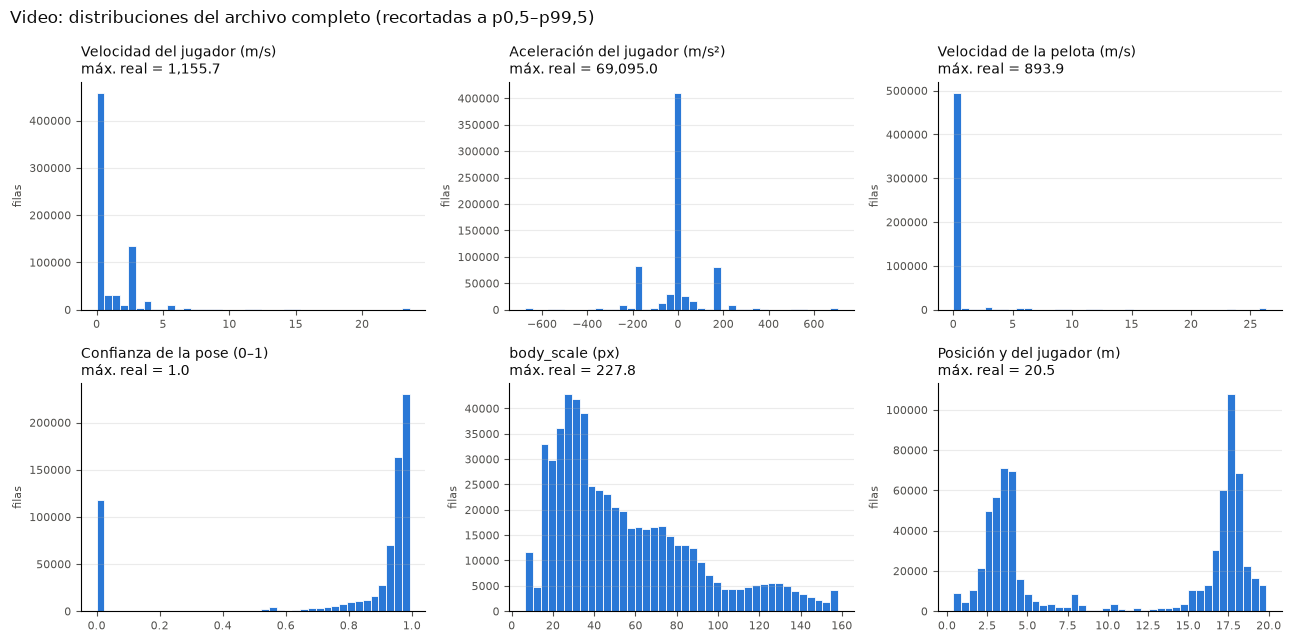

In [5]:
import matplotlib.pyplot as plt

VARIABLES_DIST = {
    'player_speed_mps': 'Velocidad del jugador (m/s)',
    'player_acceleration_mps2': 'Aceleración del jugador (m/s²)',
    'ball_speed_mps': 'Velocidad de la pelota (m/s)',
    'pose_confidence': 'Confianza de la pose (0–1)',
    'body_scale': 'body_scale (px)',
    'player_position_y': 'Posición y del jugador (m)',
}
dist = datos.leer_video(list(VARIABLES_DIST))
display(dist[list(VARIABLES_DIST)].describe(percentiles=[.01, .5, .99]).T.round(2))

COLOR, TINTA, TINTA_2 = '#2a78d6', '#0b0b0b', '#52514e'
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for eje, (col, titulo) in zip(ejes.flat, VARIABLES_DIST.items()):
    serie = dist[col].dropna()
    lo, hi = serie.quantile([0.005, 0.995])
    eje.hist(serie.clip(lo, hi), bins=40, color=COLOR, edgecolor='white', linewidth=0.6)
    eje.set_title(f'{titulo}\nmáx. real = {serie.max():,.1f}', fontsize=10, color=TINTA, loc='left')
    eje.tick_params(colors=TINTA_2, labelsize=8)
    eje.grid(axis='y', alpha=0.25)
    eje.spines[['top', 'right']].set_visible(False)
    eje.set_ylabel('filas', fontsize=8, color=TINTA_2)
fig.suptitle('Video: distribuciones del archivo completo (recortadas a p0,5–p99,5)', fontsize=12, color=TINTA, x=0.01, ha='left')
fig.tight_layout()
plt.show()

**Lectura**
- **Velocidad y aceleración del jugador:** son imposibles para una persona (máximos de 1.155,7 m/s y ±69.000 m/s²). El histograma muestra escalones discretos en 0, ~1,5 y ~3 m/s: es la cuantización de las posiciones (~5 cm) derivada frame a frame sin suavizar. Por eso se recalculan sobre la trayectoria suavizada (sección 1.8).
- **Velocidad de la pelota:** su mediana es 0 y su máximo 893,9 m/s; no sirve.
- **Confianza de la pose:** tiene un pico en 0 (frames sin pose) y el resto se concentra cerca de 0,95.
- **`body_scale`:** va de 3 a 228 px y está sesgada a la derecha según la distancia a la cámara, así que todo lo que se mide en píxeles debe normalizarse.
- **Posición `y`:** es bimodal, con un pico por cada fondo de la cancha.

### 1.2.4 Traza y formulario: tipos, faltantes y frecuencias

Las dos fuentes pequeñas se leen completas. En el formulario se omiten de las frecuencias las respuestas abiertas y los datos personales.

TRAZA (ambas canchas)


columna,ID_PARTIDO,ID_PUNTO,PUNTO_EQUIPO_1,PUNTO_EQUIPO_2,MARCADOR,ID_JUGADOR_1_EQUIPO_1,Equipo1_Banda1,ID_JUGADOR_2_EQUIPO_1,Equipo1_Banda2,ID_JUGADOR_1_EQUIPO_2,Equipo2_Banda1,ID_JUGADOR_2_EQUIPO_2,Equipo2_Banda2,EQUIPO_1_POSICION,EQUIPO_2_POSICION,POSICION_JUGADOR_1_EQUIPO_1,POSICION_JUGADOR_2_EQUIPO_1,POSICION_JUGADOR_1_EQUIPO_2,POSICION_JUGADOR_2_EQUIPO_2,cancha
tipo,int64,int64,int64,int64,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,int64
no_nulos,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283
faltantes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
pct_faltante,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
distintos,27,13,2,2,59,20,4,19,4,16,4,17,4,1,1,2,2,3,4,2


Puntos por partido:


ID_PARTIDO,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
cancha,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,13.0,13.0,10.0,10.0,NaN,11.0,NaN,11.0,8.0,NaN,NaN,9.0,NaN,NaN,8.0,NaN,12.0,NaN,9.0,NaN,12.0,11.0,NaN,NaN,7.0,10.0,10.0
2,NaN,NaN,NaN,NaN,10.0,NaN,11.0,NaN,NaN,10.0,13.0,NaN,10.0,11.0,NaN,13.0,NaN,10.0,NaN,7.0,NaN,NaN,12.0,12.0,NaN,NaN,NaN


EQUIPO_1_POSICION: {'BOTTOM': 283}
POSICION_JUGADOR_1_EQUIPO_1: {'RIGHT': 163, 'LEFT': 120}
POSICION_JUGADOR_2_EQUIPO_2: {'RIGHT': 150, 'LEFT': 121, 'RIGTH': 12}
Equipo1_Banda1: {'Light_Blue': 98, 'Yellow': 97, 'Orange': 66, 'Dark_Blue': 22}

FORMULARIO


,tipo,no_nulos,faltantes,pct_faltante,distintos
columna,,,,,
RITMO_CARDIACO,object,12,17,58.62,12
COMENTARIOS,object,28,1,3.45,24
Puntos_Total,float64,27,2,6.90,21
Partidos_Jugados,float64,27,2,6.90,5
Puntos_Por_Partido,float64,27,2,6.90,24


,count,mean,std,min,25%,50%,75%,max
EDAD,29.0,20.3,2.9,18.0,19.0,19.0,21.0,30.0
SEMESTRE,29.0,5.0,2.0,3.0,4.0,4.0,6.0,10.0
ESTATURA,29.0,171.8,11.9,150.0,165.0,173.0,179.0,194.0
TALLA,29.0,69.1,16.7,40.0,60.0,69.0,80.0,107.0
Puntos_Total,27.0,19.1,9.1,2.0,13.0,19.0,23.5,41.0
Partidos_Jugados,27.0,5.1,1.2,2.0,4.5,5.0,6.0,7.0
Puntos_Por_Partido,27.0,3.6,1.4,0.5,3.1,3.8,4.6,5.9


GENERO: {'Masculino': 18, 'Femenino': 11}
EXPERIENCIA_PADEL: {'No': 16, 'Sí': 13}
TIEMPO_JUGANDO_PADEL: {'Menos de 6 meses': 22, 'Entre 6 meses y 1 año': 5, 'Más de 1 año': 2}
PRACTICA_OTRO_DEPORTE_RAQUETA: {'No': 14, 'Tenis': 9, 'Tenis de mesa': 3, 'Squash': 2, 'Otro': 1}
NIVEL_ACTUAL_PADEL: {'Principiante': 12, 'Primera vez': 11, 'Intermedio': 5, 'Avanzado': 1}
ESTADO_FISICO: {'Bueno': 19, 'Excelente': 5, 'Regular': 4, 'Malo': 1}
FRECUENCIA_DEPORTE: {'Más de 4 veces': 9, '1-2 veces': 9, '3-4 veces': 7, '0 veces': 3, 'No practico deportes': 1}
MANO_DOMINANTE: {'Derecha': 27, 'Izquierda': 2}
LESIONES_LY: {'No': 22, 'Sí': 7}


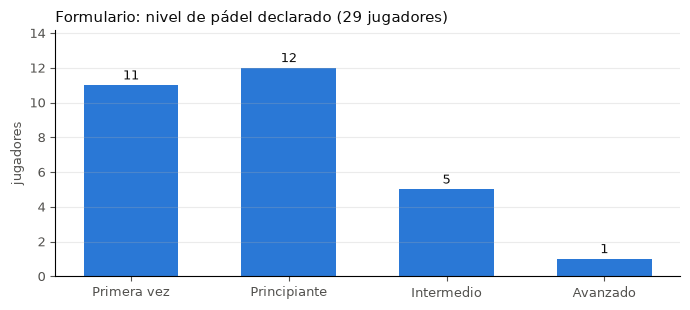

In [6]:
print('TRAZA (ambas canchas)')
display(datos.perfil_columnas(traza_cruda).T)
print('Puntos por partido:')
display(traza_cruda.groupby(['cancha', 'ID_PARTIDO']).size().rename('puntos').unstack(0).T)
for c in ['EQUIPO_1_POSICION', 'POSICION_JUGADOR_1_EQUIPO_1', 'POSICION_JUGADOR_2_EQUIPO_2', 'Equipo1_Banda1']:
    print(f'{c}:', traza_cruda[c].astype(str).str.strip().value_counts().to_dict())

print('\nFORMULARIO')
perfil_form = datos.perfil_columnas(form_crudo)
display(perfil_form[perfil_form['faltantes'] > 0])
display(form_crudo.select_dtypes('number').drop(columns=['CODIGO_ESTUDIANTE']).describe().T.round(1))
for c in ['GENERO', 'EXPERIENCIA_PADEL', 'TIEMPO_JUGANDO_PADEL', 'PRACTICA_OTRO_DEPORTE_RAQUETA', 'NIVEL_ACTUAL_PADEL',
          'ESTADO_FISICO', 'FRECUENCIA_DEPORTE', 'MANO_DOMINANTE', 'LESIONES_LY']:
    print(f'{c}:', form_crudo[c].value_counts(dropna=False).to_dict())

orden_nivel = ['Primera vez', 'Principiante', 'Intermedio', 'Avanzado']
nivel = form_crudo['NIVEL_ACTUAL_PADEL'].value_counts().reindex(orden_nivel, fill_value=0)
fig, eje = plt.subplots(figsize=(7, 3.2))
barras = eje.bar(nivel.index, nivel.values, color=COLOR, width=0.6)
eje.bar_label(barras, padding=2, fontsize=9, color=TINTA)
eje.set_ylim(0, nivel.max() * 1.18)
eje.set_title('Formulario: nivel de pádel declarado (29 jugadores)', fontsize=11, color=TINTA, loc='left')
eje.set_ylabel('jugadores', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=9)
eje.grid(axis='y', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Lectura**
- **Traza:** no tiene faltantes. El equipo 1 siempre está en BOTTOM y los lados aparecen con la errata `RIGTH`. Cada partido tiene entre 7 y 13 puntos.
- **Formulario:** solo tiene faltantes en `RITMO_CARDIACO` (descartada), `COMENTARIOS` y las 3 columnas de resultados (2 jugadores sin partidos). A diferencia de la versión CSV que leían los notebooks de entendimiento, en el Excel no aparece `#N/D` ni hay filas vacías de exportación.
- **Nivel:** el 79 % de los jugadores es principiante o juega por primera vez.
- **Mano:** solo hay 2 zurdos.

### 1.2.5 Relación entre las fuentes: nombres y llaves sin corregir

Antes de construir la tabla de equivalencias (1.3) se mide cuánto coinciden las fuentes tal como vienen: nombres exactos tras quitar tildes, espacios y mayúsculas, y la llave `(partido, punto)` del video contra `(ID_PARTIDO, ID_PUNTO)` de la traza.

In [7]:
nombres_form = set(form_crudo['NOMBRE'].map(idn.normalizar_nombre)) - {''}
nombres_traza_n = set(pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
                      .map(idn.normalizar_nombre)) - {''}
nombres_video_n = {idn.normalizar_nombre(n) for n in video['nombre_norm'].unique() if not idn.es_generico(n)}
display(pd.DataFrame([
    {'comparación': a, 'distintos_A': len(x), 'distintos_B': len(y), 'coincidencias_exactas': len(x & y)}
    for a, x, y in [('traza vs video', nombres_traza_n, nombres_video_n),
                    ('traza vs formulario', nombres_traza_n, nombres_form),
                    ('video vs formulario', nombres_video_n, nombres_form)]
]))
print('Nombres de la traza sin coincidencia exacta en el formulario:', sorted(nombres_traza_n - nombres_form))

llaves_video = set(map(tuple, video[['partido', 'punto']].drop_duplicates().to_numpy()))
llaves_traza = set(map(tuple, traza_cruda[['ID_PARTIDO', 'ID_PUNTO']].to_numpy()))
print(f'Llaves (partido, punto): video {len(llaves_video)} | traza {len(llaves_traza)} | en ambas {len(llaves_video & llaves_traza)}')
print('En el video y no en la traza:', sorted((int(a), int(b)) for a, b in llaves_video - llaves_traza))

,comparación,distintos_A,distintos_B,coincidencias_exactas
0,traza vs video,30,30,30
1,traza vs formulario,30,29,19
2,video vs formulario,30,29,19


Nombres de la traza sin coincidencia exacta en el formulario: ['alejandra briget deza cespedes', 'angie vanessa gonzalez farfan', 'isabella arenas', 'jose fabian garcia', 'juan andres ordonez vanegas', 'juan pablo vanegas herrera', 'laura sofia rodriguez gonzalez', 'miguel medina', 'nikol sofia avendano suarez', 'sofia santander', 'valentina rodriguez']


Llaves (partido, punto): video 272 | traza 283 | en ambas 268
En el video y no en la traza: [(7, 11), (11, 12), (23, 9), (32, 13)]


**Lectura**
- **Traza contra video:** los nombres coinciden 30 de 30, pero eso no garantiza que cada etiqueta esté en el jugador correcto; la sección 1.7 encuentra los partidos 8, 17 y 34 mal etiquetados.
- **Traza contra formulario:** solo coinciden 19 nombres. Ocho jugadores tienen variantes de nombre y 3 no llenaron el formulario; se resuelve en 1.3.
- **Llaves:** 268 puntos están en ambas fuentes.

### 1.2.6 Preguntas iniciales y su respuesta

Los notebooks de entendimiento cerraban con estas preguntas. Esta tabla las responde con lo encontrado en el resto de la Fase 1.

| Pregunta | Respuesta | Dónde |
|---|---|---|
| ¿Qué representa cada fila? | Video: un jugador en un frame. Traza: un punto. Formulario: un jugador. No hay filas repetidas en la llave del video. | 1.2.2 |
| ¿En qué sistema de coordenadas están las posiciones y en qué unidad? | Metros, por homografía a la cancha: `x` ∈ [0, 10], `y` ∈ [0, 20] y red en `y = 10`. BOTTOM está en `y > 10` y RIGHT en `x > 5` para ambos equipos (D13). Excepción: en el partido 17 la `y` es igual a `x` en todas las filas. | 1.6, 1.7 |
| ¿Cómo se codifican los booleanos y los indicadores de implausibilidad? | Como texto `True`/`False`. Los `*_implausible` solo existen en los partidos 10, 13 y 39; se descartan. | 1.2.2 |
| ¿Hay identificadores que separen partido, punto, jugador y video sin ambigüedad? | Track = `(partido, punto, player_id)`; jugador = `codigo` de 6 dígitos (D8). El nombre nunca es llave. | 1.3, 1.7 |
| ¿Sirven los nombres para unir las fuentes? | Solo a través de la tabla de equivalencias (D9). Video y traza coinciden en el texto, pero 3 partidos tienen etiquetas incorrectas (D12). | 1.3, 1.7 |
| ¿Cómo se construyen `partido` y `punto` y coinciden con la traza? | Son los mismos números de la traza: 268 puntos coinciden. 4 videos no tienen traza (D15) y 15 puntos de la traza no tienen video. El equipo confirmó que la numeración coincide. | 1.2.5, 1.7 |
| ¿Cómo tratar `#N/D`, faltantes, filas implausibles y pose ausente? | El Excel actual no tiene `#N/D`. Los faltantes del formulario se imputan (D4) y los de pose se interpolan en huecos de ≤5 frames. | 1.5, 1.8 |
| ¿En qué zona horaria está el formulario? | No importa: `Marca temporal` no se usa. | 1.5 |

### 1.2.7 Pelota: evidencia para descartarla

**Objetivo:** justificar con datos la decisión de no usar ninguna variable de la pelota.

**Qué significa que la posición de la pelota esté interpolada.** El pipeline de visión solo detecta la pelota en algunos frames. Para los demás no deja un faltante, sino que «rellena» la posición:
- entre dos detecciones traza una línea recta, de modo que la pelota avanza la misma distancia en cada frame (segunda diferencia igual a 0);
- antes de la primera detección y después de la última, repite la misma posición, de modo que la pelota aparece quieta.

Esas posiciones no son mediciones. Por eso `ball_speed_mps`, que se calcula frame a frame a partir de ellas, vale 0 cuando la pelota está «quieta» y da saltos imposibles (hasta 894 m/s) al pasar de un tramo inventado a una detección real. La celda clasifica cada frame según esas dos firmas y revisa si `player_hits_ball` coincide con un golpe real de raqueta.

,frames,pct
quieta (relleno),91925,50.5
posible detección,71543,39.3
tramo recto (interpolada),18417,10.1


,medida,valor
0,filas con player_hits_ball,2264.00
1,partidos con algún golpe,26.00
2,distancia mediana jugador–pelota en golpes (m),0.15
3,distancia mediana jugador–pelota en el resto (m),7.81
4,% de golpes con pico de raqueta (top 5 %) a ±5...,40.60
5,% de frames cualesquiera con pico a ±5 frames ...,21.60


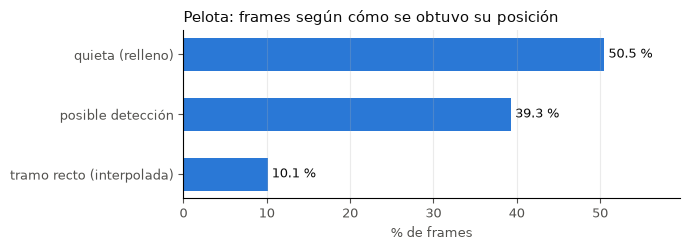

In [8]:
pelota = datos.leer_video(vid.COLUMNAS_PELOTA)
clases_pelota = vid.clasificar_frames_pelota(pelota)
display(clases_pelota)
display(vid.golpes_frente_a_picos(pelota))

fig, eje = plt.subplots(figsize=(7, 2.6))
orden_clases = clases_pelota.sort_values('pct')
barras = eje.barh(orden_clases.index, orden_clases['pct'], color=COLOR, height=0.55)
eje.bar_label(barras, labels=[f'{p:.1f} %' for p in orden_clases['pct']], padding=3, fontsize=9, color=TINTA)
eje.set_xlim(0, orden_clases['pct'].max() * 1.18)
eje.set_title('Pelota: frames según cómo se obtuvo su posición', fontsize=11, color=TINTA, loc='left')
eje.set_xlabel('% de frames', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=9)
eje.grid(axis='x', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
del pelota

**Lectura y decisión (D24)**
- **Posiciones:** el 50,5 % de los frames tiene la pelota quieta (relleno) y otro 10,1 % está en un tramo perfectamente recto (interpolación lineal). Cerca del 61 % de las posiciones no son detecciones reales, y en el 39 % restante no se puede saber cuáles lo son.
- **`player_hits_ball`:** se activa cuando la pelota está a ~0,15 m del jugador (frente a 7,8 m en el resto de frames). Es decir, se deriva de esa misma posición inventada.
- **Coincidencia con golpes reales:** solo el 41 % de esos «golpes» tiene un pico de velocidad de raqueta a ±5 frames, frente a un 22 % que se daría al azar.
- **Decisión:** se descartan todas las variables de la pelota, incluida `player_hits_ball`. Los golpes se aproximan con picos de la velocidad de raqueta normalizada por `body_scale`, que se mide sobre el jugador y no depende de la pelota (sección 1.8).

### 1.2.8 Atípicos y faltantes de las variables físicas

**Objetivo:** revisar que velocidad, aceleración, velocidad de raqueta y velocidades angulares estén en rangos posibles para una persona que juega pádel. Aquí solo se diagnostica; la corrección se aplica en la limpieza (1.8). No existe una variable de «fuerza» en los datos.

**Decisión D23: límites**

| Variable | Límite | Criterio |
|---|---|---|
| Velocidad del jugador | 8 m/s | Físico: por encima de lo que alcanza un jugador de pádel |
| Aceleración del jugador | 10 m/s² | Físico |
| Velocidades angulares (codo y raqueta) | 3.000 °/s | Físico |
| Velocidades en píxeles (raqueta, muñeca y codo) ÷ `body_scale` | Percentil 99,5 de cada jugador | Estadístico: no tienen unidad física directa |

- **Tratamiento:** el valor fuera de límite pasa a NaN; si el hueco es de ≤5 frames se interpola y, si es más largo, queda NaN. Se guarda el % de frames corregidos por jugador y punto.
- La velocidad y la aceleración se evalúan sobre la trayectoria suavizada (media móvil de 0,5 s), porque las columnas originales son ruido de cuantización.

In [9]:
fisicas = datos.leer_video(vid.COLUMNAS_ATIPICOS)
atipicos = vid.diagnosticar_atipicos(fisicas)
display(atipicos)
del fisicas

,variable,criterio,limite,pct_faltante,p50,p99,max,pct_sobre_limite
0,player_speed_mps (cruda),físico,8.0,0.2,0.00,11.37,1155.7,1.64
1,player_acceleration_mps2 (cruda),físico,10.0,0.3,1.85,702.44,69095.0,44.64
2,velocidad suavizada 0.5 s,físico,8.0,0.2,0.37,7.10,38.3,0.76
3,aceleración suavizada 0.5 s,físico,10.0,0.3,0.31,11.92,75.9,1.45
4,elbow_angular_velocity (°/s),físico,3000.0,22.4,67.63,1623.07,10477.6,0.20
5,racket_angular_velocity (°/s),físico,3000.0,23.6,79.15,3097.08,10788.0,1.05
6,vel_raqueta_norm (racket_speed / body_scale),"percentil 99,5 (global; por jugador en 1.8)",73.0,24.1,2.76,51.85,2486.5,0.50
7,vel_muneca_norm (wrist_speed / body_scale),"percentil 99,5 (global; por jugador en 1.8)",43.4,23.0,1.81,31.00,2336.0,0.50
8,vel_codo_norm (elbow_speed / body_scale),"percentil 99,5 (global; por jugador en 1.8)",36.4,21.8,1.73,27.06,2253.1,0.50


**Lectura**
- **Velocidad y aceleración crudas:** son inservibles. La aceleración supera 10 m/s² en el 45 % de las filas y llega a 69.095 m/s²; la velocidad supera 8 m/s en el 1,6 % y llega a 1.156 m/s.
- **Tras suavizar 0,5 s:** solo el 0,8 % de las velocidades y el 1,5 % de las aceleraciones quedan fuera de límite, y su mediana (0,37 m/s) es la de un jugador que se desplaza poco entre golpes. Lo que queda fuera son saltos del tracking (hasta 38 m/s), que la limpieza corrige.
- **Velocidades angulares:** superan 3.000 °/s en el 0,2 % (codo) y el 1,1 % (raqueta) de los frames con pose.
- **Velocidades en píxeles normalizadas:** tienen colas enormes (máximos de más de 2.000 cuerpos/s, frente a un p99 de 27–52), que corresponden a saltos de los puntos de pose.
- **Faltantes:** las variables de pose y raqueta faltan en el 22–24 % de las filas, igual que la pose en general (1.2.2).

### 1.2.9 Resumen de hallazgos y su tratamiento

| Tema | Hallazgo | Tratamiento |
|---|---|---|
| Grano | Una fila es un jugador en un frame; no hay duplicados en la llave. | Base del pipeline |
| fps | Variable por video: 24, 30 y 60 fps (algunos 59,9). El partido 32 tiene 300 frames por punto con fps de 11,8 a 39,9. | fps = 1/`duration` por punto (D2) |
| Velocidad y aceleración | Muy ruidosas, con máximos imposibles; la aceleración cruda supera 10 m/s² en el 45 % de las filas. | Límites físicos (D23) y recálculo sobre la trayectoria suavizada (1.8) |
| Pose y raqueta | Cerca del 20 % de faltantes; según el partido va de 0 % a 100 %. | Interpolar huecos de ≤5 frames y guardar `pose_coverage` (1.8) |
| Pelota | ~61 % de los frames son relleno o interpolación; `player_hits_ball` depende de esa posición. | Se descarta toda la familia (D24); golpes = picos de velocidad de raqueta |
| `team` | 8,3 % de faltantes; 100 % en los partidos 8 y 34. | Completar con el valor del jugador (1.8) |
| `*_implausible` | Solo en los partidos 10, 13 y 39. | No se usan |
| Atípicos físicos | Saltos del tracking y de la pose fuera de los límites humanos. | NaN y reconstrucción en huecos ≤5 frames (D23, 1.8) |
| Nombres | Coinciden entre traza y video, pero no con el formulario. | Tabla de equivalencias (1.3) e identidad por track (1.7) |
| Formulario | 29 filas; 3 jugadores sin formulario y 2 personas que no juegan. | Imputación (1.5) |

## 1.3 Identidad de los jugadores: códigos y nombres

**Objetivo:** una tabla única de equivalencias que lleve cualquier nombre de cualquier fuente a su nombre canónico y a su `codigo`.

**Decisiones**
- **D4 (códigos):** el equipo entregó los códigos de quienes no llenaron el formulario: Alejandra Briget Deza Céspedes (407710), Juan Pablo Vanegas Herrera (356629) y Laura Sofía Rodríguez González (324764).
- **D8:** todos los códigos tienen 6 dígitos. Jorge García pasa de 99999 a `099999` (se antepone un 0) y José Fabián García Camargo pasa de 1075684546 a `107568` (primeros 6 dígitos). El código se guarda como texto para conservar el cero inicial.
- **D9:** las variantes de nombre son el mismo jugador (no se separan en seguras y dudosas). Se usa el nombre completo con dos apellidos cuando alguna fuente lo tiene. Ejemplos: `Isabella Arenas` → *Isabella Arenas González* y `Sofia Santander` → *Ana Sofía Santander Prieto*.
- **Proceso recurrente (Teams):** si un nombre queda sin cruzar, se lista aquí para buscarlo en Teams; luego se agrega a `NOMBRES_CANONICOS` en `src/identidades.py` y se vuelve a correr.

In [10]:
codigos = idn.tabla_codigos(form_crudo)
nombres_traza = pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
equivalencias = idn.tabla_equivalencias(
    {'formulario': form_crudo['NOMBRE'], 'traza': nombres_traza, 'video': video['nombre_norm'].unique()}, codigos)

print('Códigos corregidos (D8):')
display(form_crudo.loc[form_crudo['CODIGO_ESTUDIANTE'].astype(str).isin(idn.CORRECCIONES_CODIGO), ['NOMBRE', 'CODIGO_ESTUDIANTE']]
        .assign(codigo=lambda d: d['CODIGO_ESTUDIANTE'].map(idn.normalizar_codigo)))
print('Cruces por alias (variantes del mismo nombre, D9):')
display(equivalencias[equivalencias['tipo_cruce'] == 'alias'])

resumen_cruce = equivalencias.pivot_table(index='fuente', columns='tipo_cruce', values='nombre_original', aggfunc='count', fill_value=0)
display(resumen_cruce)
pendientes_teams = idn.sin_cruzar(equivalencias)
print(f'Nombres sin cruzar (buscar en Teams): {len(pendientes_teams)}')
display(pendientes_teams)
print('Nombres canónicos con un solo apellido (ninguna fuente trae el nombre completo):')
print([n for n in codigos['nombre'] if len(n.split()) == 2])
datos.guardar_tabla(equivalencias, 'equivalencias_nombres')

Códigos corregidos (D8):


,NOMBRE,CODIGO_ESTUDIANTE,codigo
12,Jorge Garcia,99999,099999
13,Jose Fabian Garcia Camargo,1075684546,107568


Cruces por alias (variantes del mismo nombre, D9):


,fuente,nombre_original,nombre,tipo_cruce,codigo
6,traza,Sofia Santander,Ana Sofía Santander Prieto,alias,326450
7,video,sofia santander,Ana Sofía Santander Prieto,alias,326450
14,formulario,Angie vanessa gonzalez 0,Angie Vanessa González Farfan,alias,350977
33,traza,Isabella Arenas,Isabella Arenas González,alias,350430
34,video,isabella arenas,Isabella Arenas González,alias,350430
45,traza,Jose Fabian Garcia,Jose Fabian Garcia Camargo,alias,107568
46,video,jose fabian garcia,Jose Fabian Garcia Camargo,alias,107568
47,formulario,Juan Andrés Ordóñez,Juan Andrés Ordóñez Vanegas,alias,196393
75,traza,Miguel Medina,Miguel Medina Velez,alias,351752
76,video,miguel medina,Miguel Medina Velez,alias,351752


tipo_cruce,alias,exacto
fuente,,
formulario,3,26
traza,5,25
video,5,25


Nombres sin cruzar (buscar en Teams): 0


,fuente,nombre_original,nombre,tipo_cruce,codigo


Nombres canónicos con un solo apellido (ninguna fuente trae el nombre completo):
['Jeronimo Coy', 'Jorge García', 'Juliana Gómez', 'Marcela Velásquez', 'Miguel Delgado']


WindowsPath('C:/Users/Usuario/Documents/UNIVERSIDAD/QUINTO SEMESTRE/ANALISIS DE DATOS/TERCER CORTE/PROYECTO FINAL ANALITICA PADEL/Proyecto_final_analitica/data/interim/equivalencias_nombres.csv')

**Resultado**
- Hay 32 personas con código: los 29 del formulario y los 3 de la D4. De ellas, 30 juegan en la traza.
- Ningún nombre de ninguna fuente queda sin cruzar, así que hoy no hay pendientes para Teams. Ocho jugadores tienen variantes de nombre, que suman 13 nombres cruzados por alias.
- Cinco jugadores tienen un solo apellido en todas las fuentes (por ejemplo, Juliana Gómez y Miguel Delgado). Se mantienen así; si se quiere el segundo apellido, hay que buscarlo en Teams.
- Salida: `data/interim/equivalencias_nombres.csv`.

## 1.4 Traza de partidos

**Objetivo:** dejar la traza limpia por punto, con los códigos de los cuatro jugadores, y su versión larga jugador × punto (`participaciones`).

**Decisiones**
- **D3:** la variable objetivo es el ganador del punto, `PUNTO_EQUIPO_1`.
- **D13:** se corrige la errata `RIGTH` → `RIGHT` (partido 34). La convención de lados se verificó contra el video (sección 1.7): `BOTTOM` está en `y > 10` y, para ambos equipos, `RIGHT` está en `x > 5`.
- **Lado de cancha:** el equipo 1 siempre está en BOTTOM. Se incluye como variable de control, sin sacar conclusiones fuertes.

In [11]:
print('Controles de consistencia sobre la traza cruda:')
display(fuentes.validar_traza(traza_cruda))
lados_crudos = pd.concat([traza_cruda[f'POSICION_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS]).str.strip().value_counts()
print('Valores de lado en la traza cruda:', lados_crudos.to_dict())

traza = fuentes.limpiar_traza(traza_cruda, codigos)
participaciones = fuentes.traza_larga(traza)
puntos_traza = fuentes.tabla_puntos_traza(traza)
display(datos.comparar(datos.resumen_tabla(traza_cruda, 'traza cruda'), datos.resumen_tabla(traza, 'traza limpia'),
                       datos.resumen_tabla(participaciones, 'participaciones (jugador × punto)')))
assert participaciones['codigo'].notna().all()

finales = traza.groupby('ID_PARTIDO').agg(cancha=('cancha', 'first'), puntos=('ID_PUNTO', 'size'), marcador_final=('MARCADOR', 'last'))
print('Todos los partidos terminan cuando un equipo llega a 7:',
      finales['marcador_final'].str.split('-').map(lambda m: max(map(int, m)) == 7).all())
display(finales.T)

print(f"Balance de la variable objetivo: el equipo 1 gana el {traza['PUNTO_EQUIPO_1'].mean():.1%} de {len(traza)} puntos")
sin_traza = sorted(set(programacion['Partido']) - set(traza['ID_PARTIDO']))
print(f'Partidos programados sin traza ({len(sin_traza)}): {sin_traza}')

Controles de consistencia sobre la traza cruda:


,filas con problema
PUNTO_EQUIPO_1 + PUNTO_EQUIPO_2 != 1,0
partido-punto duplicado,0
MARCADOR distinto del acumulado,0
ID_PUNTO no consecutivo,0
lado LEFT/RIGHT cambia dentro del partido,0


Valores de lado en la traza cruda: {'LEFT': 566, 'RIGHT': 554, 'RIGTH': 12}


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,traza cruda,283,20,0,0.0
1,traza limpia,283,28,0,0.0
2,participaciones (jugador × punto),1132,12,0,0.0


Todos los partidos terminan cuando un equipo llega a 7: True


ID_PARTIDO,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
cancha,1,1,1,1,2,1,2,1,1,2,2,1,2,2,1,2,1,2,1,2,1,1,2,2,1,1,1
puntos,13,13,10,10,10,11,11,11,8,10,13,9,10,11,8,13,12,10,9,7,12,11,12,12,7,10,10
marcador_final,6-7,6-7,3-7,3-7,3-7,7-4,4-7,4-7,1-7,3-7,6-7,7-2,3-7,7-4,1-7,7-6,5-7,3-7,7-2,0-7,7-5,7-4,7-5,5-7,0-7,7-3,3-7


Balance de la variable objetivo: el equipo 1 gana el 43.1% de 283 puntos
Partidos programados sin traza (12): [2, 4, 6, 12, 15, 19, 21, 22, 30, 33, 36, 38]


**Resultado**
- La traza pasa todos los controles: un ganador por punto, sin duplicados, marcador igual al acumulado, puntos consecutivos y lados fijos dentro de cada partido.
- Todos los partidos terminan cuando un equipo llega a 7.
- El equipo 1 gana el 43,1 % de los puntos, así que las clases están moderadamente balanceadas.
- Los 12 partidos programados sin traza (2, 4, 6, 12, 15, 19, 21, 22, 30, 33, 36 y 38) no tienen tampoco video y no entran al análisis.

## 1.5 Formulario de jugadores

**Objetivo:** una fila por jugador con las variables fijas usables, codificadas, más los 3 jugadores imputados.

**Decisiones**
- **D1:** `TALLA` es el peso en kg. IMC = peso / (estatura en m)².
- **D4 (imputación):** los 3 jugadores sin formulario se imputan con datos de su mismo sexo.
  - Continuas (edad, estatura y peso): media. A las dos mujeres se les suma ruido N(0, sd de las mujeres) con semilla fija y se recorta al rango observado.
  - Ordinales: mediana; si cae entre dos categorías, se toma la inferior.
  - Categóricas: moda.
  - Las filas imputadas llevan `imputado = True`.
- **D5:** resuelta. La fila de 152 cm y 48 kg corresponde a Ana Catalina Suárez Caballero (código 337448) y ya viene con nombre en el formulario actual.
- **D11:** codificación ordinal (0 = menor):
  - nivel: Primera vez < Principiante < Intermedio < Avanzado.
  - tiempo jugando: <6 meses < 6–12 meses < >1 año.
  - experiencia: No < Sí.
  - estado físico: Malo < Regular < Bueno < Excelente.
  - frecuencia: 0 < 1–2 < 3–4 < >4 veces por semana.

  Como `TIEMPO_JUGANDO_PADEL` es categórica, se imputa como ordinal (mediana) y no con la media.
- **D10 (confirmada):** en `FRECUENCIA_DEPORTE`, las respuestas «0 veces» y «No practico deportes» se unen en el nivel 0.
- **`RITMO_CARDIACO`:** se descarta; tiene pocos datos (12 de 29) y no interesa para el análisis (confirmado por el equipo).
- **Descartadas:** ciudad, programa, semestre, razón y objetivo de participación, interés y clases de pádel, desayuno, género musical, comentarios y `RITMO_CARDIACO`.
- **Fuga de datos:** `Puntos_Total`, `Partidos_Jugados` y `Puntos_Por_Partido` no entran a la tabla; solo se usan abajo para validar la traza.

In [12]:
jugadores_base = fuentes.limpiar_formulario(form_crudo)
jugadores = fuentes.agregar_derivadas_jugadores(fuentes.imputar_sin_formulario(jugadores_base, datos.SEMILLA))
display(datos.comparar(datos.resumen_tabla(form_crudo, 'formulario crudo'),
                       datos.resumen_tabla(jugadores_base, 'formulario limpio'),
                       datos.resumen_tabla(jugadores, 'jugadores (con imputados y derivadas)')))

print('Jugadores imputados (D4):')
display(jugadores[jugadores['imputado']])
print('Rangos de las continuas:')
display(jugadores[['edad', 'estatura_cm', 'peso_kg', 'imc']].astype(float).describe().T.round(1))

juegan = set(participaciones['codigo'])
print(f'Jugadores de la traza con datos: {len(juegan & set(jugadores["codigo"]))} de {len(juegan)}')
print('En el formulario pero sin partidos con traza:', jugadores.loc[~jugadores['codigo'].isin(juegan), 'nombre'].tolist())
datos.guardar_tabla(jugadores, 'jugadores')

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,formulario crudo,29,30,24,2.76
1,formulario limpio,29,15,0,0.00
2,jugadores (con imputados y derivadas),32,20,0,0.00


Jugadores imputados (D4):


,codigo,nombre,genero,mujer,edad,estatura_cm,peso_kg,imc,mano_dominante,zurdo,nivel_padel,tiempo_jugando_padel,experiencia_padel,otro_deporte_raqueta,practica_otra_raqueta,estado_fisico,frecuencia_deporte,lesiones_ly,lesion_ultimo_anio,imputado
0,407710,Alejandra Briget Deza Céspedes,Femenino,1,19,162,40.0,15.24,Derecha,0,1,0,0,No,0,2,2,No,0,True
18,356629,Juan Pablo Vanegas Herrera,Masculino,0,20,179,76.8,23.97,Derecha,0,1,0,0,Tenis,1,2,2,No,0,True
22,324764,Laura Sofía Rodríguez González,Femenino,1,24,165,51.9,19.06,Derecha,0,1,0,0,No,0,2,2,No,0,True


Rangos de las continuas:


,count,mean,std,min,25%,50%,75%,max
edad,32.0,20.4,2.9,18.0,19.0,19.0,21.2,30.0
estatura_cm,32.0,171.5,11.6,150.0,164.5,173.0,179.0,194.0
peso_kg,32.0,67.9,17.0,40.0,55.5,68.5,80.0,107.0
imc,32.0,22.8,3.9,15.2,20.4,22.5,25.0,32.8


Jugadores de la traza con datos: 30 de 30
En el formulario pero sin partidos con traza: ['Juan Camilo Sánchez', 'Karol Valentina Carranza Gantiva']


WindowsPath('C:/Users/Usuario/Documents/UNIVERSIDAD/QUINTO SEMESTRE/ANALISIS DE DATOS/TERCER CORTE/PROYECTO FINAL ANALITICA PADEL/Proyecto_final_analitica/data/interim/jugadores.csv')

**Validación con las columnas de fuga.** Se recalcula desde la traza la suma de puntos que hizo el equipo de cada jugador en sus partidos y se compara con `Puntos_Total` y `Partidos_Jugados`. No entran a ningún modelo.

In [13]:
puntos_traza_jugador = (participaciones.groupby(['codigo', 'partido'])['gano_punto'].sum()
                        .groupby('codigo').agg(puntos_desde_traza='sum', partidos_con_traza='size'))
validacion = (form_crudo[['NOMBRE', 'Puntos_Total', 'Partidos_Jugados']]
              .assign(codigo=form_crudo['CODIGO_ESTUDIANTE'].map(idn.normalizar_codigo))
              .merge(puntos_traza_jugador, on='codigo', how='left'))
validacion['coincide_puntos'] = validacion['Puntos_Total'] == validacion['puntos_desde_traza']
validacion['coincide_partidos'] = validacion['Partidos_Jugados'] == validacion['partidos_con_traza']
con_dato = validacion['Puntos_Total'].notna()
print(f"Jugadores con Puntos_Total: {con_dato.sum()} | coincide con la traza: {validacion.loc[con_dato, 'coincide_puntos'].sum()}"
      f" | Partidos_Jugados coincide: {validacion.loc[con_dato, 'coincide_partidos'].sum()}")
print('Diferencias:')
display(validacion[con_dato & ~(validacion['coincide_puntos'] & validacion['coincide_partidos'])])

Jugadores con Puntos_Total: 27 | coincide con la traza: 27 | Partidos_Jugados coincide: 2
Diferencias:


,NOMBRE,Puntos_Total,Partidos_Jugados,codigo,puntos_desde_traza,partidos_con_traza,coincide_puntos,coincide_partidos
0,Ana Sofía Santander Prieto,4.0,5.0,326450,4.0,2.0,True,False
1,Andrés Felipe Santafe Buitrago,41.0,7.0,352369,41.0,6.0,True,False
2,Angel Santiago Toribio Godoy,27.0,6.0,349345,27.0,5.0,True,False
3,Angie vanessa gonzalez 0,22.0,6.0,350977,22.0,4.0,True,False
4,Antonio Benitez Rueda,24.0,7.0,334943,24.0,4.0,True,False
5,David Jeronimo Rojas Gutierrez,12.0,5.0,376184,12.0,4.0,True,False
6,David Neisa Tello,17.0,6.0,349342,17.0,4.0,True,False
7,Gabriel Armando González Sosa,25.0,5.0,323614,25.0,4.0,True,False
8,Gabriel López Acosta,20.0,5.0,367769,20.0,4.0,True,False
9,Isabella Arenas González,2.0,4.0,350430,2.0,2.0,True,False


**Resultado**
- La tabla de jugadores tiene 32 filas (29 del formulario más 3 imputados) y sus variables usables no tienen faltantes.
- Los 30 jugadores de la traza tienen datos. Juan Camilo Sánchez y Karol Carranza no juegan ningún partido con traza.
- **Validación:** `Puntos_Total` coincide con la traza en los 27 jugadores que tienen el dato, lo que confirma la traza y el cruce de códigos. En cambio, `Partidos_Jugados` es mayor que los partidos con traza: cuenta partidos programados sin traza que no aportan puntos al total.
- Salida: `data/interim/jugadores.csv`.

## 1.6 Video: diagnóstico de calidad por punto

**Objetivo:** detectar automáticamente, para cada punto de video, los problemas que afectan la limpieza y el modelado. La detección funciona igual para cualquier video nuevo.

**Decisiones**
- **D6:** los CSV de video se reciben ya generados; no se usa el pipeline de visión del profesor.
- **D7:** el punto 10 del partido 5 es una copia exacta del punto 9. Se conserva el video como punto 9 y el punto 10 queda sin video. La regla general es conservar el de menor número; cualquier duplicado nuevo se revisa con el equipo.
- **D26 y D30:** no hay tratamientos por partido; solo reglas generales y solo conclusiones que el código demuestra.
- Banderas que se calculan por punto:

| Bandera | Regla |
|---|---|
| `y_invalida` | `y` = `x` en más del 95 % de las filas |
| `sin_pose` | 0 % de frames con pose |
| `duplicado_de_punto` | firma idéntica a otro punto del mismo partido |

In [14]:
diagnostico = vid.diagnosticar_puntos(video)
banderas = ['y_invalida', 'sin_pose']
por_partido = diagnostico.groupby('partido').agg(
    puntos=('punto', 'size'), fps=('fps', 'median'), pct_pose_medio=('pct_pose', 'mean'),
    pct_team_faltante=('pct_team_faltante', 'mean'), pct_fuera_cancha=('pct_fuera_cancha', 'mean'),
    tracks_genericos=('tracks_genericos', 'sum'), duplicados=('duplicado_de_punto', 'count'),
    **{b: (b, 'sum') for b in banderas}).round(1)
display(por_partido)
print('Partidos con alguna bandera o duplicado:')
display(por_partido[(por_partido[banderas + ['duplicados']] > 0).any(axis=1)])

,puntos,fps,pct_pose_medio,pct_team_faltante,pct_fuera_cancha,tracks_genericos,duplicados,y_invalida,sin_pose
partido,,,,,,,,,
1,11,60.0,59.1,5.4,0.9,3,0,0,0
3,8,60.0,81.8,3.6,0.1,4,0,0,0
5,10,24.0,92.7,1.4,0.3,4,1,0,0
7,11,24.0,87.3,0.2,0.2,1,0,0,0
8,8,30.0,100.0,100.0,2.1,0,0,0,0
9,11,30.0,93.0,7.0,0.3,5,0,0,0
10,11,60.0,92.2,12.6,2.2,0,0,0,0
11,12,30.0,96.0,0.9,0.2,5,0,0,0
13,7,30.0,98.2,15.2,0.1,0,0,0,0


Partidos con alguna bandera o duplicado:


,puntos,fps,pct_pose_medio,pct_team_faltante,pct_fuera_cancha,tracks_genericos,duplicados,y_invalida,sin_pose
partido,,,,,,,,,
5,10,24.0,92.7,1.4,0.3,4,1,0,0
17,9,30.0,0.0,60.9,4.9,79,0,9,9


**Resultado: partidos con problemas de calidad**

| Partido | Problema | Consecuencia para el análisis |
|---|---|---|
| 5 | El punto 10 es una copia del punto 9 | El punto 10 queda sin video (D7) |
| 8 y 34 | Solo se detecta la pareja del fondo BOTTOM (cámara de media cancha) y `team` está vacío | No hay video del equipo 2: sus puntos quedan fuera del modelo pareja contra pareja (D20) |
| 17 | `y` es copia de `x` y no hay pose en ningún frame; las etiquetas son `Jugador 1–4` | Sin tratamiento especial (D26): la regla general de `y` inválida deja NaN su profundidad y su velocidad |

## 1.7 Video: cruce con la traza e identidad de cada track

**Objetivo:** asignar a cada track `(partido, punto, player_id)` el `codigo` del jugador, de acuerdo con la traza.

**Decisiones**
- **D12:** se confía en la etiqueta de nombre del video si en el partido al menos el 50 % de las filas tiene nombres de la alineación de la traza y al menos el 80 % concuerda con la casilla (fondo, lado) que indica la traza.
  - Si no se cumple, la identidad se asigna **por posición contra la traza**. Para el fondo se usa `team` (o `y > 10` cuando `team` falta) y para el lado `x > 5`.
  - Se asigna de forma codiciosa: cada casilla recibe el track con mayor filas × p(fondo) × p(lado).
- **D14:** los tracks genéricos (`Player_N`) y los que quedan sin casilla compatible se descartan de la identidad.
- **D15:** los 4 puntos de video sin traza (7-11, 11-12, 23-9 y 32-13) se excluyen, porque según la traza esos partidos ya habían terminado. El equipo confirmó que la numeración de puntos del video coincide con la de la traza.

In [15]:
tracks = vid.resumir_tracks(video, diagnostico)
metodo_partido = vid.concordancia_por_partido(tracks, participaciones, diagnostico)
print('Concordancia de las etiquetas de nombre con la traza, por partido:')
display(metodo_partido)

identidades = vid.asignar_identidades(tracks, participaciones, diagnostico, metodo_partido)
print('Tracks y filas por resultado de la asignación:')
display(identidades.groupby(['conservar', 'metodo', 'motivo'], dropna=False)
        .agg(tracks=('filas', 'size'), filas=('filas', 'sum')).reset_index())
etq = identidades[identidades['metodo'] == 'etiqueta']
print(f"Con método etiqueta, el {np.average(etq['concuerda_posicion'].astype(float), weights=etq['filas']):.1%} "
      'de las filas también concuerda con la posición de la traza.')

Concordancia de las etiquetas de nombre con la traza, por partido:


,partido,filas,pct_filas_en_alineacion,pct_concordancia_posicion,metodo
0,1,75217.0,99.8,100.0,etiqueta
1,3,54222.0,100.0,100.0,etiqueta
2,5,12734.0,98.6,100.0,etiqueta
3,7,9137.0,100.0,100.0,etiqueta
4,8,6850.0,0.0,NaN,posicion
5,9,15487.0,99.4,96.9,etiqueta
6,10,27762.0,100.0,100.0,etiqueta
7,11,13606.0,99.7,100.0,etiqueta
8,13,14089.0,100.0,100.0,etiqueta
9,14,33254.0,99.0,97.4,etiqueta


Tracks y filas por resultado de la asignación:


,conservar,metodo,motivo,tracks,filas
0,False,NaN,punto sin traza,16,4044
1,False,NaN,sin casilla libre compatible,47,3300
2,False,NaN,track genérico sin identidad,105,3772
3,False,NaN,video duplicado del punto 9,4,1932
4,True,etiqueta,NaN,952,673335
5,True,posicion,NaN,77,32553


Con método etiqueta, el 99.0% de las filas también concuerda con la posición de la traza.


**Partidos asignados por posición.** La tabla cruza la etiqueta original del video con la identidad asignada (número de puntos).

In [16]:
reasignados = identidades[identidades['conservar'] & (identidades['metodo'] == 'posicion')]
for p, g in reasignados.groupby('partido'):
    print(f'\nPartido {p}:')
    display(pd.crosstab(g['etiqueta_video'], g['nombre']))


Partido 8:


nombre,Angel Santiago Toribio Godoy,Mariana Alfonso Forero
etiqueta_video,,
david neisa tello,2,6
jose fabian garcia,6,2



Partido 17:


nombre,Isabella Arenas González,Jeronimo Coy,Juliana Gómez,Luis Felipe Cuellar Santamaria
etiqueta_video,,,,
jugador 1,0,0,9,0
jugador 2,9,0,0,0
jugador 3,0,9,0,0
jugador 4,0,0,0,9



Partido 34:


nombre,Alejandra Briget Deza Céspedes,David Neisa Tello,Jeronimo Coy,Jose Fabian Garcia Camargo
etiqueta_video,,,,
alejandra briget deza cespedes,0,2,0,0
david neisa tello,11,0,0,0
jeronimo coy,0,0,1,0
jose fabian garcia,0,0,0,11


**Tabla de puntos** (una fila por punto): une la traza y el video e indica el estado del video y cuántos jugadores quedaron identificados por equipo.

In [17]:
puntos = vid.tabla_puntos(puntos_traza, diagnostico, identidades)
participaciones = vid.enlazar_participaciones(participaciones, identidades)

display(datos.comparar(datos.resumen_tabla(puntos, 'puntos'), datos.resumen_tabla(participaciones, 'participaciones'),
                       datos.resumen_tabla(identidades, 'identidades_video')))
print('Estado del video por punto:', puntos['estado_video'].value_counts().to_dict())
disp = puntos[puntos['estado_video'] == 'disponible']
print('Puntos con video disponible por jugadores identificados (equipo 1 × equipo 2):')
display(pd.crosstab(disp['identificados_e1'], disp['identificados_e2']))

cobertura_partido = puntos[puntos['en_traza']].groupby('partido').agg(
    puntos_traza=('punto', 'size'), con_video=('estado_video', lambda s: (s == 'disponible').sum()),
    equipos_completos=('equipos_completos', 'sum'))
display(cobertura_partido.T)

for nombre, tabla in [('identidades_video', identidades), ('puntos', puntos), ('participaciones', participaciones)]:
    print('Guardado:', datos.guardar_tabla(tabla, nombre).relative_to(RAIZ))

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,puntos,287,29,494,5.94
1,participaciones,1132,15,206,1.21
2,identidades_video,1201,21,2312,9.17


Estado del video por punto: {'disponible': 267, 'sin video': 15, 'video sin traza': 4, 'duplicado': 1}
Puntos con video disponible por jugadores identificados (equipo 1 × equipo 2):


identificados_e2,0,1,2
identificados_e1,,,
2,16,7,244


partido,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
puntos_traza,13,13,10,10,10,11,11,11,8,10,13,9,10,11,8,13,12,10,9,7,12,11,12,12,7,10,10
con_video,11,8,9,10,8,11,11,11,7,9,11,9,10,10,8,13,12,10,9,7,12,11,12,11,7,10,10
equipos_completos,11,8,9,10,0,11,11,11,7,9,11,9,10,10,7,13,12,10,6,7,12,11,12,0,7,10,10


Guardado: data\interim\identidades_video.csv
Guardado: data\interim\puntos.csv
Guardado: data\interim\participaciones.csv


**Resultado**
- Las etiquetas de nombre son confiables en 24 de los 27 partidos: con ellas, el 99 % de las filas concuerda con la casilla de la traza.
- Los partidos 8, 17 y 34 se reasignan por posición:
  - **8:** el video tenía los nombres del partido 34. Los dos jugadores del fondo BOTTOM son Angel Toribio (RIGHT) y Mariana Alfonso (LEFT).
  - **17:** `Jugador 1–4` corresponden a Juliana Gómez (top-left), Isabella Arenas (top-right), Jerónimo Coy (bottom-left) y Luis Felipe Cuéllar (bottom-right).
  - **34:** el track etiquetado «David Neisa» está en BOTTOM-LEFT, así que es Alejandra Deza; los pocos frames del fondo TOP corresponden a David Neisa y Jerónimo Coy.
- De los 283 puntos de la traza, 267 tienen video disponible. En ellos, 1.029 de las 1.068 participaciones jugador × punto posibles tienen track.
- 244 puntos tienen los dos equipos completos, 16 solo tienen al equipo BOTTOM (partidos 8 y 34) y 7 tienen 2 + 1 jugadores.
- Salidas: `data/interim/identidades_video.csv`, `data/interim/puntos.csv` y `data/interim/participaciones.csv`.

## 1.8 Limpieza del video frame × jugador

**Objetivo:** una tabla limpia frame × jugador, solo con los tracks conservados en 1.7, con posiciones suavizadas, cinemática recalculada, atípicos corregidos, pose interpolada y las variables combinadas que usará la sección 1.9. Todo se aplica track por track con las mismas reglas para cualquier partido.

**Decisiones**
- **D24:** se descartan todas las columnas de la pelota, incluida `player_hits_ball` (evidencia en 1.2.7).
- **D29 (parámetros de la limpieza):**
  - **Fuera de la cancha:** las posiciones hasta 0,5 m afuera se recortan al borde; las más lejanas pasan a NaN.
  - **Suavizado:** media móvil centrada de 0,5 s sobre `x` e `y`. La velocidad y la aceleración se recalculan sobre la trayectoria suavizada, con el fps de cada punto (D2).
  - **Golpes:** máximos locales de la velocidad de raqueta normalizada por encima del percentil 90 del jugador en el punto, con al menos 0,4 s entre golpes.
  - **Rol:** el lado de la traza, fijo en el partido: drive si juega a la derecha (RIGHT) y revés si juega a la izquierda (LEFT). Además se mide si en cada frame está en su lado (`en_su_lado`).
- **D23 (atípicos, en dos pasadas):**
  1. Los frames con velocidad suavizada mayor que 8 m/s (saltos del tracking) pierden la posición, que se interpola si el hueco es de ≤5 frames.
  2. Se recalcula la cinemática; la velocidad mayor que 8 m/s o la aceleración mayor que 10 m/s² pasan a NaN y se reconstruyen igual.
  3. Las velocidades angulares mayores que 3.000 °/s y las velocidades en píxeles por encima del percentil 99,5 de cada jugador también pasan a NaN y se reconstruyen.
- **Pose:** las variables numéricas se interpolan en huecos de ≤5 frames; los indicadores booleanos no se interpolan. `pose_coverage` es el % de frames con pose detectada.
- **D25 (variables combinadas):**
  - `x` e `y` → `velocidad_mps`, `aceleracion_mps2` y `desplazamiento_m`.
  - Velocidades de raqueta, muñeca y codo ÷ `body_scale` → `indice_vel_golpe` (promedio de las tres, en cuerpos/s).
  - Raqueta sobre el hombro o muñeca sobre la cabeza → `juego_aereo`.
- **Faltantes menores:** `team` sale del fondo de la traza y la distancia al compañero se recalcula con las posiciones suavizadas.
- **Profundidad:** distancia a la red y sección descriptiva: red (< 3 m), transición (3–6,95 m) y fondo (≥ 6,95 m). El estilo (D21) usa la línea de saque (6,95 m).
- **D26:** ningún partido recibe tratamiento especial; solo se aplican reglas generales calculadas en el notebook. Por la regla de `y` inválida, en el partido 17 quedan NaN su `y`, su profundidad y su velocidad, y su pose falta.

Limpieza: 26 s


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,video crudo (tracks conservados),705888,25,2151858,12.19
1,video limpio (frame × jugador),705888,42,2388745,8.06


Rangos antes y después (valores absolutos):


,antes,después,antes_pct_faltante,antes_p50,antes_p99,antes_max,después_pct_faltante,después_p50,después_p99,después_max
0,player_position_x,x_m,0.0,4.67,8.95,11.8,0.6,4.72,8.86,10.0
1,player_position_y,y_m,0.0,14.63,19.61,20.5,3.6,15.43,19.63,20.0
2,player_speed_mps,velocidad_mps,0.1,0.00,10.68,1155.7,4.3,0.37,4.45,8.0
3,player_acceleration_mps2,aceleracion_mps2,0.3,1.74,701.24,69095.0,4.4,0.30,6.49,10.0
4,elbow_angular_velocity,vel_ang_codo_dps,22.0,67.50,1626.38,10477.6,20.2,68.38,1500.26,2999.2
5,racket_angular_velocity,vel_ang_raqueta_dps,23.1,78.91,3105.83,10788.0,21.3,79.67,1928.33,2999.6
6,racket_speed / body_scale,vel_raqueta_norm,23.6,2.76,51.87,2486.5,21.7,2.82,42.91,415.5


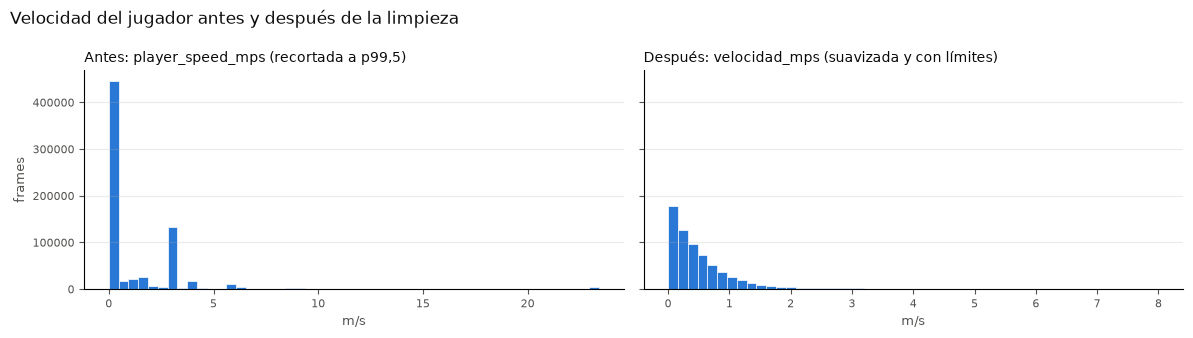

In [18]:
import time

t0 = time.time()
video_bruto = datos.leer_video(vid.COLUMNAS_LIMPIEZA + ['player_speed_mps', 'player_acceleration_mps2'])
conservados = video_bruto.merge(identidades.loc[identidades['conservar'], vid.LLAVE_TRACK], on=vid.LLAVE_TRACK)
video_limpio = vid.limpiar_video(video_bruto, identidades, diagnostico)
print(f'Limpieza: {time.time() - t0:.0f} s')
display(datos.comparar(datos.resumen_tabla(conservados, 'video crudo (tracks conservados)'),
                       datos.resumen_tabla(video_limpio, 'video limpio (frame × jugador)')))

def rango(serie):
    a = serie.astype(float).abs()
    return {'pct_faltante': round(100 * a.isna().mean(), 1), 'p50': round(a.median(), 2), 'p99': round(a.quantile(0.99), 2),
            'max': round(a.max(), 1)}

pares = [('player_position_x', 'x_m'), ('player_position_y', 'y_m'), ('player_speed_mps', 'velocidad_mps'),
         ('player_acceleration_mps2', 'aceleracion_mps2'), ('elbow_angular_velocity', 'vel_ang_codo_dps'),
         ('racket_angular_velocity', 'vel_ang_raqueta_dps')]
filas = [{'antes': a, 'después': d, **{f'antes_{k}': v for k, v in rango(conservados[a]).items()},
          **{f'después_{k}': v for k, v in rango(video_limpio[d]).items()}} for a, d in pares]
filas.append({'antes': 'racket_speed / body_scale', 'después': 'vel_raqueta_norm',
              **{f'antes_{k}': v for k, v in rango(conservados['racket_speed'] / conservados['body_scale']).items()},
              **{f'después_{k}': v for k, v in rango(video_limpio['vel_raqueta_norm']).items()}})
print('Rangos antes y después (valores absolutos):')
display(pd.DataFrame(filas))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
crudo = conservados['player_speed_mps'].dropna()
for eje, serie, titulo in [(ejes[0], crudo.clip(upper=crudo.quantile(0.995)), 'Antes: player_speed_mps (recortada a p99,5)'),
                           (ejes[1], video_limpio['velocidad_mps'].dropna(), 'Después: velocidad_mps (suavizada y con límites)')]:
    eje.hist(serie, bins=50, color=COLOR, edgecolor='white', linewidth=0.5)
    eje.set_title(titulo, fontsize=10, color=TINTA, loc='left')
    eje.set_xlabel('m/s', fontsize=9, color=TINTA_2)
    eje.tick_params(colors=TINTA_2, labelsize=8)
    eje.grid(axis='y', alpha=0.25)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_ylabel('frames', fontsize=9, color=TINTA_2)
fig.suptitle('Velocidad del jugador antes y después de la limpieza', fontsize=12, color=TINTA, x=0.01, ha='left')
fig.tight_layout()
plt.show()
del video_bruto, conservados

**Calidad por jugador × punto.** Se agrega a `participaciones` y se guardan las tablas.

In [19]:
calidad = vid.calidad_limpieza(video_limpio)
print('Calidad de la limpieza por jugador × punto:')
display(calidad.drop(columns=['partido', 'punto']).describe().T.round(1))

con_y = video_limpio['seccion'].notna()
print('Frames por sección de profundidad (con y válida):',
      (100 * video_limpio.loc[con_y, 'seccion'].value_counts(normalize=True)).round(1).to_dict())
print(f"Golpes detectados: {int(video_limpio['golpe'].sum()):,} | juego aéreo en el "
      f"{100 * video_limpio['juego_aereo'].astype('float').mean():.1f} % de los frames con pose")
print('Partido 17 (y inválida): % de frames sin velocidad =',
      round(100 * video_limpio.loc[video_limpio['partido'] == 17, 'velocidad_mps'].isna().mean(), 1))
print('Control con el punto 24-1:')
display(calidad.query('partido == 24 and punto == 1').merge(jugadores[['codigo', 'nombre']], on='codigo'))

participaciones = participaciones.drop(columns=[c for c in calidad.columns if c in participaciones.columns
                                                 and c not in ['partido', 'punto', 'codigo']])
participaciones = participaciones.merge(calidad.drop(columns='frames_video'), on=['partido', 'punto', 'codigo'], how='left')
print('Guardado:', datos.guardar_tabla(video_limpio, 'video_limpio', formato='parquet').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(participaciones, 'participaciones').relative_to(RAIZ))

Calidad de la limpieza por jugador × punto:


,count,mean,std,min,25%,50%,75%,max
frames_video,1029.0,686.0,577.9,1.0,305.0,522.0,821.0,4304.0
pose_coverage,1029.0,84.0,25.8,0.0,82.7,95.3,99.7,100.0
pct_posicion_corregida,1029.0,0.7,2.9,0.0,0.0,0.0,0.0,38.2
pct_cinematica_corregida,1029.0,0.6,2.2,0.0,0.0,0.0,0.0,18.0
pct_y_faltante,1029.0,4.5,19.4,0.0,0.0,0.0,0.0,100.0
golpes,1029.0,11.2,9.1,0.0,6.0,9.0,14.0,85.0


Frames por sección de profundidad (con y válida): {'fondo': 58.4, 'transicion': 39.9, 'red': 1.7}
Golpes detectados: 11,558 | juego aéreo en el 2.0 % de los frames con pose
Partido 17 (y inválida): % de frames sin velocidad = 100.0
Control con el punto 24-1:


,partido,punto,codigo,frames_video,pose_coverage,pct_posicion_corregida,pct_cinematica_corregida,pct_y_faltante,golpes,nombre
0,24,1,199884,1022,84.1,0.0,0.0,0.0,22,Juliana Gómez
1,24,1,283321,1022,95.4,0.0,0.0,0.0,14,Santiago Pujol Zabala
2,24,1,324764,1022,85.9,0.0,0.0,0.0,19,Laura Sofía Rodríguez González
3,24,1,352369,1002,26.6,0.0,0.0,0.0,3,Andrés Felipe Santafé Buitrago


Guardado: data\interim\video_limpio.parquet
Guardado: data\interim\participaciones.csv


**Resultado**
- **Tabla limpia:** 705.888 filas frame × jugador de los 1.029 tracks conservados, con 42 columnas. Se guardó en `data/interim/video_limpio.parquet`.
- **Velocidad:** tras la limpieza su mediana es 0,37 m/s y su máximo 8 m/s (antes, 1.156 m/s). La aceleración queda entre −10 y 10 m/s².
- **Corrección de atípicos:** en promedio se corrigió el 0,7 % de las posiciones y el 0,6 % de la cinemática por jugador × punto.
- **Pose:** la cobertura mediana es del 95 %. Control: Andrés Santafé tiene 26,6 % en el punto 24-1, como se había visto antes.
- **Golpes:** se detectaron 11.558, con una mediana de 9 por jugador y punto.
- **Profundidad:** los jugadores pasan el 58 % del tiempo en el fondo, el 40 % en transición y solo el 1,7 % en la red (distancia mediana a la red: 7,2 m). Por eso el estilo (D21) se define con la línea de saque: con una zona de red de 3 m casi ningún jugador saldría atacante.
- **Partido 17:** sin velocidad ni profundidad (regla general de `y` inválida); conserva `x`, lado y golpes.

## 1.9 Variables jugador × punto

**Objetivo:** describir el estilo de juego de cada jugador en cada punto a partir de `video_limpio`. Las variables se agregan a `participaciones` (jugador × punto) y el estilo fijo de cada jugador, a `jugadores`.

**Decisiones**
- **D21 (estilo):** la zona atacante es todo lo que está delante de la línea de saque (a menos de 6,95 m de la red). Un jugador es atacante (1) en un punto si pasa allí al menos tanto tiempo como detrás. El estilo del jugador es atacante si lo fue en al menos el 50 % de sus puntos.
- **D22 (ritmo de juego):** golpes por segundo de cada jugador y duración del punto (esta última entra como contexto en la 1.10).
- **D31 (definiciones):**
  - **Quieto:** velocidad por debajo de la mediana global. **Ráfaga:** tramo continuo de al menos 0,5 s por encima del percentil 90 global. Los umbrales son los mismos para todos los jugadores.
  - **Área cubierta:** cuadros de 0,5 × 0,5 m que el jugador pisó al menos una vez, en m².
  - **Variabilidad de ángulos:** desviación estándar (circular para la orientación de la raqueta).
  - **Dirección de la raqueta:** tres grupos (% arriba, % abajo y % lateral).
  - **Mínimos:** si el track dura menos de 2 s, todas sus variables quedan NaN; las variables de pose solo se calculan con una cobertura de pose de al menos el 50 %.

| Grupo | Variables |
|---|---|
| Estilo y profundidad | `pct_zona_atacante`, `atacante`, `pct_red`, `pct_transicion`, `pct_fondo`, `prof_media_m`, `prof_sd_m`, `pct_en_su_lado` |
| Movimiento | `area_m2`, `distancia_m`, `pct_quieto`, `rafagas_por_min`, `vel_p90` |
| Raqueta y pose | `pct_juego_aereo`, `pct_raqueta_arriba/abajo/lateral`, `sd_angulo_codo`, `sd_angulo_hombro`, `sd_orientacion_raqueta` |
| Golpes y ritmo | `indice_golpe_p90`, `indice_golpe_p95`, `golpes_por_s` |

Umbrales globales de movimiento (m/s): {'quieto_mps': 0.369, 'rafaga_mps': 1.28}


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,participaciones (antes),1132,20,721,3.18
1,participaciones (con variables 1.9),1132,44,4957,9.95


Variables jugador × punto (1.029 tracks con video):


,count,mean,std,min,25%,50%,75%,max
duracion_track_s,1029.0,13.82,9.33,0.02,7.62,11.12,16.70,71.81
pct_zona_atacante,979.0,41.28,39.24,0.00,0.00,28.85,82.99,100.00
atacante,979.0,0.40,0.49,0.00,0.00,0.00,1.00,1.00
pct_red,979.0,1.75,9.03,0.00,0.00,0.00,0.00,100.00
pct_transicion,979.0,39.53,38.34,0.00,0.00,26.63,79.36,100.00
pct_fondo,979.0,58.72,39.24,0.00,17.01,71.15,100.00,100.00
prof_media_m,979.0,7.07,1.16,0.23,6.36,7.17,7.74,9.95
prof_sd_m,979.0,0.59,0.49,0.00,0.24,0.45,0.79,3.15
pct_en_su_lado,1015.0,97.49,9.86,0.00,100.00,100.00,100.00,100.00
area_m2,979.0,3.21,2.50,0.25,1.50,2.50,4.25,17.00


Jugador × punto atacantes: 40.0 % | jugadores atacantes: 11 de 30


,nombre,puntos_con_estilo,pct_puntos_atacante,estilo_atacante
21,Jeronimo Coy,7,85.7,1
12,Nikol Sofía Avendaño Suárez,21,81.0,1
0,Jorge García,23,78.3,1
11,Antonio Benitez Rueda,35,65.7,1
26,Gabriel López Acosta,32,65.6,1
22,Andrés Felipe Santafé Buitrago,57,63.2,1
17,Luis Felipe Cuellar Santamaria,42,61.9,1
1,Jose Fabian Garcia Camargo,33,57.6,1
8,Laura Sofía Rodríguez González,23,56.5,1
3,Juan Andrés Ordóñez Vanegas,38,52.6,1


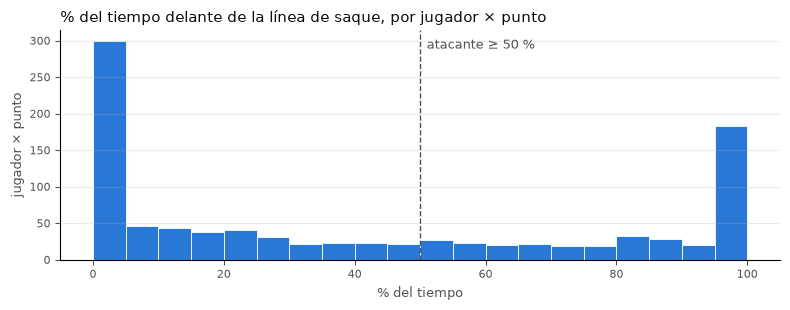

Guardado: data\interim\participaciones.csv
Guardado: data\interim\jugadores.csv


In [20]:
from src import variables as var

umbrales = var.umbrales_movimiento(video_limpio)
print('Umbrales globales de movimiento (m/s):', umbrales)
var_jugador = var.variables_jugador(video_limpio, umbrales)
estilo = var.estilo_jugador(var_jugador)

antes = datos.resumen_tabla(participaciones, 'participaciones (antes)')
participaciones = participaciones.merge(var_jugador.drop(columns='pose_coverage'), on=['partido', 'punto', 'codigo'], how='left')
jugadores = jugadores.drop(columns=[c for c in estilo.columns if c != 'codigo' and c in jugadores]).merge(estilo, on='codigo', how='left')
display(datos.comparar(antes, datos.resumen_tabla(participaciones, 'participaciones (con variables 1.9)')))
print('Variables jugador × punto (1.029 tracks con video):')
display(var_jugador.drop(columns=['partido', 'punto', 'codigo']).describe().T.round(2))
print(f"Jugador × punto atacantes: {100 * var_jugador['atacante'].mean():.1f} % | "
      f"jugadores atacantes: {int(estilo['estilo_atacante'].sum())} de {len(estilo)}")
display(estilo.merge(jugadores[['codigo', 'nombre']], on='codigo').sort_values('pct_puntos_atacante', ascending=False)
        [['nombre', 'puntos_con_estilo', 'pct_puntos_atacante', 'estilo_atacante']])

fig, eje = plt.subplots(figsize=(8, 3.2))
eje.hist(var_jugador['pct_zona_atacante'].dropna(), bins=20, color=COLOR, edgecolor='white', linewidth=0.6)
eje.axvline(50, color=TINTA_2, linewidth=1, linestyle='--')
eje.text(51, eje.get_ylim()[1] * 0.92, 'atacante ≥ 50 %', fontsize=9, color=TINTA_2)
eje.set_title('% del tiempo delante de la línea de saque, por jugador × punto', fontsize=11, color=TINTA, loc='left')
eje.set_xlabel('% del tiempo', fontsize=9, color=TINTA_2)
eje.set_ylabel('jugador × punto', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=8)
eje.grid(axis='y', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

print('Guardado:', datos.guardar_tabla(participaciones, 'participaciones').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(jugadores, 'jugadores').relative_to(RAIZ))

**Resultado**
- **Umbrales:** quieto por debajo de 0,37 m/s; ráfaga por encima de 1,28 m/s.
- **Cobertura:** 1.029 jugador × punto con video. Tienen variables de profundidad 979 (faltan los tracks de menos de 2 s y los del partido 17, sin `y`) y variables de pose 914 (cobertura de al menos el 50 %).
- **Estilo:** el 40 % de los jugador × punto es atacante, y 11 de los 30 jugadores lo son en al menos la mitad de sus puntos. El histograma muestra dos grupos: quienes casi siempre juegan detrás de la línea de saque y quienes casi siempre juegan delante.
- **Valores típicos (medianas):** área cubierta de 2,5 m², 48 % del tiempo quieto, 0,9 golpes por segundo y 100 % del tiempo en su propio lado.
- Salidas: `participaciones.csv` (con las variables 1.9) y `jugadores.csv` (con el estilo del jugador).

## 1.10 Variables pareja × punto y filtros

**Objetivo:** una fila por punto con las variables de cada pareja y su diferencia con el rival. Se aplican filtros que no miran el resultado y se entrega la tabla para el modelo.

**Decisiones**
- **D20:** solo los 244 puntos con los 4 jugadores identificados.
- **D32 (construcción):**
  - **Del jugador a la pareja:** para cada variable, la suma de los dos compañeros (capacidad) y su diferencia absoluta (complementariedad). Para velocidad p90, golpes por segundo y área se agrega además la razón mínimo/máximo (balance).
  - **Estilo de la pareja:** la suma de `atacante` es el número de atacantes (0, 1 o 2).
  - **Cohesión:** media y desviación de la distancia entre compañeros.
  - **Sincronía:** correlación, frame a frame, de la velocidad y de la profundidad de los dos compañeros.
  - **Variables fijas** (de `jugadores`): estatura, IMC, edad, género, mano, nivel, tiempo jugando, experiencia, otra raqueta, estado físico, frecuencia de deporte y lesiones. Además, `en_lado_mano`: diestro que juega a la derecha o zurdo que juega a la izquierda.
  - **Orientación:** una fila por punto, con las variables de la pareja 1 (`e1_`), de la pareja 2 (`e2_`) y su diferencia equipo 1 − equipo 2 (`dif_`). La duración del punto entra como contexto. El lado no se incluye porque es constante: el equipo 1 siempre está en BOTTOM.
- **D33 (faltantes y filtros):**
  - **Faltantes:** quedan NaN en esta tabla; se imputan en la fase 2 solo con datos de entrenamiento.
  - **Filtros, en orden y sin usar el resultado:**
    1. faltantes en más del 20 % de los puntos;
    2. varianza baja: un mismo valor en al menos el 95 % de los puntos;
    3. correlación de Pearson |r| ≥ 0,85.
  - **Qué se entrega:** todas las variables que pasan los filtros. La selección final de 10 a 15 se hace en la fase 2 con Lasso y Ridge dentro de la validación (D27).

**¿Qué es la correlación de Pearson?** Mide de −1 a 1 qué tan bien dos variables siguen una línea recta. Si |r| ≥ 0,85, dos variables cuentan casi lo mismo y basta con una. Se conserva la de menos faltantes; si empatan, la relativa al rival (`dif_`).

In [21]:
parejas = var.tabla_parejas(participaciones, var_jugador, jugadores, puntos, video_limpio)
conservadas, filtros = var.filtrar_variables(parejas)
tabla_modelo = parejas[['partido', 'punto', 'punto_equipo_1', *conservadas]]

display(datos.comparar(datos.resumen_tabla(parejas, 'parejas_punto (todas las variables)'),
                       datos.resumen_tabla(tabla_modelo, 'tabla_modelo (tras los filtros)')))
candidatas = parejas.shape[1] - 3
print(f'Variables candidatas: {candidatas} | descartadas: {len(filtros)} | conservadas: {len(conservadas)}')
display(filtros['filtro'].value_counts().rename('variables descartadas').to_frame())
prefijo = lambda c: c.split('_')[0] if c.split('_')[0] in {'e1', 'e2', 'dif'} else 'contexto'
print('Descartadas por faltantes, según pareja:', filtros.loc[filtros['filtro'] == 'faltantes', 'variable'].map(prefijo).value_counts().to_dict())
print('Conservadas por tipo:', pd.Series(conservadas).map(prefijo).value_counts().to_dict())
print(f"Balance del objetivo en los 244 puntos: el equipo 1 gana el {100 * tabla_modelo['punto_equipo_1'].mean():.1f} %")
display(filtros.head(15))

print('Guardado:', datos.guardar_tabla(parejas, 'parejas_punto').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(filtros, 'filtros_variables').relative_to(RAIZ))
print('Guardado:', datos.guardar_tabla(tabla_modelo, 'tabla_modelo', carpeta=datos.DATA_PROCESSED).relative_to(RAIZ))

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,parejas_punto (todas las variables),244,247,4618,7.66
1,tabla_modelo (tras los filtros),244,164,1394,3.48


Variables candidatas: 244 | descartadas: 83 | conservadas: 161


,variables descartadas
filtro,
faltantes,42
correlación,41


Descartadas por faltantes, según pareja: {'e2': 21, 'dif': 21}
Conservadas por tipo: {'e1': 67, 'dif': 50, 'e2': 43, 'contexto': 1}
Balance del objetivo en los 244 puntos: el equipo 1 gana el 43.4 %


,variable,filtro,detalle
0,e2_suma_pct_juego_aereo,faltantes,27 % NaN
1,e2_suma_pct_raqueta_arriba,faltantes,27 % NaN
2,e2_suma_pct_raqueta_abajo,faltantes,27 % NaN
3,e2_suma_pct_raqueta_lateral,faltantes,27 % NaN
4,e2_suma_sd_angulo_codo,faltantes,27 % NaN
5,e2_suma_sd_angulo_hombro,faltantes,27 % NaN
6,e2_suma_sd_orientacion_raqueta,faltantes,27 % NaN
7,e2_suma_indice_golpe_p90,faltantes,27 % NaN
8,e2_suma_indice_golpe_p95,faltantes,27 % NaN
9,e2_suma_golpes_por_s,faltantes,27 % NaN


Guardado: data\interim\parejas_punto.csv
Guardado: data\interim\filtros_variables.csv
Guardado: data\processed\tabla_modelo.csv


**Resultado**
- **Tabla de parejas:** 244 puntos y 244 variables candidatas (más la llave y el objetivo).
- **Filtros:** salen 42 variables por faltantes y 41 por correlación; ninguna por varianza baja. Las 42 de faltantes son todas de pose: 21 de la pareja 2 y sus 21 diferencias con el rival, cada una con 27 % de NaN. Ese es el porcentaje de puntos en que algún jugador de la pareja 2 tiene menos del 50 % de cobertura de pose (D31).
- **Objetivo:** en estos 244 puntos, el equipo 1 gana el 43,4 %.
- **Tabla para el modelo:** quedan 161 variables en `data/processed/tabla_modelo.csv`. Es más que la meta de 10 a 15; la reducción final la hacen Lasso y Ridge en la fase 2, dentro de la validación, para no inflar las métricas.
- **Otras salidas:** `parejas_punto.csv` (todas las variables) y `filtros_variables.csv` (qué variable salió y por qué), ambas en `data/interim/`.

## 1.11 Variables para las fases 2 a 4

**Objetivo:** fijar la lista de variables que usan el modelo (fase 2), las distribuciones (fase 3) y la simulación (fase 4), y comprobar que cada una se puede armar desde los jugadores por separado.

**¿Por qué hace falta?** La fase 4 inventa partidos entre parejas que nunca jugaron juntas. Para eso, cada variable de pareja tiene que salir de los valores de sus dos jugadores, y no de algo que solo se mide cuando juegan juntos. Si el modelo usara una variable que no se puede armar así, la simulación no podría usarlo.

**Decisiones (D34)**
- **Criterios:**
  1. **Se reconstruye desde cada jugador:** la variable de pareja es la suma, la diferencia absoluta o la razón mín/máx de los dos compañeros (D32). Con los dos jugadores de cada lado se arma la pareja, y la `dif_` es pareja 1 − pareja 2.
  2. **Existe para las dos parejas:** cualquier pareja puede quedar como equipo 1 o como equipo 2 en la simulación.
  3. **Solo `dif_`:** las versiones `e1_` y `e2_` repiten la información, y como el equipo 1 siempre está en BOTTOM, las `e1_` mezclan el estilo con el lado de la cámara.
  4. **Estilo o control de nivel:** el nivel entra como control, para que el efecto del estilo no sea en realidad «ganan los que juegan mejor».
- **Las 19 variables** (`var.VARIABLES_MODELO`):

| Grupo | Variables | Qué mide |
|---|---|---|
| Estilo y posición (5) | `suma_atacante`, `absdif_atacante`, `absdif_prof_media_m`, `suma_prof_sd_m`, `suma_pct_en_su_lado` | Número de atacantes, si mezclan un atacante con un defensor, si juegan escalonados o en paralelo, cuánto suben y bajan, y cuánto respeta cada uno su lado |
| Movimiento (6) | `suma_vel_p90`, `razon_vel_p90`, `suma_area_m2`, `razon_area_m2`, `suma_pct_quieto`, `suma_rafagas_por_min` | Velocidad, balance de velocidad entre los dos, cancha cubierta, reparto de esa cobertura, tiempo quietos y explosividad |
| Nivel y atributos fijos (8) | `suma_nivel_padel`, `absdif_nivel_padel`, `suma_tiempo_jugando_padel`, `suma_practica_otra_raqueta`, `suma_frecuencia_deporte`, `suma_estatura_cm`, `suma_imc`, `absdif_mujer` | Nivel, desbalance de nivel, experiencia, otros deportes de raqueta, condición física, alcance, complexión y si la pareja es mixta |

- **Se quita `dif_suma_mujer`** (aprobado por el equipo). Su correlación con `dif_suma_estatura_cm` es r = −0,85 (|r| en el umbral de D33): la pareja con más mujeres es la de menor estatura sumada, así que las dos dicen casi lo mismo. Por eso el filtro de la 1.10 ya la había sacado. Con ella, el VIF de la estatura es 12,8 y el suyo 10,3; por encima de 10 se considera que una variable se repite con las demás. Sin ella, el VIF de la estatura baja a 2,7. Se conserva la estatura porque además mide alcance. `dif_absdif_mujer` sí queda: distingue las parejas mixtas y no repite la estatura.
- **Lo que queda fuera y por qué:**
  - **Pose, raqueta y golpes:** no tienen versión `dif_` (la pareja 2 tiene el 27 % de faltantes y salieron en la 1.10) y en BOTTOM dependen de la distancia a la cámara.
  - **Cohesión y sincronía:** solo existen cuando los dos juegan juntos; no se pueden armar desde cada jugador.
  - **`duracion_punto_s`:** solo se conoce al terminar el punto y no la controla la pareja. **`pose_coverage`:** mide la calidad del video, no el juego.
  - **Poca variación:** `en_lado_mano` (2 zurdos), `edad`, `pct_red` (1,7 % del tiempo cerca de la red).
  - **Repetidas con otra de la lista:** `distancia_m` (con el área), `suma_prof_media_m` (con atacante), `experiencia_padel` (con nivel y tiempo jugando), `pct_fondo` y `estado_fisico`.

**Para las fases siguientes:** la fase 2 parte de estas 19 variables y usa directamente `tabla_modelo`, que ya está en memoria (no se vuelve a leer del disco). Lo que deben tener en cuenta las fases 3 y 4 quedó como nota al inicio de cada una.

In [22]:
# 1) Cada dif_ se vuelve a armar desde los jugadores sueltos y se compara con la tabla de la 1.10
fijas = [c for c in var.VARIABLES_FIJAS if c in jugadores]
jp = (participaciones.drop(columns=fijas, errors='ignore').merge(jugadores[['codigo', *fijas]], on='codigo')
      .merge(tabla_modelo[['partido', 'punto']], on=['partido', 'punto']))
filas = []
for (p, q), g in jp.groupby(['partido', 'punto']):
    e1, e2 = g[g['equipo'] == 1], g[g['equipo'] == 2]
    pareja1 = var.combinar_pareja(e1.iloc[0], e1.iloc[1])
    pareja2 = var.combinar_pareja(e2.iloc[0], e2.iloc[1])
    filas.append({'partido': p, 'punto': q, **{v: pareja1[v] - pareja2[v] for v in var.VARIABLES_MODELO}})
reconstruida = pd.DataFrame(filas).set_index(['partido', 'punto'])
original = tabla_modelo.set_index(['partido', 'punto'])[var.VARIABLES_MODELO]
error = (reconstruida - original).abs().max()
mismos_nan = (reconstruida.isna() == original.isna()).all().all()
print(f'Puntos reconstruidos: {len(reconstruida)} | error máximo: {error.max():.1e} | mismos faltantes: {mismos_nan}')

# 2) Por qué sale dif_suma_mujer: correlación con la estatura y VIF con y sin ella
r = parejas['dif_suma_mujer'].corr(parejas['dif_suma_estatura_cm'])
print(f'Correlación dif_suma_mujer con dif_suma_estatura_cm: r = {r:.2f}')
con_mujer = var.vif(parejas, [*var.VARIABLES_MODELO, 'dif_suma_mujer'])
sin_mujer = var.vif(tabla_modelo, var.VARIABLES_MODELO)
display(pd.concat({'VIF con dif_suma_mujer': con_mujer, 'VIF sin ella (las 19)': sin_mujer}, axis=1).round(1).head(8))
display(datos.resumen_tabla(tabla_modelo[var.VARIABLES_MODELO], 'las 19 variables del modelo'))

Puntos reconstruidos: 244 | error máximo: 0.0e+00 | mismos faltantes: True
Correlación dif_suma_mujer con dif_suma_estatura_cm: r = -0.85


,VIF con dif_suma_mujer,VIF sin ella (las 19)
dif_suma_estatura_cm,12.8,2.7
dif_suma_mujer,10.3,NaN
dif_suma_area_m2,4.2,4.1
dif_suma_nivel_padel,3.7,3.0
dif_suma_vel_p90,3.4,3.3
dif_suma_prof_sd_m,2.8,2.8
dif_suma_rafagas_por_min,2.6,2.5
dif_suma_imc,2.4,2.3


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,las 19 variables del modelo,244,19,211,4.55


**Resultado**
- **Se reconstruyen desde cada jugador:** al volver a armar las 19 variables desde los jugadores sueltos (`var.combinar_pareja`) en los 244 puntos, el error máximo frente a `tabla_modelo` es 0 y los faltantes coinciden. Cada `dif_` es una cuenta exacta sobre los cuatro jugadores, así que la fase 4 puede armar cualquier pareja.
- **`dif_suma_mujer`:** r = −0,85 con la estatura sumada; con ella en la lista hay dos VIF por encima de 10 (12,8 y 10,3). Sin ella, el VIF más alto de las 19 es 4,1 (`dif_suma_area_m2`).
- **Faltantes:** 4,6 % de las celdas de las 19 variables; se imputan en la fase 2 con la mediana de entrenamiento (D33).
- **Para la fase 2:** la matriz de entrada es `tabla_modelo[var.VARIABLES_MODELO]` y el objetivo `tabla_modelo['punto_equipo_1']`.

---
# Fase 2 — Modelo predictivo

**Objetivo:** aprender a predecir quién gana cada punto (`punto_equipo_1`, D3) a partir de las 19 variables de estilo y nivel (D34). Ese modelo es el que la fase 4 usa para enfrentar parejas que nunca jugaron juntas.

**Dónde estamos en CRISP-DM**

| Etapa de CRISP-DM | Dónde está en el proyecto |
|---|---|
| Entendimiento del negocio | Objetivo del notebook: las parejas con más probabilidad de ganar |
| Entendimiento de los datos | 1.2 |
| Preparación de los datos | 1.3 a 1.11 y 2.1 |
| **Modelado** | **2.2 a 2.7** |
| **Evaluación** | **2.8** |
| Despliegue | Fases 3 y 4: el modelo elegido se usa para simular el torneo |

**Plan de la fase 2**

| Sección | Tema del curso | Qué se hace | Responsable |
|---|---|---|---|
| 2.1 | Pre-procesamiento y validación cruzada | `X`, `y`, partición train/test por partido y pliegues de validación | Miguel |
| 2.2 | Métricas de evaluación | Una evaluación común para todos los modelos | Miguel |
| 2.3 | Modelo naive y regresión logística | La referencia mínima y el modelo base (`statsmodels` y `scikit-learn`) | Miguel |
| 2.4 | LASSO, Ridge y árboles | Selección de 10 a 15 variables y un árbol de decisión | Miguel |
| 2.5 | Random Forest, SVM y hyperparameter tuning | Modelos avanzados con búsqueda de hiperparámetros | Compañero |
| 2.6 | Bagging y boosting | Árboles en bagging, AdaBoost y Gradient Boosting (red neuronal opcional) | Compañero |
| 2.7 | Ensamblaje de modelos | Voto de los mejores modelos | Compañero |
| 2.8 | Comparación final y bootstrap | Tabla de métricas en test, intervalos por bootstrap y modelo para la fase 4 | Compañero |

**Reglas que valen para toda la fase**
- **Nunca se mezclan puntos de un mismo partido** entre entrenamiento y prueba (D35).
- **Faltantes (D33):** se imputan con la mediana calculada solo con los datos de entrenamiento.
- **Métricas:** AUC, log-loss, Brier y calibración. La fase 4 necesita probabilidades bien calibradas, no solo acertar el ganador.
- **Formato:** cada sección sigue el estilo de los notebooks del profesor (`notebooks/referencias/`, prioridad a los numerados 01–07): primero la idea del método, luego el código y al final la lectura del resultado.

## 2.1 Pre-procesamiento y validación cruzada

**Objetivo:** dejar listos `X`, `y` y la forma de partir los datos, para que todos los modelos de la fase 2 se entrenen y se prueben con los mismos puntos.

**Decisiones**
- **D34:** `X` son las 19 variables de `var.VARIABLES_MODELO`; `y` es `punto_equipo_1`. Se toman de `tabla_modelo`, que ya está en memoria desde la 1.10.
- **D35 (partición, como en el profesor pero por partido):**
  - **Train y test:** el profesor separa el 20 % para test con `train_test_split(test_size=0.2, random_state=0)`. Aquí se hace lo mismo, pero el 20 % son **partidos completos**: 5 de los 25, con `GroupShuffleSplit` y la misma semilla. El test no se toca hasta la 2.8.
  - **Validación cruzada dentro del train:** el profesor usa k-fold. Aquí cada pliegue es un partido (`LeaveOneGroupOut`): se entrena con 19 partidos y se valida con el que quedó fuera, 20 veces.
  - **Por qué por partido:** los puntos de un mismo partido los juegan las mismas cuatro personas. Si un partido queda repartido entre train y test, el modelo reconoce a esas parejas y las métricas salen infladas.
- **D33:** los faltantes no se imputan aquí, sino dentro de cada pliegue con la mediana de entrenamiento (2.2).

### ¿Qué es la validación cruzada?
Es una forma de estimar qué tan bien le irá al modelo con datos nuevos usando todos los datos de entrenamiento, y no una sola partición que pudo salir con suerte. Los datos se dividen en partes (*folds*); en cada vuelta se entrena con todas menos una y se mide con la que quedó fuera, y al final se promedian las métricas. Aquí cada parte es un partido.

In [23]:
# Librerías de la fase 2 (se irán sumando en cada sección)
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut

In [24]:
# Variable objetivo: ¿cuántos puntos gana cada equipo? (1 = gana el equipo 1)
tabla_modelo['punto_equipo_1'].value_counts(), tabla_modelo['punto_equipo_1'].value_counts(normalize=True)

(punto_equipo_1
 0.0    138
 1.0    106
 Name: count, dtype: int64,
 punto_equipo_1
 0.0    0.565574
 1.0    0.434426
 Name: proportion, dtype: float64)

In [25]:
# X: las 19 variables de estilo y nivel (D34) | y: quién ganó el punto | grupos: el partido de cada punto
X = tabla_modelo[var.VARIABLES_MODELO]
y = tabla_modelo['punto_equipo_1'].astype(int)
grupos = tabla_modelo['partido']
print(f'X: {X.shape[0]} puntos x {X.shape[1]} variables | partidos: {grupos.nunique()}')

X: 244 puntos x 19 variables | partidos: 25


In [26]:
# Train y test como en el profesor (20 %, random_state=0), pero con partidos completos (D35)
particion = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
idx_train, idx_test = next(particion.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

print('Observaciones en entrenamiento: {} ({} partidos)'.format(len(X_train), grupos_train.nunique()))
print('Observaciones en Test: {} ({} partidos: {})'.format(len(X_test), grupos.iloc[idx_test].nunique(), sorted(grupos.iloc[idx_test].unique())))
print('¿Algún partido en los dos lados?:', bool(set(grupos_train) & set(grupos.iloc[idx_test])))

Observaciones en entrenamiento: 192 (20 partidos)
Observaciones en Test: 52 (5 partidos: [np.int64(5), np.int64(10), np.int64(18), np.int64(26), np.int64(29)])
¿Algún partido en los dos lados?: False


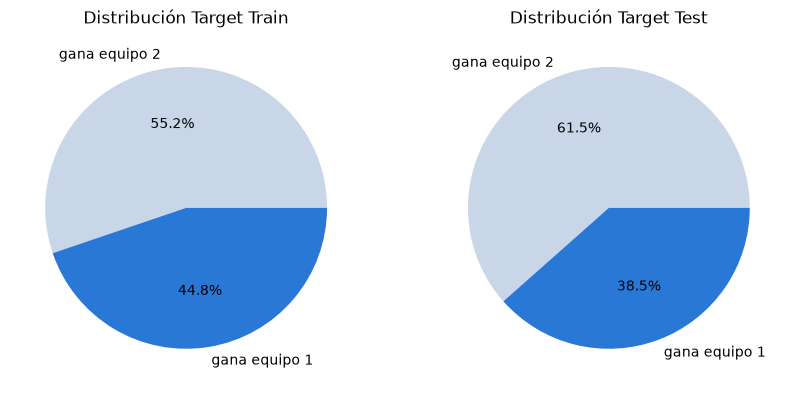

In [27]:
# Distribución del objetivo en train y en test (como en el profesor)
keys_train, counts_train = np.unique(y_train, return_counts=True)
keys_test, counts_test = np.unique(y_test, return_counts=True)
etiquetas = {0: 'gana equipo 2', 1: 'gana equipo 1'}

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.pie(counts_train / counts_train.sum(), labels=[etiquetas[k] for k in keys_train], autopct='%1.1f%%', colors=['#c9d6e8', '#2a78d6'])
plt.title('Distribución Target Train')
plt.subplot(1, 2, 2)
plt.pie(counts_test / counts_test.sum(), labels=[etiquetas[k] for k in keys_test], autopct='%1.1f%%', colors=['#c9d6e8', '#2a78d6'])
plt.title('Distribución Target Test')
plt.show()

In [28]:
# Validación cruzada dentro del train: un pliegue por partido (D35)
validacion = LeaveOneGroupOut()
pliegues = list(validacion.split(X_train, y_train, groups=grupos_train))

tamanos = pd.Series([len(val) for _, val in pliegues])
print(f'Pliegues: {len(pliegues)} | puntos de validación por pliegue: mín {tamanos.min()}, mediana {tamanos.median():.0f}, máx {tamanos.max()}')
print(f'Proporción de puntos que gana el equipo 1 por pliegue: entre {min(y_train.iloc[v].mean() for _, v in pliegues):.0%} y {max(y_train.iloc[v].mean() for _, v in pliegues):.0%}')

Pliegues: 20 | puntos de validación por pliegue: mín 6, mediana 10, máx 13
Proporción de puntos que gana el equipo 1 por pliegue: entre 0% y 78%


In [29]:
# Faltantes en train y test (se imputan dentro de cada pliegue en la 2.2, D33)
faltantes = pd.DataFrame({'% NaN train': X_train.isna().mean() * 100, '% NaN test': X_test.isna().mean() * 100}).round(1)
faltantes[faltantes.sum(axis=1) > 0].sort_values('% NaN train', ascending=False)

,% NaN train,% NaN test
dif_suma_atacante,8.3,7.7
dif_absdif_atacante,8.3,7.7
dif_absdif_prof_media_m,8.3,7.7
dif_suma_prof_sd_m,8.3,7.7
dif_suma_vel_p90,8.3,7.7
dif_razon_vel_p90,8.3,7.7
dif_suma_area_m2,8.3,7.7
dif_suma_pct_quieto,8.3,7.7
dif_razon_area_m2,8.3,7.7
dif_suma_rafagas_por_min,8.3,7.7


**Resultado**

Quedaron 192 puntos de 20 partidos para entrenar y 52 puntos de 5 partidos para el test, los partidos 5, 10, 18, 26 y 29, y ningun partido quedo repartido entre los dos lados que era lo que mas me importaba de toda esta parte. En train el equipo 1 gana el 44,8 % de los puntos y en test el 38,5 %, o sea el test salio un poco mas cargado hacia el equipo 2, no es grave pero toca tenrelo en cuenta en la 2.8 porque un modelo que diga siempre equipo 2 se va a ver mejor de lo que es en ese test.

La validacion cruzada quedo con 20 pliegues, uno por partdio, de entre 6 y 13 puntos cada uno. Muy pocos puntos. Eso hace que la metrica de cada pliegue salte muchismo, hay partidos como el 28 y el 35 donde el equipo 1 no gano ni un solo punto y en esos el auc ni siquiera se puede calcular porque solo hay una clase, entonces lo que toca es juntar las predicciones de todos los pliegues y medir al final con todo junto, eso lo resuelvo en la 2.2 cuando arme la evalaucion comun.

Los faltantes rondan el 8 % en las variables de movimiento, parecido en train y en test, y se imputan adentro de cada pliegue con la mediana de entrenamiento, nunca antes, porque si no el test ya estaria metido en la mediana. Seran suficientes 192 puntos para 19 variables ? por eso mismo esta lo de lasso en la 2.4, para quitarle variables al modelo antes de que se aprenda los partidos de memoria_

## 2.2 Métricas y evaluación común

**Objetivo:** definir una sola forma de entrenar y medir, para que todos los modelos de la 2.3 a la 2.7 se comparen en igualdad de condiciones.

**Decisiones**
- **D33:** cada modelo se envuelve con un imputador por mediana (`mod.con_imputacion`). Así la mediana se calcula solo con el train de cada pliegue y nunca con el partido que se valida.
- **D36 (AUC por pliegue):** el AUC se calcula dentro de cada partido validado y se promedia, como hace `cross_val_score(scoring='roc_auc')` en el notebook 05. Los partidos con una sola clase (el 28 y el 35, donde el equipo 1 no ganó ningún punto) no tienen AUC y se saltan. Log-loss, Brier, accuracy y F1 se calculan con todas las predicciones juntas. Abajo está la evidencia de por qué.

**Las funciones (`src/modelo.py`)**

| Función | Qué hace |
|---|---|
| `predecir_cv(modelo, X, y, pliegues)` | Entrena el modelo en cada pliegue y predice el partido que quedó fuera. Devuelve una probabilidad por punto, predicha por un modelo que no vio ese partido. |
| `metricas(y, p, pliegues)` | AUC por pliegue (media, desviación y cuántos pliegues), log-loss, Brier, accuracy y F1 con umbral 0,5. |
| `graficar_evaluacion(y, p, nombre, pliegues)` | AUC por partido (o curva ROC si es el test), curva de calibración y matriz de confusión. |

### Las métricas (como en el notebook 03)

**Matriz de confusión.** Cruza lo real con lo predicho. Aquí la clase positiva es *gana el equipo 1*:
- **TP:** puntos que ganó el equipo 1 y el modelo lo predijo.
- **TN:** puntos que ganó el equipo 2 y el modelo lo predijo.
- **FP:** el modelo dijo equipo 1 y ganó el equipo 2.
- **FN:** el modelo dijo equipo 2 y ganó el equipo 1.

| Métrica | Fórmula | Qué responde |
|---|---|---|
| Accuracy | $\dfrac{TP + TN}{TP + FP + FN + TN}$ | ¿Qué porcentaje de puntos acertó? |
| Precision | $\dfrac{TP}{TP + FP}$ | De los puntos que dijo que ganaba el equipo 1, ¿cuántos ganó? |
| Recall | $\dfrac{TP}{TP + FN}$ | De los puntos que ganó el equipo 1, ¿cuántos detectó? |
| F1 | $2 \times \dfrac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ | Equilibrio entre precision y recall |
| AUC-ROC | Área bajo la curva TPR vs FPR | ¿Le da más probabilidad a los puntos que gana el equipo 1 que a los que pierde? 0,5 es azar y 1 es perfecto |

### Dos métricas más: calidad de la probabilidad
El notebook 03 evalúa sobre todo si el modelo acierta la clase. Aquí además importa **qué tan buena es la probabilidad**, porque la fase 4 no usa la clase sino p(gana el punto) para simular partidos a 7 puntos. Un modelo que dice 0,9 cuando la realidad es 0,6 inventa parejas imbatibles.

| Métrica | Fórmula | Cómo se lee |
|---|---|---|
| Log-loss | $-\dfrac{1}{n}\sum \big[y_i \ln p_i + (1-y_i)\ln(1-p_i)\big]$ | Castiga mucho equivocarse con seguridad. Menor es mejor. |
| Brier | $\dfrac{1}{n}\sum (p_i - y_i)^2$ | Error cuadrático de la probabilidad. Menor es mejor; decir siempre 0,5 da 0,25. |
| Calibración | Gráfico: probabilidad predicha vs proporción real | Si el modelo dice 0,6, el equipo 1 debería ganar cerca del 60 % de esos puntos. Lo ideal es la diagonal. |

### Prueba de la evaluación con el modelo más simple
Para comprobar que las funciones miden bien, se prueban con `DummyClassifier(strategy='prior')`: un modelo que ignora las variables y siempre predice la proporción de puntos que ganó el equipo 1 en su train. Ese modelo no sabe nada, así que su AUC tiene que dar 0,5. En la 2.3 se usa como la referencia mínima que todo modelo debe superar.

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score
from src import modelo as mod

# Modelo que no sabe nada: siempre predice la proporción de puntos que ganó el equipo 1 en su train
naive = DummyClassifier(strategy='prior')
p_naive = mod.predecir_cv(naive, X_train, y_train, pliegues)
pd.Series(mod.metricas(y_train, p_naive, pliegues)).round(3)

AUC                  0.500
AUC_sd               0.000
pliegues_con_AUC    18.000
log_loss             0.696
Brier                0.251
accuracy             0.552
F1                   0.000
dtype: float64

In [31]:
# ¿Por qué el AUC por pliegue (D36)? Al juntar las predicciones de todos los pliegues, el naive sale peor que el azar
print(f'AUC juntando todas las predicciones: {roc_auc_score(y_train, p_naive):.3f}')
print(f'AUC media por pliegue:               {mod.auc_por_pliegue(y_train, p_naive, pliegues).mean():.3f}')

# La causa: cuando sale un partido que ganó mucho el equipo 1, la proporción del train baja, y viceversa
por_partido = pd.DataFrame({'gana_equipo_1_real': y_train.groupby(grupos_train).mean(),
                            'p_naive': p_naive.groupby(grupos_train).first()})
print(f"Correlación entre lo real de cada partido y lo que predice el naive: {por_partido.corr().iloc[0, 1]:.2f}")

AUC juntando todas las predicciones: 0.271
AUC media por pliegue:               0.500
Correlación entre lo real de cada partido y lo que predice el naive: -0.98


In [32]:
# Reporte de clasificación con umbral 0,5 (como en el profesor)
print(classification_report(y_train, (p_naive >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))

               precision    recall  f1-score   support

gana equipo 2       0.55      1.00      0.71       106
gana equipo 1       0.00      0.00      0.00        86

     accuracy                           0.55       192
    macro avg       0.28      0.50      0.36       192
 weighted avg       0.30      0.55      0.39       192



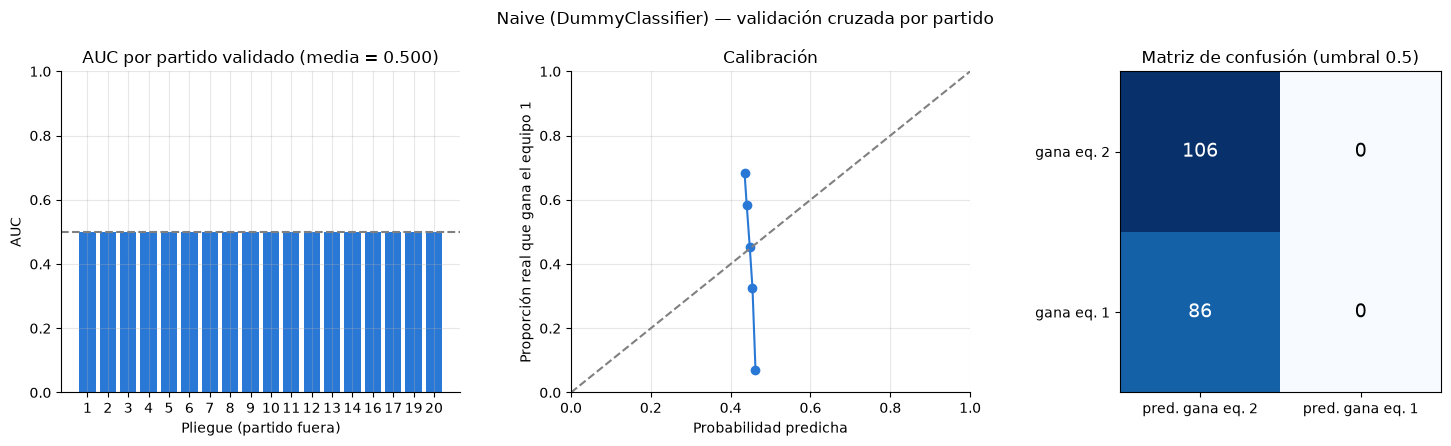

In [33]:
mod.graficar_evaluacion(y_train, p_naive, 'Naive (DummyClassifier) — validación cruzada por partido', pliegues)

In [34]:
# Tabla donde se acumulan los resultados de validación cruzada de cada modelo (se completa de la 2.3 a la 2.7)
resultados_cv = {'naive': mod.metricas(y_train, p_naive, pliegues)}
pd.DataFrame(resultados_cv).T.round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.5,0.0,18.0,0.696,0.251,0.552,0.0


**Resultado**

La evaluacion funciona y el naive da justo lo que tiene que dar, AUC de 0,5 en los 18 partidos que tienen las dos clases, log-loss de 0,696 y Brier de 0,251, que es casi lo mismo que decir siempre 0,5. Ese es el piso. Cualquier modelo de la 2.3 en adelante que no baje de 0,696 en log-loss y de 0,251 en Brier no aprendio nada de las variables, por mas bonito que se vea.

Lo que mas me sorprendio fue el AUC juntando todas las predicciones, 0,271, peor que tirar una moneda para un modelo que ni siquiera mira los datos. La razon esta en la correlacion de -0,98 entre lo que pasó en cada partido y lo que predice el naive, cuando sale un partido donde el equipo 1 gano mucho, el train que queda tiene menos victorias del equipo 1 y el modelo predice mas bajo justo ahi. Siempre al revés. Por eso el auc se mide adentro de cada partido y se promedia, como hace el profe con cross_val_score, y no con todo junto.

El mismo efecto se ve en la calibracion, los puntos quedan todos entre 0,43 y 0,46 y forman una linea que baja en vez de seguir la diagonal, entonces esa grafica sirve para comparar modelos que si muevan la probabilidad, no para el naive. Con umbral de 0,5 el naive dice equipo 2 en los 192 puntos, por eso el accuracy de 55 % y el F1 en cero. El accuracy solito engaña bastante aca, no ?

## 2.3 Regresión logística: el modelo base

**Objetivo:** estimar el modelo base de la fase 2 y entender qué variables de estilo y nivel mueven la probabilidad de ganar el punto.

**Decisiones**
- **D28:** la regresión logística es el modelo base contra el que se comparan los avanzados.
- **D37 (cómo se interpreta):**
  - Para leer los coeficientes, las 19 variables se **estandarizan** (media 0 y desviación 1, con la media y la desviación del train). Así el odds ratio de cada variable es el efecto de subirla **una desviación estándar**, y las variables se pueden comparar entre sí aunque estén en unidades distintas (metros, niveles, porcentajes).
  - Los p-valores usan errores estándar **agrupados por partido** (`cov_type='cluster'`), porque los puntos de un mismo partido los juegan las mismas cuatro personas y no son independientes. Con errores normales los p-valores saldrían más optimistas.
- **D33:** los faltantes se imputan con la mediana del train.
- **Referencia:** `03_Regresion_Logistica.ipynb`, en el mismo orden: primero por qué no sirve la regresión lineal, luego la mirada estadística con `statsmodels` y al final el modelo para predecir con `scikit-learn`.

### ¿Por qué no una regresión lineal?
La variable respuesta vale 1 si gana el equipo 1 y 0 si no. Como es un número, se podría intentar una regresión lineal múltiple:

$$y_i = \beta_0 + \beta_1 x_{1i} + \dots + \beta_{19} x_{19,i} + \varepsilon_i$$

El problema, como muestra el notebook 03:
1. La recta está definida en todos los reales, pero lo que queremos predecir es una probabilidad en [0, 1].
2. El ajuste ($R^2$) siempre es pobre, porque la respuesta solo toma dos valores.
3. Los supuestos (por ejemplo, errores normales) pierden sentido con una respuesta 0/1.

In [35]:
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Matriz de diseño para statsmodels: imputada con la mediana del train y estandarizada con el train (D33, D37)
mediana_train = X_train.median()
media_train, sd_train = X_train.fillna(mediana_train).mean(), X_train.fillna(mediana_train).std()
X_train_sm = sm.add_constant((X_train.fillna(mediana_train) - media_train) / sd_train, has_constant='add')

ols = sm.OLS(y_train, X_train_sm).fit()
pred_ols = ols.predict(X_train_sm)
print(f'R² de la regresión lineal: {ols.rsquared:.3f}')
print(f'Predicciones fuera de [0, 1]: {((pred_ols < 0) | (pred_ols > 1)).sum()} de {len(pred_ols)} | rango: {pred_ols.min():.2f} a {pred_ols.max():.2f}')

R² de la regresión lineal: 0.170
Predicciones fuera de [0, 1]: 1 de 192 | rango: -0.03 a 0.99


### El modelo de regresión logística
Se modela la probabilidad $\pi_i = P(Y_i = 1 \mid X_i)$ de que gane el equipo 1 con la transformación **logit**:

$$\ln\left(\frac{\pi_i}{1-\pi_i}\right) = \beta_0 + X_i^\top \beta \quad\Longleftrightarrow\quad \pi_i = \frac{1}{1 + e^{-(\beta_0 + X_i^\top \beta)}}, \qquad Y_i \sim \text{Bernoulli}(\pi_i)$$

- $\dfrac{\pi_i}{1-\pi_i}$ son los **odds**: cuántas veces es más probable que gane el equipo 1 que el equipo 2.
- **Odds ratio** $e^{\beta_j}$: cuánto se multiplican los odds cuando la variable $j$ sube una desviación estándar, con todo lo demás fijo. Mayor que 1 ayuda al equipo 1; menor que 1 lo perjudica; 1 no tiene efecto.
- Como todas las variables son `dif_` (equipo 1 − equipo 2), un odds ratio mayor que 1 quiere decir que **tener más de esa variable que el rival** ayuda a ganar el punto.

### Paso 1: la mirada estadística con `statsmodels`

In [36]:
# Estimación por máxima verosimilitud, con errores estándar agrupados por partido (D37)
logit_sm = sm.Logit(y_train, X_train_sm).fit(cov_type='cluster', cov_kwds={'groups': grupos_train}, disp=0)
print(logit_sm.summary())

                           Logit Regression Results                           
Dep. Variable:         punto_equipo_1   No. Observations:                  192
Model:                          Logit   Df Residuals:                      172
Method:                           MLE   Df Model:                           19
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1349
Time:                        20:45:04   Log-Likelihood:                -114.23
converged:                       True   LL-Null:                       -132.04
Covariance Type:              cluster   LLR p-value:                   0.01175
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -0.2650      0.113     -2.345      0.019      -0.487      -0.044
dif_suma_atacante                  0.1549      0.185      0.839      0.

### ¿Cómo se lee esta salida? (igual que en el 03)
- **`converged: True`:** el algoritmo encontró el máximo de la verosimilitud.
- **`LLR p-value`:** prueba si *todos* los $\beta_j$ son 0 a la vez. Si es menor que 0,05, el modelo aporta algo frente a solo el intercepto.
- **`Pseudo R-squ.` (McFadden):** $1 - \ell_{\text{modelo}} / \ell_{\text{nulo}}$. No se lee como el $R^2$ de la regresión lineal.
- **`coef`:** $\hat\beta_j$ en la escala del logit. **`P>|z|`:** el p-valor de $H_0: \beta_j = 0$. **`[0.025 0.975]`:** el intervalo del 95 %; si contiene el 0, el coeficiente no es significativo.

In [37]:
# Los betas traducidos a odds ratio (como en el 03)
tabla_or = pd.DataFrame({
    'beta': logit_sm.params,
    'error_std': logit_sm.bse,
    'p_valor': logit_sm.pvalues,
    'odds_ratio': np.exp(logit_sm.params),
})
ic = np.exp(logit_sm.conf_int())
tabla_or['OR_ic_inf'], tabla_or['OR_ic_sup'] = ic[0], ic[1]
tabla_or['significativo_5%'] = np.where(tabla_or['p_valor'] < 0.05, 'Sí', 'No')
tabla_or['efecto'] = np.where(tabla_or['beta'] > 0, '↑ prob. de ganar el equipo 1', '↓ prob. de ganar el equipo 1')

intercepto = tabla_or.loc['const']
tabla_or = tabla_or.drop(index='const').sort_values('beta', ascending=False)
print(f"Intercepto = {intercepto['beta']:.3f} -> probabilidad de que gane el equipo 1 con todas las dif_ en su media: {1 / (1 + np.exp(-intercepto['beta'])):.3f}")
tabla_or.round(3)

Intercepto = -0.265 -> probabilidad de que gane el equipo 1 con todas las dif_ en su media: 0.434


,beta,error_std,p_valor,odds_ratio,OR_ic_inf,OR_ic_sup,significativo_5%,efecto
dif_suma_nivel_padel,0.539,0.222,0.015,1.714,1.109,2.649,Sí,↑ prob. de ganar el equipo 1
dif_suma_pct_quieto,0.439,0.188,0.019,1.551,1.073,2.242,Sí,↑ prob. de ganar el equipo 1
dif_suma_imc,0.276,0.197,0.162,1.317,0.895,1.939,No,↑ prob. de ganar el equipo 1
dif_absdif_nivel_padel,0.224,0.127,0.076,1.252,0.976,1.604,No,↑ prob. de ganar el equipo 1
dif_suma_rafagas_por_min,0.207,0.285,0.468,1.230,0.704,2.150,No,↑ prob. de ganar el equipo 1
dif_suma_practica_otra_raqueta,0.169,0.131,0.196,1.185,0.917,1.531,No,↑ prob. de ganar el equipo 1
dif_suma_atacante,0.155,0.185,0.401,1.168,0.813,1.676,No,↑ prob. de ganar el equipo 1
dif_razon_area_m2,0.087,0.172,0.612,1.091,0.779,1.528,No,↑ prob. de ganar el equipo 1
dif_razon_vel_p90,0.043,0.279,0.878,1.044,0.604,1.803,No,↑ prob. de ganar el equipo 1
dif_suma_area_m2,0.035,0.349,0.919,1.036,0.522,2.055,No,↑ prob. de ganar el equipo 1


In [38]:
# Efectos marginales: el mismo beta, pero en escala de probabilidad
# dy/dx = cuánto cambia, en promedio, la probabilidad de que gane el equipo 1 al subir la variable una desviación estándar
print(logit_sm.get_margeff(at='overall', method='dydx').summary())

        Logit Marginal Effects       
Dep. Variable:         punto_equipo_1
Method:                          dydx
At:                           overall
                                    dy/dx    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
dif_suma_atacante                  0.0317      0.037      0.847      0.397      -0.042       0.105
dif_absdif_atacante               -0.0041      0.042     -0.097      0.922      -0.087       0.079
dif_absdif_prof_media_m           -0.0330      0.040     -0.822      0.411      -0.112       0.046
dif_suma_prof_sd_m                -0.0340      0.070     -0.483      0.629      -0.172       0.104
dif_suma_pct_en_su_lado           -0.0319      0.033     -0.972      0.331      -0.096       0.032
dif_suma_vel_p90                  -0.0650      0.057     -1.144      0.253      -0.176       0.046
dif_razon_vel_p90                  0.0088      0.057    

### Paso 2: el modelo para predecir con `scikit-learn`
Como en el 03, `LogisticRegression` trae **regularización L2 por defecto** (`C=1.0`), así que sus coeficientes salen encogidos hacia 0 y no son comparables con los de `statsmodels`. Aquí se usa para predecir: se estandariza dentro de un pipeline y se evalúa con la validación cruzada por partido de la 2.2.

In [39]:
logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
p_logistica = mod.predecir_cv(logistica, X_train, y_train, pliegues)

resultados_cv['logistica'] = mod.metricas(y_train, p_logistica, pliegues)
pd.DataFrame(resultados_cv).T.round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527


               precision    recall  f1-score   support

gana equipo 2       0.62      0.65      0.64       106
gana equipo 1       0.54      0.51      0.53        86

     accuracy                           0.59       192
    macro avg       0.58      0.58      0.58       192
 weighted avg       0.59      0.59      0.59       192



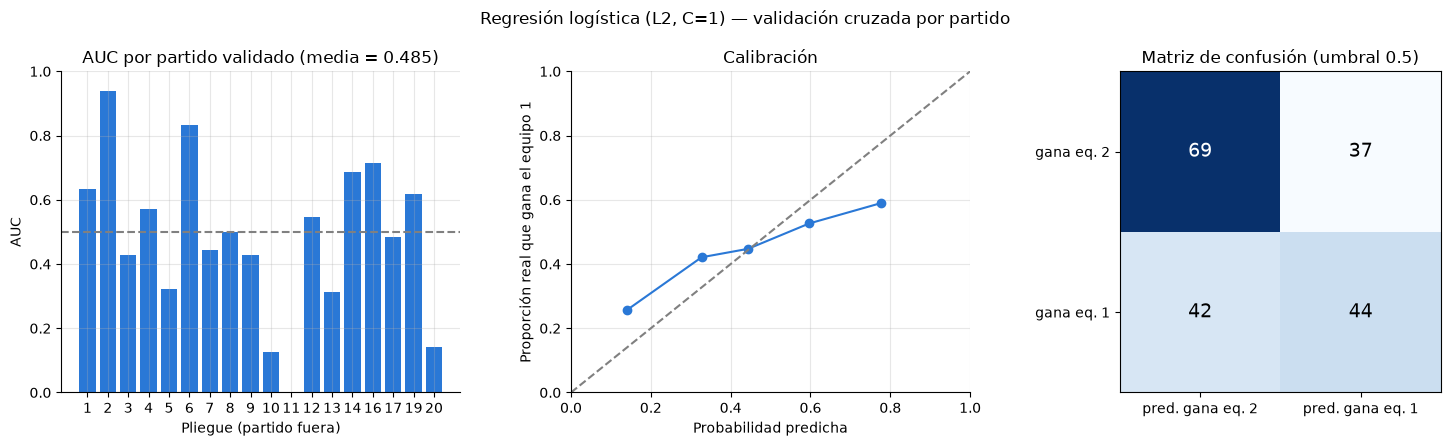

In [40]:
print(classification_report(y_train, (p_logistica >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_logistica, 'Regresión logística (L2, C=1) — validación cruzada por partido', pliegues)

**Resultado**

La regresion lineal saca un R² de 0,17 y una sola prediccion de 192 se sale de [0, 1], va de -0,03 a 0,99, o sea aca el problema de la recta casi no se nota porque las probabilidades de este juego estan todas en la mitad, nadie gana el 95 % de los puntos. Igual la logistica es la que tiene sentido para una respuesta de 0 y 1, asi que seguimos con esa.

En statsmodels el modelo completo si aporta frente a solo el intercepto, el LLR p-value da 0,012 y el pseudo R² de McFadden 0,135. De las 19 variables solo dos salen significativas al 5 % con los errores agrupados por partido. dif_suma_nivel_padel con odds ratio de 1,71, cada desviacion estandar mas de nivel sumado que el rival multiplica por 1,71 los odds de ganar el punto. Y dif_suma_pct_quieto con 1,55, la pareja que pasa mas tiempo quieta que el rival gana mas puntos. Esa segunda no me la esperaba. Puede ser que quedarse quieto sea estar bien parado y no tener que correr detras de la pelota, pero eso es una hipotesis mia, el modelo solo dice que van juntas, no que una cause la otra.

Lo que si preocupa es la logistica de scikit-learn con C=1, en validacion por partido saca log-loss de 0,715 y AUC de 0,485, peor que el naive en las dos. Con 192 puntos y 19 variables el modelo se aprende los partidos de entrenamiento y falla en el que no vio, el p-valor bonito de statsmodels es dentro de muestra y la validacion es fuera. por eso hace falta la 2.4

## 2.4 LASSO, Ridge y árbol de decisión

**Objetivo:** reducir las 19 variables a las que de verdad aportan (D27) y probar un primer modelo no lineal que se pueda leer.

**Decisiones**
- **D27:** LASSO (L1) y Ridge (L2) se aplican dentro de la validación cruzada por partido, para no inflar las métricas. La meta era quedar con 10 a 15 variables.
- **D38 (cómo se elige la perilla):** la fuerza de la penalización (`C`) y la profundidad del árbol (`max_depth`) se eligen con el **log-loss** de la validación cruzada (2.2), porque es la métrica de la probabilidad, que es lo que usa la fase 4. El AUC por pliegue se muestra al lado.
- **Referencia:** `Regresion_Ridge_Lasso.ipynb` y `Arboles_regresion. 1.ipynb` (de estudiantes; se adaptan a clasificación).

### Ridge y LASSO: ponerle disciplina al modelo
Con 192 puntos y 19 variables, la regresión logística puede **sobreajustarse**: aprende el ruido de los partidos de entrenamiento y falla en los nuevos. Ridge y LASSO agregan un castigo al tamaño de los coeficientes:

$$\text{Ridge (L2)}: \quad -\ell(\beta) + \lambda \sum_j \beta_j^2 \qquad\qquad \text{LASSO (L1)}: \quad -\ell(\beta) + \lambda \sum_j |\beta_j|$$

- **Ridge** encoge todos los coeficientes hacia 0, pero ninguno llega a 0: conserva todas las variables.
- **LASSO** puede dejar coeficientes **exactamente en 0**: elimina variables. Por eso sirve para seleccionar.
- **En `scikit-learn` (versión 1.8):** el tipo de castigo se elige con `l1_ratio` (1 = LASSO, 0 = Ridge). La perilla es $C = 1/\lambda$: **C pequeño = más castigo** = coeficientes más chicos (y en LASSO, menos variables). Las variables tienen que estar estandarizadas para que el castigo sea parejo.

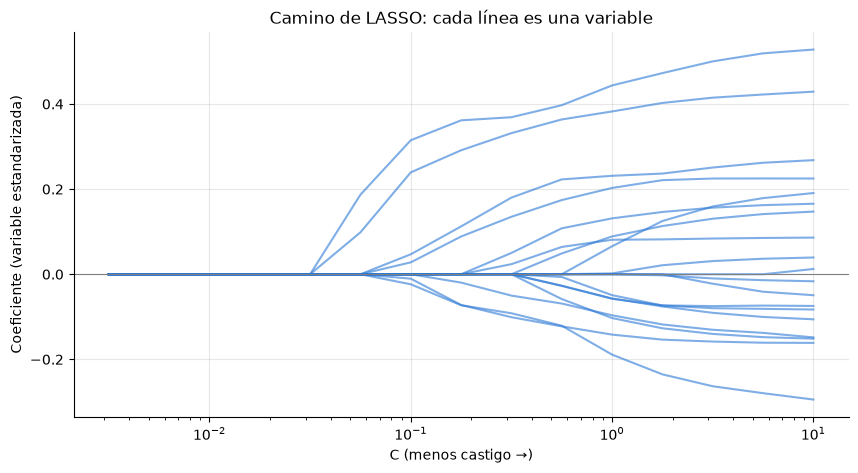

In [41]:
# Camino de LASSO: cómo cambian los coeficientes al aflojar el castigo (C de menor a mayor)
valores_C = np.logspace(-2.5, 1, 15)
X_train_std = (X_train.fillna(mediana_train) - media_train) / sd_train
camino = pd.DataFrame({C: LogisticRegression(l1_ratio=1, solver='liblinear', C=C).fit(X_train_std, y_train).coef_[0]
                       for C in valores_C}, index=var.VARIABLES_MODELO).T

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(camino.index, camino.values, color='#2a78d6', alpha=0.6)
ax.set(xscale='log', xlabel='C (menos castigo →)', ylabel='Coeficiente (variable estandarizada)', title='Camino de LASSO: cada línea es una variable')
ax.axhline(0, color='gray', linewidth=0.8)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

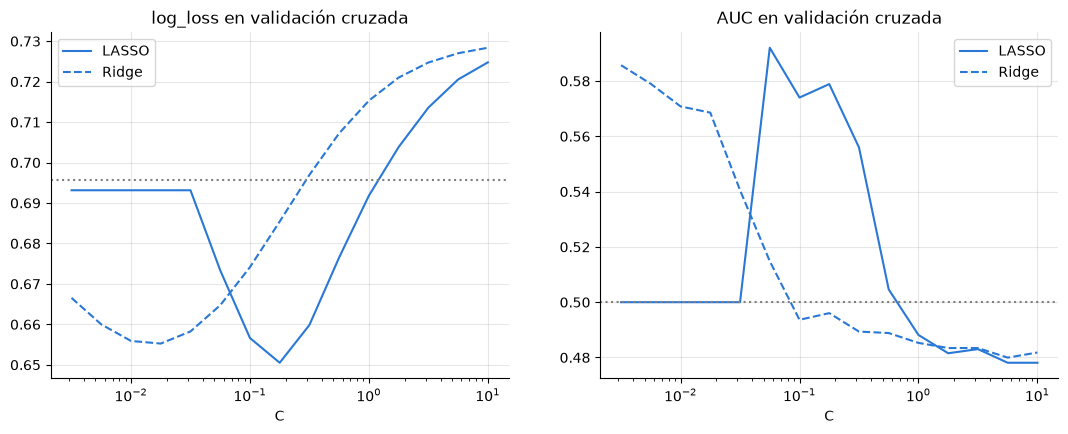

,C,log_loss,AUC
modelo,,,
LASSO,0.1778,0.6505,0.5789
Ridge,0.0178,0.6552,0.5686


In [42]:
# Selección de C con la validación cruzada por partido (D38), para LASSO y para Ridge
filas = []
for C in valores_C:
    for nombre, l1 in [('LASSO', 1), ('Ridge', 0)]:
        m = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=l1, solver='liblinear', C=C))
        met = mod.metricas(y_train, mod.predecir_cv(m, X_train, y_train, pliegues), pliegues)
        filas.append({'modelo': nombre, 'C': C, 'log_loss': met['log_loss'], 'AUC': met['AUC']})
curva_C = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, metrica in zip(ax, ['log_loss', 'AUC']):
    for nombre, estilo in [('LASSO', '-'), ('Ridge', '--')]:
        d = curva_C[curva_C['modelo'] == nombre]
        a.plot(d['C'], d[metrica], estilo, color='#2a78d6', label=nombre)
    a.set(xscale='log', xlabel='C', title=f'{metrica} en validación cruzada')
    a.grid(alpha=0.3)
    a.spines[['top', 'right']].set_visible(False)
    a.legend()
ax[0].axhline(resultados_cv['naive']['log_loss'], color='gray', linestyle=':')
ax[1].axhline(0.5, color='gray', linestyle=':')
plt.show()

mejor_C = curva_C.loc[curva_C.groupby('modelo')['log_loss'].idxmin()].set_index('modelo')
mejor_C.round(4)

In [43]:
# Modelos con el mejor C, evaluados igual que los demás
lasso = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver='liblinear', C=mejor_C.loc['LASSO', 'C']))
ridge = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=0, solver='liblinear', C=mejor_C.loc['Ridge', 'C']))
p_lasso = mod.predecir_cv(lasso, X_train, y_train, pliegues)
p_ridge = mod.predecir_cv(ridge, X_train, y_train, pliegues)
resultados_cv['lasso'] = mod.metricas(y_train, p_lasso, pliegues)
resultados_cv['ridge'] = mod.metricas(y_train, p_ridge, pliegues)

# Variables que sobreviven a LASSO: ajustado con todo el train y el mejor C
coef_lasso = pd.Series(mod.con_imputacion(lasso).fit(X_train, y_train)[-1][-1].coef_[0], index=var.VARIABLES_MODELO)
seleccion_lasso = coef_lasso[coef_lasso != 0].sort_values(key=abs, ascending=False)
print(f"LASSO conserva {len(seleccion_lasso)} de {len(coef_lasso)} variables:")
display(seleccion_lasso.round(3).to_frame('coeficiente (estandarizado)'))
pd.DataFrame(resultados_cv).T.round(3)

LASSO conserva 7 de 19 variables:


,coeficiente (estandarizado)
dif_suma_nivel_padel,0.361
dif_suma_pct_quieto,0.291
dif_suma_imc,0.112
dif_absdif_nivel_padel,0.089
dif_suma_vel_p90,-0.073
dif_absdif_prof_media_m,-0.072
dif_suma_prof_sd_m,-0.020


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578


### Árbol de decisión
Un árbol parte los datos con preguntas del tipo «¿`dif_suma_nivel_padel` ≤ 1,5?», una tras otra, hasta llegar a una hoja. La probabilidad de cada hoja es la proporción de puntos que ganó el equipo 1 en esa hoja. A diferencia de la logística, puede encontrar **interacciones** (por ejemplo, que la velocidad solo importe cuando el nivel es parejo).

- **`max_depth`:** cuántas preguntas seguidas puede hacer. Con más profundidad, el árbol memoriza el train.
- **`min_samples_leaf`:** cuántos puntos mínimo tiene cada hoja. Se fija en 10 para que ninguna probabilidad salga de muy pocos puntos (con 192 puntos, hojas más chicas son ruido).
- Como en el notebook de árboles, `max_depth` se elige con una curva train vs validación.

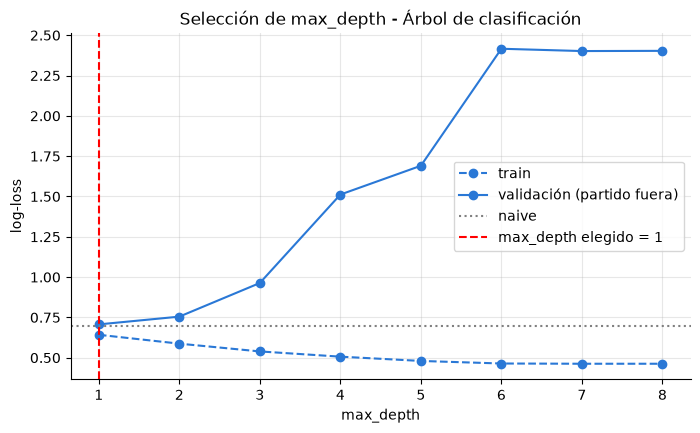

,log_loss_train,log_loss_validacion,AUC_validacion
max_depth,,,
1,0.642,0.707,0.481
2,0.587,0.755,0.513
3,0.539,0.963,0.480
4,0.507,1.512,0.481
5,0.480,1.690,0.531
6,0.464,2.416,0.522
7,0.463,2.402,0.524
8,0.463,2.403,0.524


In [44]:
from sklearn.metrics import log_loss
from sklearn.tree import DecisionTreeClassifier, plot_tree

filas = []
for prof in range(1, 9):
    arbol_tmp = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=10, random_state=datos.SEMILLA)
    p_val = mod.predecir_cv(arbol_tmp, X_train, y_train, pliegues)
    p_tr = mod.con_imputacion(arbol_tmp).fit(X_train, y_train).predict_proba(X_train)[:, 1]
    filas.append({'max_depth': prof, 'log_loss_train': log_loss(y_train, p_tr),
                  'log_loss_validacion': log_loss(y_train, p_val), 'AUC_validacion': mod.metricas(y_train, p_val, pliegues)['AUC']})
curva_arbol = pd.DataFrame(filas).set_index('max_depth')
PROF = curva_arbol['log_loss_validacion'].idxmin()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curva_arbol.index, curva_arbol['log_loss_train'], 'o--', color='#2a78d6', label='train')
ax.plot(curva_arbol.index, curva_arbol['log_loss_validacion'], 'o-', color='#2a78d6', label='validación (partido fuera)')
ax.axhline(resultados_cv['naive']['log_loss'], color='gray', linestyle=':', label='naive')
ax.axvline(PROF, color='red', linestyle='--', label=f'max_depth elegido = {PROF}')
ax.set(xlabel='max_depth', ylabel='log-loss', title='Selección de max_depth - Árbol de clasificación')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
plt.show()
curva_arbol.round(3)

,importancia
dif_suma_nivel_padel,1.0


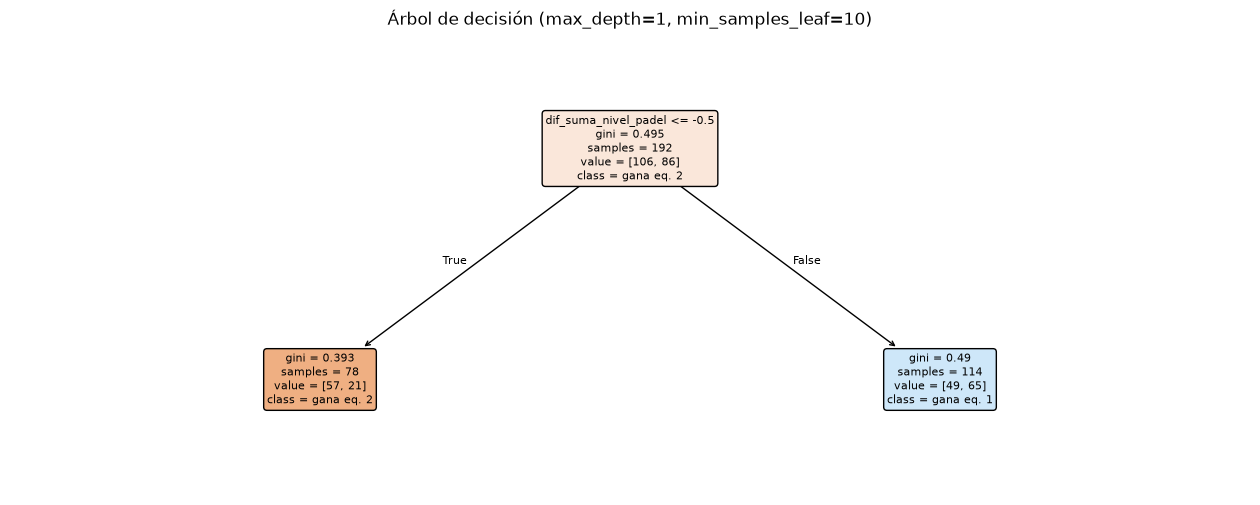

In [45]:
arbol = DecisionTreeClassifier(max_depth=PROF, min_samples_leaf=10, random_state=datos.SEMILLA)
p_arbol = mod.predecir_cv(arbol, X_train, y_train, pliegues)
resultados_cv['arbol'] = mod.metricas(y_train, p_arbol, pliegues)

arbol_final = mod.con_imputacion(arbol).fit(X_train, y_train)[-1]
importancias = pd.Series(arbol_final.feature_importances_, index=var.VARIABLES_MODELO).sort_values(ascending=False)
display(importancias[importancias > 0].round(3).to_frame('importancia'))

plt.figure(figsize=(16, 6))
plot_tree(arbol_final, feature_names=var.VARIABLES_MODELO, class_names=['gana eq. 2', 'gana eq. 1'], filled=True, rounded=True, fontsize=8)
plt.title(f'Árbol de decisión (max_depth={PROF}, min_samples_leaf=10)')
plt.show()

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584


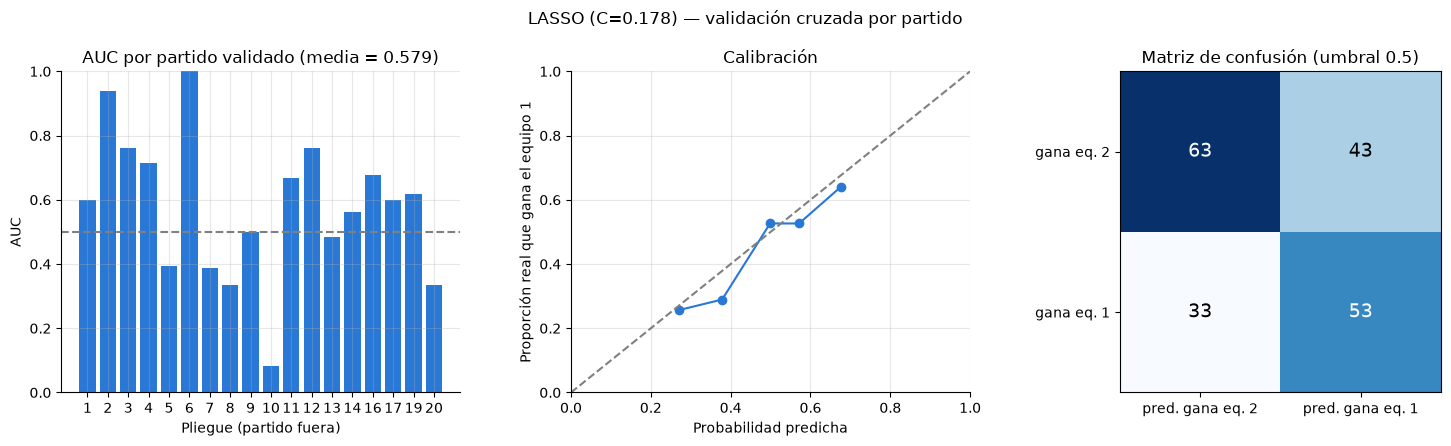

In [46]:
# Comparación de todos los modelos de la primera mitad de la fase 2 (validación cruzada por partido)
comparacion = pd.DataFrame(resultados_cv).T
display(comparacion.round(3))
mod.graficar_evaluacion(y_train, p_lasso, f"LASSO (C={mejor_C.loc['LASSO', 'C']:.3f}) — validación cruzada por partido", pliegues)

**Resultado**

Castigar los coeficientes si funciona. LASSO con C=0,178 baja el log-loss a 0,651 y el Brier a 0,229, y Ridge con C=0,018 queda casi igual con 0,655 y 0,231, los dos por debajo del naive de 0,696 y 0,251, entonces ya hay algo que el modelo aprende de las variables y que se sostiene en partidos que no vio. El AUC sube a 0,579 en LASSO pero con desviacion de 0,225 entre partidos, hay pliegues de 0,08 y otros de 1,0, con 6 a 13 puntos por partido el AUC de cada uno es muy ruidoso.

LASSO se queda con 7 de las 19 variables, no con 10 a 15 como decia la meta del D27. Las dos de arriba son las mismas que salieron significativas en la 2.3, dif_suma_nivel_padel y dif_suma_pct_quieto, despues vienen imc, el desbalance de nivel, velocidad p90, la diferencia de profundidad entre compañeros y prof_sd con coeficientes ya chiquitos. Del estilo puro, atacante y absdif_atacante, LASSO no deja nada. Eso no quiere decir que el estilo no importe, quiere decir que con 192 puntos no alcanza a separarse del ruido. Hay que decidir con el equipo si se fuerza a 10, se quedan las 7 o se usa Ridge que deja las 19 con pesos chicos, para la fase 4 Ridge tiene la ventaja de que el estilo sigue entrando.

El arbol sale mal. La mejor profundidad es 1, una sola pregunta sobre dif_suma_nivel_padel, y aun asi su log-loss de 0,707 queda peor que el naive, y con mas profundidad el train mejora y la validacion se dispara hasta 2,4, sobreajuste de libro. Con tan pocos puntos un arbol solo no sirve, a ver si el random forest y el boosting de la segunda mitad lo arreglan promediando muchos arboles ?

## 2.5 Random Forest, SVM y hyperparameter tuning

**Objetivo:** probar dos modelos avanzados y elegir sus hiperparámetros con la misma validación por partido de las secciones anteriores, para compararlos de forma justa con LASSO (log-loss 0,651).

**Ejecución:** esta sección depende de las variables de train y de los modelos definidos en 2.1–2.4. Después de reiniciar el kernel, ejecuta las celdas anteriores en orden (en VS Code, usa **Run All Above** sobre la primera celda de 2.5); ejecutar solo una celda de esta sección no restaura ese estado.

**Decisiones**
- **D39 (cómo se busca):** todas las combinaciones se comparan con los 20 pliegues por partido de la 2.1 y se eligen por log-loss de las predicciones reunidas (D38). Se usa una función propia (`buscar`) y no `GridSearchCV`: este promedia el log-loss de cada pliegue, mientras que aquí se calcula sobre todas las predicciones juntas, igual que en la 2.2 (D36). La grilla SVM se evalúa completa; la búsqueda aleatoria se reserva para el espacio más amplio del Random Forest. No se usa optimización bayesiana: en el Random Forest la superficie observada es plana (las ocho mejores combinaciones de la grilla y de la búsqueda aleatoria quedan entre log-loss 0,651 y 0,655), así que una búsqueda más inteligente tiene poco dónde mejorar; la grilla SVM, con solo 20 combinaciones, se evalúa completa (sus ocho mejores van de 0,652 a 0,674). **Limitación:** los hiperparámetros se eligen con los mismos pliegues con los que se reporta (sin validación anidada), así que la métrica del mejor modelo es algo optimista. El bootstrap por partido del final resume la incertidumbre entre las predicciones observadas, pero no elimina ese sesgo de selección.
- **D40 (Random Forest):** se comparan 100, 300 y 500 árboles, junto con profundidad, tamaño mínimo de hoja, variables candidatas y fracción de observaciones por árbol. El tamaño mínimo de hoja nunca baja de 3.
- **D41 (SVM):** el escalado se ajusta dentro de cada pliegue. Se comparan kernels `rbf` y `linear`, `C` y `gamma`. Las probabilidades se calibran con una regresión logística sobre puntajes *out-of-fold*; también esa calibración separa partidos, nunca puntos al azar. Para `svm_lasso`, los hiperparámetros se eligieron con las 19 variables y se reutilizaron tal cual con la selección de LASSO dentro de cada pliegue; por eso la comparación con `svm` es aproximada y, si esta variante pasa a la 2.7, convendría reajustarlos.
- El test (los 5 partidos) sigue sin tocarse hasta la 2.8.

In [47]:
# Verificación de requisitos de la 2.5: aquí se avisa de todo lo que falte (las demás celdas ya no repiten el aviso)
requisitos = {
    'celda de configuración del notebook': ['np', 'pd', 'display'],
    '1.10–1.11 (variables del modelo)': ['var'],
    '2.1 (partición por partido)': ['plt', 'X_train', 'y_train', 'grupos_train', 'pliegues'],
    '2.2 (evaluación común y naive)': ['classification_report', 'p_naive'],
    '2.3–2.4 (LASSO y Ridge)': ['resultados_cv', 'log_loss', 'make_pipeline', 'StandardScaler',
                                'p_lasso', 'p_ridge', 'mejor_C', 'seleccion_lasso'],
}
faltan = {sec: [n for n in nombres if n not in globals()] for sec, nombres in requisitos.items()}
faltan = {sec: n for sec, n in faltan.items() if n}
if faltan:
    detalle = '\n'.join(f'  - {sec}: {", ".join(n)}' for sec, n in faltan.items())
    raise RuntimeError('Faltan objetos que crean las celdas anteriores a la 2.5:\n' + detalle +
                       '\nReinicie el kernel y ejecute el notebook en orden (Run All), o Run All Above sobre esta celda.')

assert len(pliegues) == grupos_train.nunique() == 20, 'Se esperaban 20 pliegues (uno por partido de train, D35).'
assert {'naive', 'lasso', 'ridge'} <= set(resultados_cv), 'resultados_cv debe traer naive, lasso y ridge de la 2.2–2.4.'
print(f'Requisitos de la 2.5 completos: {X_train.shape[0]} puntos x {X_train.shape[1]} variables, {len(pliegues)} pliegues.')

Requisitos de la 2.5 completos: 192 puntos x 19 variables, 20 pliegues.


In [48]:
import time
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid, ParameterSampler
from scipy.stats import randint
from src import datos, modelo as mod

def ajustar_svm_calibrado(modelo, X, y, grupos):
    """Ajusta SVM y calibrador sigmoide usando predicciones OOF separadas por partido."""
    scores_oof = np.full(len(X), np.nan)
    cv_interno = GroupKFold(n_splits=5)
    for train, validacion in cv_interno.split(X, y, groups=grupos):
        ajustado = mod.con_imputacion(clone(modelo)).fit(X.iloc[train], y.iloc[train])
        scores_oof[validacion] = ajustado.decision_function(X.iloc[validacion])

    if np.isnan(scores_oof).any():
        raise ValueError('La calibración interna no produjo una predicción para cada punto.')

    calibrador = LogisticRegression(random_state=datos.SEMILLA).fit(scores_oof.reshape(-1, 1), y)
    modelo_ajustado = mod.con_imputacion(clone(modelo)).fit(X, y)
    return modelo_ajustado, calibrador

def predecir_cv_svm(modelo, X, y, grupos, pliegues):
    """Predice probabilidades SVM con calibración agrupada dentro de cada pliegue externo."""
    p = pd.Series(np.nan, index=X.index, name='p_equipo_1')
    for train, validacion in pliegues:
        modelo_ajustado, calibrador = ajustar_svm_calibrado(
            modelo, X.iloc[train], y.iloc[train], grupos.iloc[train]
        )
        scores = modelo_ajustado.decision_function(X.iloc[validacion]).reshape(-1, 1)
        p.iloc[validacion] = calibrador.predict_proba(scores)[:, 1]
    return p

def buscar(base, combinaciones, nombre, grupos=None):
    """Ordena combinaciones por log-loss de validación por partido (D38)."""
    filas, t0 = [], time.perf_counter()
    for params in combinaciones:
        m = clone(base).set_params(**params)
        if grupos is None:
            p = mod.predecir_cv(m, X_train, y_train, pliegues)
        else:
            p = predecir_cv_svm(m, X_train, y_train, grupos, pliegues)
        met = mod.metricas(y_train, p, pliegues)
        filas.append({**params, 'log_loss': met['log_loss'], 'Brier': met['Brier'], 'AUC': met['AUC']})
    print(f'{nombre}: {len(filas)} combinaciones en {time.perf_counter() - t0:.0f} s')
    return pd.DataFrame(filas).sort_values('log_loss').reset_index(drop=True)

def mejores_params(tabla, metricas=('log_loss', 'Brier', 'AUC', 'metodo')):
    """Toma la mejor fila y devuelve sus hiperparámetros (los enteros vuelven a ser enteros)."""
    fila = tabla.drop(columns=list(metricas), errors='ignore').iloc[0].dropna().to_dict()
    for k, v in fila.items():
        if k.split('__')[-1] in ('n_estimators', 'max_depth', 'min_samples_leaf', 'min_child_weight') and float(v).is_integer():
            fila[k] = int(v)
    return fila

### Random Forest
Un Random Forest promedia muchos árboles, cada uno entrenado con una muestra bootstrap de los puntos y con un subconjunto aleatorio de variables en cada pregunta. Promediar árboles poco correlacionados baja la varianza que hacía fallar al árbol solo (2.4). Los hiperparámetros que importan aquí:

- **`n_estimators`:** se comparan 100, 300 y 500 árboles; más árboles aumentan el costo y estabilizan el promedio.
- **`max_depth` y `min_samples_leaf`:** controlan qué tan memorizador es cada árbol. Con árboles completos (`min_samples_leaf=1`) las probabilidades salen extremas (0 o 1), y eso castiga el log-loss.
- **`max_features`:** cuántas variables mira cada pregunta. Menos variables = árboles más distintos entre sí.
- **`max_samples`:** qué fracción de los puntos ve cada árbol. Valores menores decorrelacionan más los árboles.

**Sobre el OOB:** el error *out-of-bag* usa, para cada punto, los árboles que no lo vieron, pero esos árboles suelen haber visto otros puntos del mismo partido, que se le parecen. Por eso el OOB podría salir optimista; la medida alineada con la separación de esta evaluación es la validación por partido. En la celda de abajo se muestran los dos.

In [49]:
# Random Forest "de fábrica" (como en RandomForest.ipynb): 500 árboles completos
rf_base = RandomForestClassifier(n_estimators=500, max_features='sqrt', random_state=datos.SEMILLA, n_jobs=-1)
p_rf_base = mod.predecir_cv(rf_base, X_train, y_train, pliegues)
resultados_cv['rf_base'] = mod.metricas(y_train, p_rf_base, pliegues)

# Chequeo de sobreajuste: train vs validación por partido, y el OOB (posiblemente optimista, ver arriba)
rf_diag = mod.con_imputacion(clone(rf_base).set_params(oob_score=True)).fit(X_train, y_train)
p_tr = rf_diag.predict_proba(X_train)[:, 1]
print(f"log-loss  train: {log_loss(y_train, p_tr):.3f} | validación por partido: {resultados_cv['rf_base']['log_loss']:.3f}")
print(f"accuracy  OOB:   {rf_diag[-1].oob_score_:.3f} | validación por partido: {resultados_cv['rf_base']['accuracy']:.3f}")
pd.DataFrame(resultados_cv).T.round(3)

log-loss  train: 0.189 | validación por partido: 0.679
accuracy  OOB:   0.604 | validación por partido: 0.599


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503


In [50]:
# Grid Search: 3 x 4 x 3 x 2 = 72 combinaciones
grid_rf = ParameterGrid({
    'n_estimators': [100, 300, 500],
    'max_depth': [2, 3, 5, None],
    'min_samples_leaf': [5, 10, 20],
    'max_features': ['sqrt', 0.5],
})
res_grid_rf = buscar(RandomForestClassifier(random_state=datos.SEMILLA, n_jobs=-1), grid_rf, 'Grid Search RF')
res_grid_rf.head(8).round(3)

Grid Search RF: 72 combinaciones en 549 s


,max_depth,max_features,min_samples_leaf,n_estimators,log_loss,Brier,AUC
0,NaN,sqrt,10,300,0.653,0.231,0.595
1,3.0,sqrt,10,500,0.653,0.231,0.592
2,5.0,sqrt,10,300,0.653,0.231,0.600
3,5.0,sqrt,10,500,0.653,0.231,0.570
4,3.0,sqrt,10,300,0.653,0.231,0.593
5,NaN,sqrt,10,500,0.653,0.231,0.586
6,NaN,sqrt,20,300,0.654,0.231,0.600
7,5.0,sqrt,20,300,0.654,0.231,0.600


In [51]:
# Random Search: 40 combinaciones al azar de un espacio más amplio (como en el 05)
dist_rf = {
    'n_estimators': [100, 300, 500],
    'max_depth': randint(2, 9),
    'min_samples_leaf': randint(3, 31),
    'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.8],
    'max_samples': [0.5, 0.7, 0.9, None],
}
random_rf = ParameterSampler(dist_rf, n_iter=40, random_state=datos.SEMILLA)
res_random_rf = buscar(RandomForestClassifier(random_state=datos.SEMILLA, n_jobs=-1), random_rf, 'Random Search RF')
res_random_rf.head(8).round(3)

Random Search RF: 40 combinaciones en 230 s


,max_depth,max_features,max_samples,min_samples_leaf,n_estimators,log_loss,Brier,AUC
0,8,sqrt,NaN,14,300,0.651,0.229,0.601
1,8,sqrt,0.7,8,500,0.651,0.230,0.584
2,6,log2,0.5,9,300,0.652,0.230,0.602
3,6,log2,NaN,9,500,0.653,0.231,0.583
4,8,0.5,0.7,17,100,0.654,0.231,0.591
5,5,0.8,0.9,28,300,0.654,0.231,0.589
6,3,sqrt,0.7,3,100,0.654,0.231,0.602
7,6,0.8,NaN,22,500,0.655,0.231,0.584


,mejor log-loss por método
metodo,
grid,0.653
random,0.651


Mejores hiperparámetros del Random Forest: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 14, 'n_estimators': 300}


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585


               precision    recall  f1-score   support

gana equipo 2       0.67      0.72      0.69       106
gana equipo 1       0.62      0.56      0.59        86

     accuracy                           0.65       192
    macro avg       0.64      0.64      0.64       192
 weighted avg       0.64      0.65      0.64       192



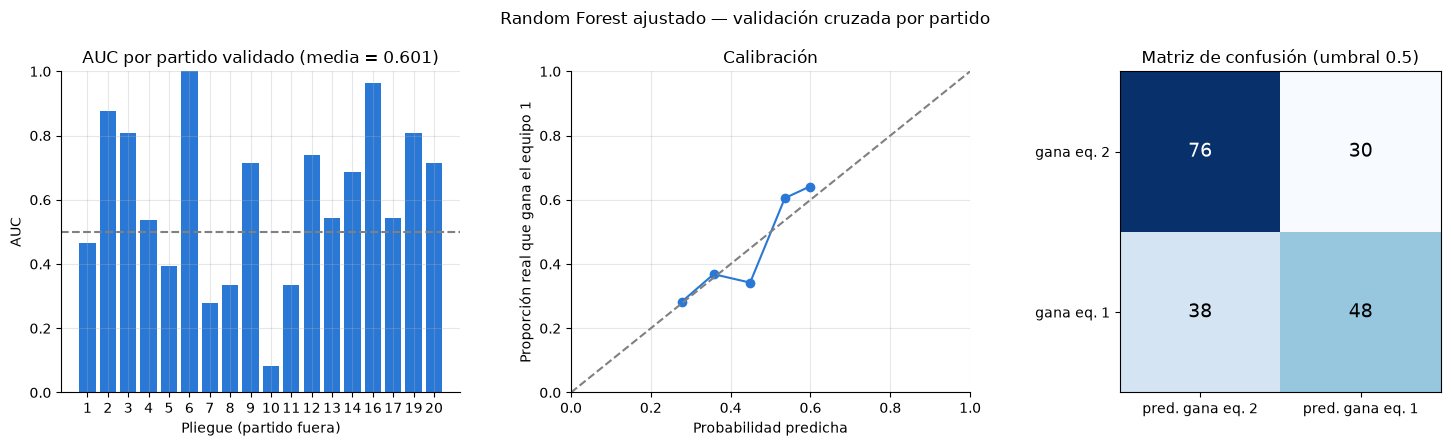

,importancia_RF,la_eligio_LASSO
dif_suma_nivel_padel,0.130,True
dif_suma_pct_quieto,0.091,True
dif_suma_prof_sd_m,0.088,True
dif_suma_imc,0.088,True
dif_suma_estatura_cm,0.085,False
dif_absdif_prof_media_m,0.083,True
dif_suma_rafagas_por_min,0.080,False
dif_razon_vel_p90,0.068,False
dif_suma_area_m2,0.067,False
dif_suma_vel_p90,0.066,True


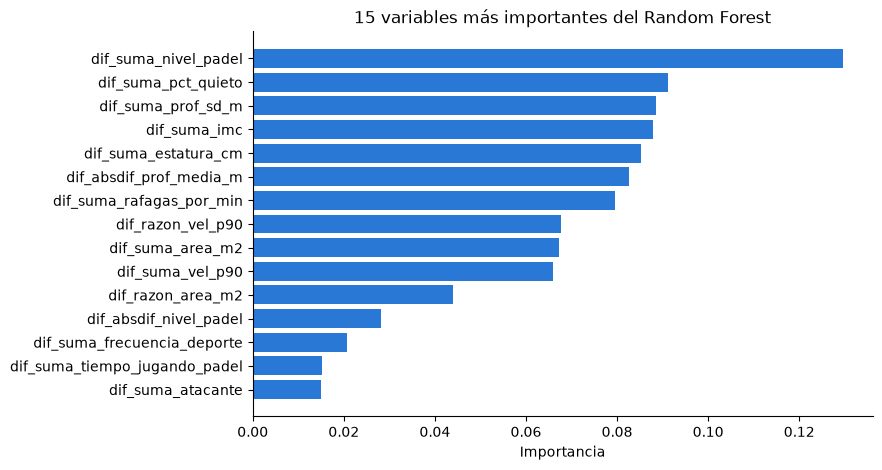

In [52]:
# Se juntan las búsquedas y se elige la combinación con menor log-loss (D38)
tablas = [res_grid_rf.assign(metodo='grid'), res_random_rf.assign(metodo='random')]
res_rf = pd.concat(tablas, ignore_index=True).sort_values('log_loss').reset_index(drop=True)
display(res_rf.groupby('metodo')['log_loss'].min().round(3).to_frame('mejor log-loss por método'))

mejores_rf = mejores_params(res_rf)
print('Mejores hiperparámetros del Random Forest:', mejores_rf)

rf = RandomForestClassifier(random_state=datos.SEMILLA, n_jobs=-1, **mejores_rf)
p_rf = mod.predecir_cv(rf, X_train, y_train, pliegues)
resultados_cv['rf'] = mod.metricas(y_train, p_rf, pliegues)
display(pd.DataFrame(resultados_cv).T.round(3))

print(classification_report(y_train, (p_rf >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_rf, 'Random Forest ajustado — validación cruzada por partido', pliegues)

# Importancia de variables (como en RandomForest.ipynb) y cuáles eligió LASSO
rf_final = mod.con_imputacion(rf).fit(X_train, y_train)[-1]
imp_rf = pd.Series(rf_final.feature_importances_, index=var.VARIABLES_MODELO).sort_values(ascending=False)
tabla_imp = imp_rf.head(10).round(3).to_frame('importancia_RF')
tabla_imp['la_eligio_LASSO'] = tabla_imp.index.isin(seleccion_lasso.index)
display(tabla_imp)

top = imp_rf.head(15).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color='#2a78d6')
plt.xlabel('Importancia'); plt.title('15 variables más importantes del Random Forest')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

### SVM
Una SVM busca la frontera que deja el mayor margen entre las dos clases (aquí, puntos que gana el equipo 1 y puntos que gana el equipo 2). Los hiperparámetros:

- **`C`:** qué tanto se castigan los puntos que caen del lado equivocado del margen. `C` bajo = frontera más simple y más tolerante a errores. Con clases tan mezcladas podría convenir un `C` bajo, pero se prueba en la grilla en lugar de suponerlo.
- **`kernel`:** `linear` traza una frontera recta; `rbf` permite una curva.
- **`gamma` (solo `rbf`):** qué tan lejos llega la influencia de cada punto. `gamma` alto = frontera muy ondulada que memoriza.

**Dos precauciones:** la SVM es sensible a la escala, por eso `StandardScaler` va dentro del pipeline y se ajusta en cada pliegue. La SVM entrega una distancia; se convierte a probabilidad con una regresión logística entrenada sobre puntajes *out-of-fold* de partidos completos, sin la validación interna aleatoria de `probability=True`.

In [53]:
# SVM "de fábrica" (C=1, rbf, gamma='scale'), con escalado dentro del pipeline
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_base = make_pipeline(StandardScaler(), SVC())
p_svm_base = predecir_cv_svm(svm_base, X_train, y_train, grupos_train, pliegues)
resultados_cv['svm_base'] = mod.metricas(y_train, p_svm_base, pliegues)
pd.DataFrame(resultados_cv).T.round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534


Grid Search SVM: 20 combinaciones en 16 s


,svc__C,svc__gamma,svc__kernel,log_loss,Brier,AUC
0,1.00,0.01,rbf,0.652,0.230,0.542
1,1.00,0.003,rbf,0.653,0.231,0.567
2,1.00,scale,rbf,0.654,0.231,0.481
3,1.00,0.1,rbf,0.658,0.234,0.476
4,0.01,NaN,linear,0.661,0.233,0.558
5,10.00,0.003,rbf,0.664,0.235,0.535
6,10.00,0.01,rbf,0.673,0.240,0.487
7,0.10,scale,rbf,0.674,0.241,0.519


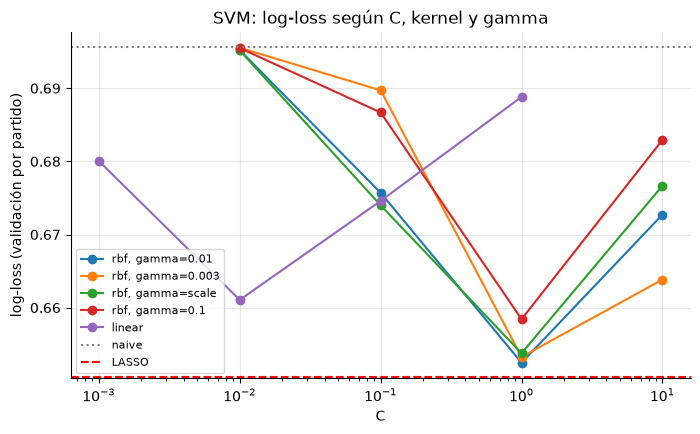

In [54]:
# Grid Search: la base es pequeña (192 puntos), así que una grilla completa es razonable (como en SVM_1, 2.4)
grid_svm = ParameterGrid([
    {'svc__kernel': ['rbf'], 'svc__C': [0.01, 0.1, 1, 10], 'svc__gamma': ['scale', 0.003, 0.01, 0.1]},
    {'svc__kernel': ['linear'], 'svc__C': [0.001, 0.01, 0.1, 1]},
])
res_svm = buscar(svm_base, grid_svm, 'Grid Search SVM', grupos=grupos_train)
display(res_svm.head(8).round(3))

# Log-loss contra C, una línea por kernel/gamma
fig, ax = plt.subplots(figsize=(8, 4.5))
d_plot = res_svm.assign(gamma=res_svm['svc__gamma'].astype(str))
for (kern, gam), d in d_plot.groupby(['svc__kernel', 'gamma'], sort=False):
    d = d.sort_values('svc__C')
    ax.plot(d['svc__C'], d['log_loss'], 'o-', label=kern if gam == 'nan' else f'{kern}, gamma={gam}')
ax.axhline(resultados_cv['naive']['log_loss'], color='gray', linestyle=':', label='naive')
ax.axhline(resultados_cv['lasso']['log_loss'], color='red', linestyle='--', label='LASSO')
ax.set(xscale='log', xlabel='C', ylabel='log-loss (validación por partido)', title='SVM: log-loss según C, kernel y gamma')
ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False); ax.legend(fontsize=8)
plt.show()

Mejores hiperparámetros de la SVM: {'svc__C': 1.0, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}


Vectores de soporte: 166 de 192 puntos (86%)


               precision    recall  f1-score   support

gana equipo 2       0.64      0.71      0.67       106
gana equipo 1       0.59      0.51      0.55        86

     accuracy                           0.62       192
    macro avg       0.61      0.61      0.61       192
 weighted avg       0.62      0.62      0.62       192



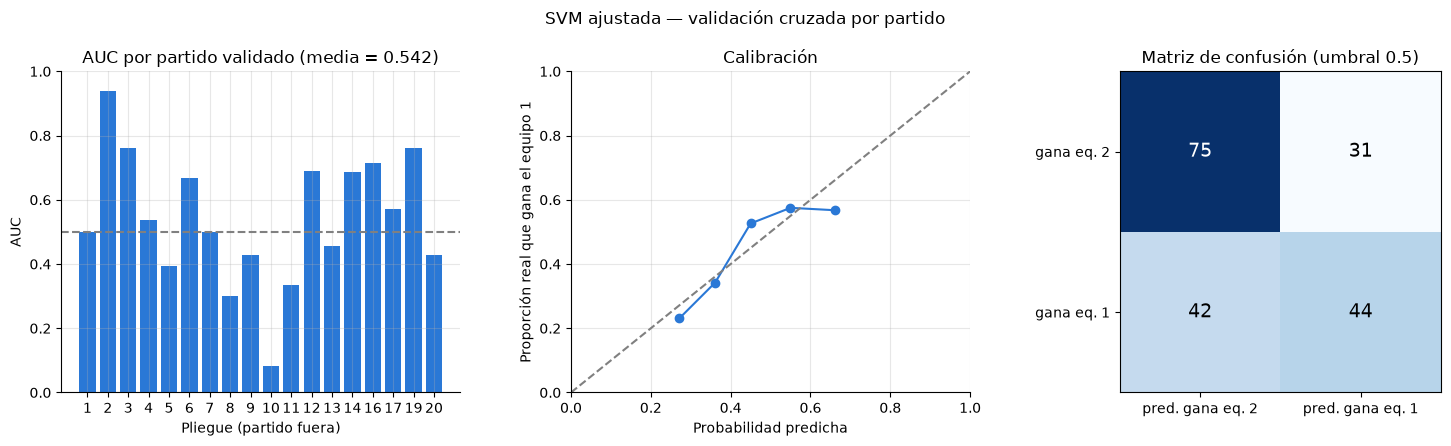

In [55]:
mejores_svm = mejores_params(res_svm)
print('Mejores hiperparámetros de la SVM:', mejores_svm)

svm = clone(svm_base).set_params(**mejores_svm)
p_svm = predecir_cv_svm(svm, X_train, y_train, grupos_train, pliegues)
resultados_cv['svm'] = mod.metricas(y_train, p_svm, pliegues)

n_sv = mod.con_imputacion(svm).fit(X_train, y_train)[-1][-1].n_support_.sum()
print(f'Vectores de soporte: {n_sv} de {len(X_train)} puntos ({n_sv / len(X_train):.0%})')

# Variante: LASSO elige las variables DENTRO de cada pliegue (así la selección no ve el partido que se valida)
from sklearn.feature_selection import SelectFromModel
svm_lasso = make_pipeline(
    StandardScaler(),
    SelectFromModel(LogisticRegression(l1_ratio=1, solver='liblinear', C=mejor_C.loc['LASSO', 'C']), threshold=1e-5),
    SVC(),
).set_params(**mejores_svm)
p_svm_lasso = predecir_cv_svm(svm_lasso, X_train, y_train, grupos_train, pliegues)
resultados_cv['svm_lasso'] = mod.metricas(y_train, p_svm_lasso, pliegues)

print(classification_report(y_train, (p_svm >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_svm, 'SVM ajustada — validación cruzada por partido', pliegues)

In [56]:
comparacion = pd.DataFrame(resultados_cv).T
display(comparacion.round(3))

# Probabilidades de validación por partido, guardadas para el ensamblaje de la 2.7
p_cv = {'lasso': p_lasso, 'ridge': p_ridge, 'rf': p_rf, 'svm': p_svm, 'svm_lasso': p_svm_lasso}

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


### ¿Los modelos se distinguen entre sí?

Todos los modelos quedaron en un *log-loss* muy parecido. Antes de elegir, se estima la incertidumbre de esa diferencia con dos revisiones:
- **Qué tanto se mueve la probabilidad.** Si un modelo casi siempre predice cerca de la proporción base, su *log-loss* mejora poco al naive.
- **Bootstrap por partido.** Se remuestrean partidos completos (con reemplazo) y en cada remuestreo se recalcula el *log-loss* de cada modelo con las mismas predicciones de validación. Así la incertidumbre respeta que los puntos de un partido van juntos (D35). Solo se remuestrean las predicciones; no se reentrenan los modelos. Este intervalo es condicional a las predicciones de validación obtenidas y no corrige el optimismo por selección de hiperparámetros.

Estos mismos remuestreos (`ids`, `ll_boot`) se reutilizan en la 2.6 y la 2.7 para que todas las diferencias de validación sean comparables. La 2.8 hace su propio bootstrap, sobre los partidos del test.

In [57]:
# Cuánto se mueve la probabilidad de cada modelo y qué tan plana es la búsqueda de hiperparámetros
modelos_cv = {'naive': p_naive, 'lasso': p_lasso, 'ridge': p_ridge, 'rf': p_rf, 'svm': p_svm, 'svm_lasso': p_svm_lasso}
display(pd.DataFrame({k: p.describe()[['min', '25%', '50%', '75%', 'max']] for k, p in modelos_cv.items()}).T.round(3))
display(pd.DataFrame({'RF (grid + random)': res_rf['log_loss'].describe()[['min', '50%', 'max']],
                      'SVM (grid)': res_svm['log_loss'].describe()[['min', '50%', 'max']]}).T.round(3))

,min,25%,50%,75%,max
naive,0.432,0.439,0.448,0.454,0.465
lasso,0.180,0.336,0.502,0.589,0.884
ridge,0.218,0.371,0.477,0.577,0.879
rf,0.151,0.340,0.445,0.548,0.714
svm,0.226,0.335,0.446,0.567,0.776
svm_lasso,0.204,0.334,0.465,0.565,0.861


,min,50%,max
RF (grid + random),0.651,0.657,0.676
SVM (grid),0.652,0.676,0.696


Las probabilidades de RF van de 0,151 a 0,714, con mediana 0,445; las de SVM, de 0,226 a 0,776, con mediana 0,446. LASSO se mueve entre 0,180 y 0,884 (mediana 0,502), mientras que el naive queda entre 0,432 y 0,465 (mediana 0,448). RF y SVM sí mueven la probabilidad, aunque sus medianas permanecen cerca de la proporción base; LASSO se aleja más. En las curvas de calibración de cinco grupos, RF sigue aproximadamente la diagonal con algunas desviaciones; SVM queda por debajo en las probabilidades bajas, por encima en la zona media y vuelve a quedar por debajo en el grupo más alto. La curva es descriptiva: con pocos partidos, no conviene sobreinterpretar esas diferencias.

In [58]:
# Bootstrap por partido de las diferencias de log-loss (menor es mejor; una diferencia negativa favorece al primero)
rng = np.random.default_rng(datos.SEMILLA)
yv = y_train.values
def ll_filas(p):
    p = np.clip(p.values, 1e-15, 1 - 1e-15)
    return -(yv * np.log(p) + (1 - yv) * np.log(1 - p))

g = grupos_train.values
suma_ll = pd.DataFrame({k: pd.Series(ll_filas(p)).groupby(g).sum() for k, p in modelos_cv.items()})
n_pts = pd.Series(1, index=range(len(g))).groupby(g).sum()

B = 2000
ids = rng.integers(0, len(suma_ll), size=(B, len(suma_ll)))
ll_boot = pd.DataFrame(suma_ll.values[ids].sum(axis=1) / n_pts.values[ids].sum(axis=1)[:, None], columns=suma_ll.columns)

pares = [('lasso', 'naive'), ('ridge', 'naive'), ('rf', 'naive'), ('svm', 'naive'), ('svm_lasso', 'naive'),
         ('rf', 'lasso'), ('svm', 'lasso'), ('svm_lasso', 'lasso'), ('rf', 'svm'), ('rf', 'svm_lasso'), ('svm_lasso', 'svm')]
filas = []
for a, b in pares:
    d = ll_boot[a] - ll_boot[b]
    filas.append({'diferencia de log-loss': f'{a} − {b}', 'media': d.mean(), 'IC95 inf': d.quantile(0.025),
                  'IC95 sup': d.quantile(0.975), '% remuestreos a favor del primero': (d < 0).mean() * 100})
pd.DataFrame(filas).set_index('diferencia de log-loss').round(3)

,media,IC95 inf,IC95 sup,% remuestreos a favor del primero
diferencia de log-loss,,,,
lasso − naive,-0.046,-0.091,0.000,97.40
ridge − naive,-0.041,-0.080,0.001,97.15
rf − naive,-0.046,-0.087,-0.005,98.30
svm − naive,-0.044,-0.090,-0.000,97.50
svm_lasso − naive,-0.045,-0.091,0.002,97.25
rf − lasso,0.000,-0.020,0.021,49.50
svm − lasso,0.002,-0.015,0.019,39.45
svm_lasso − lasso,0.001,-0.013,0.013,40.05
rf − svm,-0.002,-0.021,0.018,57.85


**Resultado**

El Random Forest de fábrica muestra una brecha marcada entre entrenamiento (log-loss = 0,189) y validación por partido (0,679), señal de sobreajuste; su accuracy OOB de 0,604 no sustituye la evaluación agrupada. Al limitarlo (`max_depth=8`, `min_samples_leaf=14`, `max_features='sqrt'`, 300 árboles), alcanza log-loss = 0,651, Brier = 0,229, AUC = 0,601 y accuracy = 0,646, la más alta de la comparación. La búsqueda del Random Forest fue plana: las ocho mejores combinaciones de la grilla y de la búsqueda aleatoria quedan entre 0,651 y 0,655, y los mejores resultados de la grilla y la aleatoria difieren en 0,002.

En la SVM, la búsqueda mejora la base de log-loss = 0,654 a 0,652 (`rbf`, `C=1`, `gamma=0,01`). Aunque se esperaba que un `C` bajo pudiera convenir, el mejor fue 1. El 86 % de los puntos (166 de 192) son vectores de soporte, consistente con clases mezcladas y una separación débil. La SVM con selección LASSO dentro de cada pliegue obtiene log-loss = 0,652 y AUC = 0,586.

Las importancias del Random Forest son relativamente parejas: van de 0,130 (`dif_suma_nivel_padel`) a 0,066 en la décima posición; un reparto uniforme entre 19 variables sería 0,053. Seis de las diez primeras también fueron seleccionadas por LASSO (nivel, % quieto, desviación de profundidad, IMC, diferencia de profundidad entre compañeros y velocidad p90), una coincidencia descriptiva sobre las variables con más señal.

En log-loss, RF (0,651), LASSO (0,651) y SVM-LASSO (0,652) son prácticamente iguales; Ridge queda cerca (0,655). En el bootstrap por partido, RF − LASSO tiene diferencia media = 0,000 (IC95 % [−0,020; 0,021]; cerca del 49 % de los remuestreos favorecen a RF), y SVM-LASSO − LASSO = 0,001 (IC95 % [−0,013; 0,013]; cerca del 40 % favorecen a SVM-LASSO); ambos intervalos incluyen cero. Estos porcentajes cambian unas décimas entre ejecuciones (las diferencias están pegadas a cero y pequeñas variaciones numéricas de las predicciones las cambian de signo), por eso se dan redondeados. Frente al naive, las diferencias favorecen puntualmente a todos: LASSO = −0,046 (IC95 % [−0,091; 0,000]; 97,40 % de remuestreos a favor), Ridge = −0,041 [−0,080; 0,001] (97,15 %), RF = −0,046 [−0,087; −0,005] (98,30 %), SVM = −0,044 [−0,090; −0,000] (97,50 %) y SVM-LASSO = −0,045 [−0,091; 0,002] (97,25 %). A la precisión de la tabla, los IC95 % de RF y SVM excluyen cero; el límite superior de SVM se redondea a −0,000, por lo que es un resultado limítrofe. Los IC95 % de LASSO, Ridge y SVM-LASSO incluyen cero.

Para la 2.7, RF, LASSO y SVM-LASSO son candidatos, aunque sus errores son muy parecidos y no cabe esperar una mejora grande del ensamblaje. Para la fase 4, LASSO o Ridge siguen siendo alternativas más simples. Estas conclusiones son condicionales a las predicciones OOF: el bootstrap no reentrena ni corrige el optimismo de elegir hiperparámetros con los mismos pliegues, y el test permanece reservado para la 2.8.

## 2.6 Bagging y boosting

**Objetivo:** probar los ensambles de árboles vistos en clase (bagging, AdaBoost y Gradient Boosting, con XGBoost si está instalado) y una red neuronal pequeña como comparación, con la misma validación por partido y el mismo criterio de elección (log-loss) de la 2.5.

**Ejecución:** esta sección continúa la 2.5: usa `buscar`, `mejores_params`, `p_cv` y `ll_boot`. Después de reiniciar el kernel hay que ejecutar todo lo anterior en orden (**Run All**). La primera celda verifica los requisitos. XGBoost es opcional (D44): si no está instalado (`pip install xgboost`), la sección sigue sin ese modelo.

**Decisiones**
- **D42 (Bagging):** árboles de decisión con `n_estimators=200` fijo (más árboles solo estabilizan el promedio, como se vio en la 2.5); se ajustan la profundidad, el tamaño mínimo de hoja y la fracción de puntos por árbol (`max_samples`). Bagging mira todas las variables en cada pregunta; esa es su diferencia con el Random Forest. El error *out-of-bag* se reporta pero no se usa para elegir: los árboles que no vieron un punto sí vieron a otros puntos de su mismo partido. La importancia de variables es el promedio de la importancia de cada árbol.
- **D43 (Boosting):** árboles poco profundos y *learning rate* bajo, porque con 192 puntos de train el boosting sobreajusta con facilidad. AdaBoost: grilla completa (profundidad 1–2, 25 a 200 árboles, *learning rate* de 0,01 a 1). Gradient Boosting: búsqueda aleatoria de 40 combinaciones (profundidad 1–3, *learning rate* de 0,01 a 0,1, `subsample` y hoja mínima). Se elige por log-loss de la validación por partido (D38, D39), con la misma limitación de la 2.5: sin validación anidada, la métrica del mejor modelo es algo optimista.
- **D44 (XGBoost opcional):** se incluye solo si `xgboost` está instalado, con la misma búsqueda aleatoria de Gradient Boosting más `colsample_bytree`, `min_child_weight` y `reg_lambda`. Si no está, se omite; el resto de la sección y la 2.7 siguen sin él.
- **D45 (red neuronal):** `MLPClassifier` pequeña (1 o 2 capas de 4 a 16 neuronas), con escalado dentro de cada pliegue y penalización `alpha`. No se usa `early_stopping`: separaría una validación al azar que mezcla puntos del mismo partido.
- Los modelos nuevos se guardan en `resultados_cv` y en `p_cv` (para el ensamblaje de la 2.7) y se agregan a `ll_boot` con los mismos remuestreos de la 2.5.
- El test (los 5 partidos) sigue sin tocarse hasta la 2.8.

In [59]:
# Verificación de requisitos de la 2.6 (vienen de la 2.5) y de XGBoost (opcional, D44)
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.exceptions import ConvergenceWarning
import warnings

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

requisitos_26 = ['buscar', 'mejores_params', 'p_cv', 'll_boot', 'ids', 'll_filas', 'g', 'n_pts', 'resultados_cv', 'imp_rf', 'seleccion_lasso']
faltan = [n for n in requisitos_26 if n not in globals()]
if faltan:
    raise RuntimeError(f'Faltan objetos de la 2.5: {", ".join(faltan)}. Reinicie el kernel y ejecute el notebook en orden (Run All).')
print('XGBoost:', 'instalado' if XGBClassifier is not None else 'no instalado: se omite (D44)')

XGBoost: no instalado: se omite (D44)


### Bagging
Bagging entrena muchos árboles, cada uno con una muestra bootstrap de los puntos, y promedia sus probabilidades. Es el Random Forest sin el sorteo de variables: cada pregunta mira las 19. Los hiperparámetros:

- **`max_depth` y `min_samples_leaf`:** qué tan memorizador es cada árbol. Con árboles completos las probabilidades salen extremas y eso castiga el log-loss (2.5).
- **`max_samples`:** qué fracción de los puntos ve cada árbol. Menos puntos por árbol, árboles más distintos entre sí.
- **`n_estimators`:** fijo en 200 (D42).

**Sobre el OOB:** igual que en el Random Forest, el error *out-of-bag* puede salir optimista porque los árboles que no vieron un punto sí vieron a otros puntos de su partido. La medida honesta es la validación por partido; abajo se muestran las dos.

In [60]:
# Bagging "de fábrica" (como en 06_Bagging): 200 árboles completos
bag_arbol = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=datos.SEMILLA), n_estimators=200,
                              random_state=datos.SEMILLA, n_jobs=-1)
p_bag_base = mod.predecir_cv(bag_arbol, X_train, y_train, pliegues)
resultados_cv['bagging_base'] = mod.metricas(y_train, p_bag_base, pliegues)

# Chequeo de sobreajuste: train vs validación por partido, y el OOB
bag_diag = mod.con_imputacion(clone(bag_arbol).set_params(oob_score=True)).fit(X_train, y_train)
p_tr = bag_diag.predict_proba(X_train)[:, 1]
print(f"log-loss  train: {log_loss(y_train, p_tr):.3f} | validación por partido: {resultados_cv['bagging_base']['log_loss']:.3f}")
print(f"accuracy  OOB:   {bag_diag[-1].oob_score_:.3f} | validación por partido: {resultados_cv['bagging_base']['accuracy']:.3f}")
pd.DataFrame(resultados_cv).T.round(3)

log-loss  train: 0.195 | validación por partido: 0.704
accuracy  OOB:   0.599 | validación por partido: 0.604


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


In [61]:
# Grid Search: 3 x 3 x 3 = 27 combinaciones
grid_bag = ParameterGrid({
    'estimator__max_depth': [2, 4, None],
    'estimator__min_samples_leaf': [5, 10, 20],
    'max_samples': [0.5, 0.8, 1.0],
})
res_bag = buscar(bag_arbol, grid_bag, 'Grid Search Bagging')
display(res_bag.head(8).round(3))

mejores_bag = mejores_params(res_bag)
print('Mejores hiperparámetros del Bagging:', mejores_bag)

Grid Search Bagging: 27 combinaciones en 57 s


,estimator__max_depth,estimator__min_samples_leaf,max_samples,log_loss,Brier,AUC
0,4.0,10,0.8,0.652,0.231,0.567
1,NaN,10,0.8,0.652,0.231,0.564
2,4.0,20,0.5,0.654,0.231,0.610
3,2.0,20,0.5,0.654,0.231,0.610
4,NaN,20,0.5,0.654,0.231,0.610
5,2.0,10,0.8,0.655,0.232,0.577
6,2.0,20,0.8,0.657,0.232,0.586
7,4.0,10,0.5,0.657,0.232,0.571


Mejores hiperparámetros del Bagging: {'estimator__max_depth': 4, 'estimator__min_samples_leaf': 10, 'max_samples': 0.8}


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


               precision    recall  f1-score   support

gana equipo 2       0.67      0.71      0.69       106
gana equipo 1       0.61      0.57      0.59        86

     accuracy                           0.65       192
    macro avg       0.64      0.64      0.64       192
 weighted avg       0.64      0.65      0.64       192



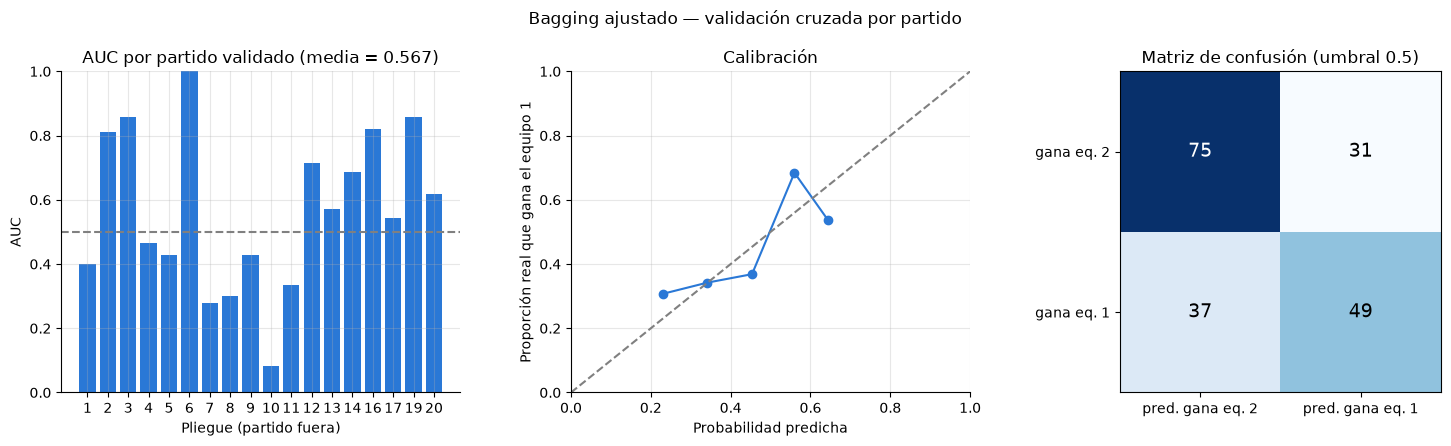

,importancia_Bagging,importancia_RF,la_eligio_LASSO
dif_suma_nivel_padel,0.139,0.130,True
dif_absdif_prof_media_m,0.113,0.083,True
dif_suma_pct_quieto,0.099,0.091,True
dif_suma_prof_sd_m,0.093,0.088,True
dif_razon_vel_p90,0.092,0.068,False
dif_suma_imc,0.087,0.088,True
dif_suma_rafagas_por_min,0.084,0.080,False
dif_suma_estatura_cm,0.058,0.085,False
dif_suma_area_m2,0.057,0.067,False
dif_suma_vel_p90,0.051,0.066,True


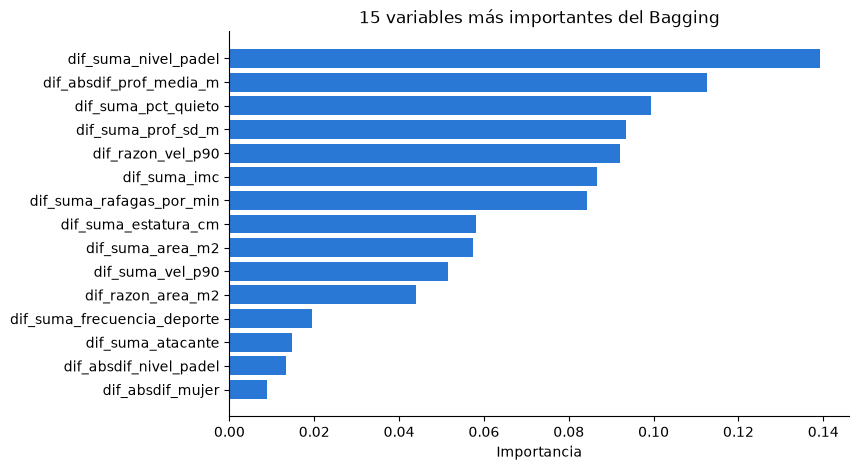

In [62]:
bagging = clone(bag_arbol).set_params(**mejores_bag)
p_bagging = mod.predecir_cv(bagging, X_train, y_train, pliegues)
resultados_cv['bagging'] = mod.metricas(y_train, p_bagging, pliegues)
display(pd.DataFrame(resultados_cv).T.round(3))

print(classification_report(y_train, (p_bagging >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_bagging, 'Bagging ajustado — validación cruzada por partido', pliegues)

# Importancia de variables: promedio de la importancia de cada árbol (D42), junto a la del Random Forest y a LASSO
bag_final = mod.con_imputacion(bagging).fit(X_train, y_train)[-1]
imp_bag = pd.Series(np.mean([a.feature_importances_ for a in bag_final.estimators_], axis=0),
                    index=var.VARIABLES_MODELO).sort_values(ascending=False)
tabla_imp_bag = imp_bag.head(10).round(3).to_frame('importancia_Bagging')
tabla_imp_bag['importancia_RF'] = imp_rf.reindex(tabla_imp_bag.index).round(3)
tabla_imp_bag['la_eligio_LASSO'] = tabla_imp_bag.index.isin(seleccion_lasso.index)
display(tabla_imp_bag)

top = imp_bag.head(15).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color='#2a78d6')
plt.xlabel('Importancia'); plt.title('15 variables más importantes del Bagging')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

### AdaBoost
AdaBoost entrena árboles muy pequeños uno tras otro; cada uno da más peso a los puntos que los anteriores clasificaron mal. A diferencia del bagging, los árboles no son independientes, y por eso un modelo demasiado grande memoriza el ruido. Los hiperparámetros:

- **`estimator__max_depth`:** profundidad de cada árbol; 1 es un solo corte (*stump*).
- **`n_estimators` y `learning_rate`:** se compensan entre sí. Un *learning rate* bajo obliga a usar más árboles, pero cada paso corrige menos el error y el modelo se parece más a la proporción base.

In [63]:
# AdaBoost "de fábrica": 50 stumps, learning_rate = 1
ada_base = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=datos.SEMILLA),
                              n_estimators=50, learning_rate=1.0, random_state=datos.SEMILLA)
p_ada_base = mod.predecir_cv(ada_base, X_train, y_train, pliegues)
resultados_cv['adaboost_base'] = mod.metricas(y_train, p_ada_base, pliegues)
pd.DataFrame(resultados_cv).T.round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


Grid Search AdaBoost: 40 combinaciones en 126 s


,estimator__max_depth,learning_rate,n_estimators,log_loss,Brier,AUC
0,1,0.5,50,0.662,0.234,0.517
1,2,0.5,50,0.662,0.235,0.473
2,2,0.5,100,0.663,0.235,0.480
3,2,1.0,50,0.666,0.237,0.524
4,2,0.5,25,0.666,0.236,0.460
5,1,0.5,100,0.668,0.238,0.477
6,2,0.5,200,0.669,0.238,0.501
7,1,0.1,200,0.669,0.237,0.506


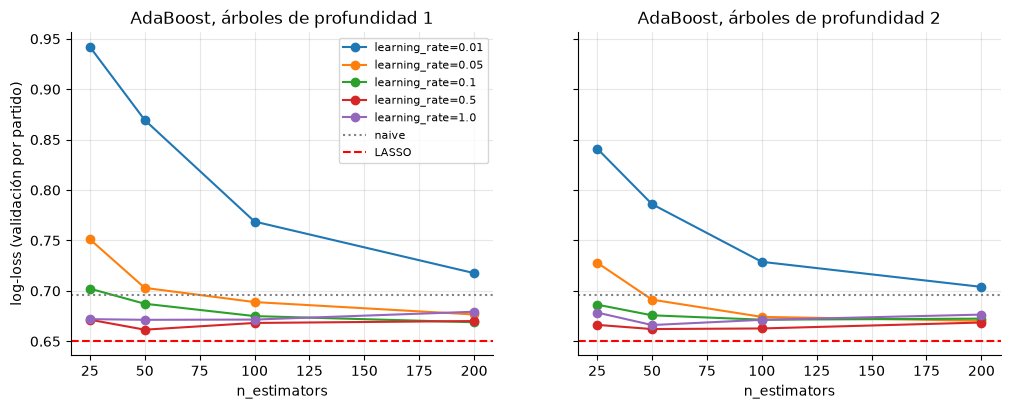

In [64]:
# Grid Search: 2 x 4 x 5 = 40 combinaciones
grid_ada = ParameterGrid({
    'estimator__max_depth': [1, 2],
    'n_estimators': [25, 50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
})
res_ada = buscar(ada_base, grid_ada, 'Grid Search AdaBoost')
display(res_ada.head(8).round(3))

# Log-loss contra n_estimators, una línea por learning rate
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for a, (prof, d) in zip(ax, res_ada.groupby('estimator__max_depth')):
    for lr, dd in d.groupby('learning_rate'):
        dd = dd.sort_values('n_estimators')
        a.plot(dd['n_estimators'], dd['log_loss'], 'o-', label=f'learning_rate={lr}')
    a.axhline(resultados_cv['naive']['log_loss'], color='gray', linestyle=':', label='naive')
    a.axhline(resultados_cv['lasso']['log_loss'], color='red', linestyle='--', label='LASSO')
    a.set(title=f'AdaBoost, árboles de profundidad {prof}', xlabel='n_estimators')
    a.grid(alpha=0.3); a.spines[['top', 'right']].set_visible(False)
ax[0].set_ylabel('log-loss (validación por partido)'); ax[0].legend(fontsize=8)
plt.show()

Mejores hiperparámetros de AdaBoost: {'estimator__max_depth': 1, 'learning_rate': 0.5, 'n_estimators': 50}


               precision    recall  f1-score   support

gana equipo 2       0.67      0.68      0.68       106
gana equipo 1       0.60      0.59      0.60        86

     accuracy                           0.64       192
    macro avg       0.64      0.64      0.64       192
 weighted avg       0.64      0.64      0.64       192



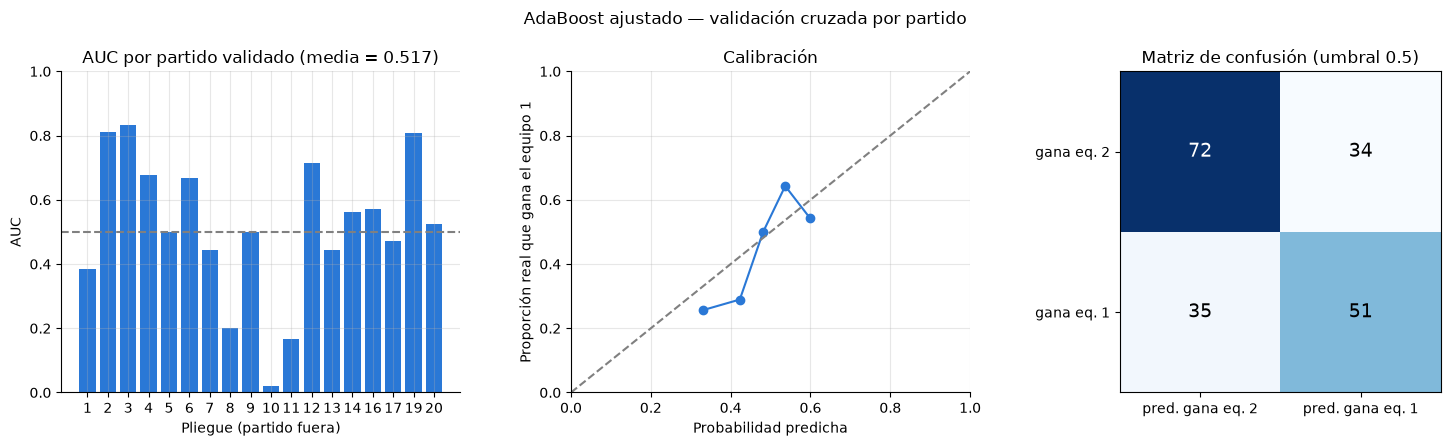

In [65]:
mejores_ada = mejores_params(res_ada)
print('Mejores hiperparámetros de AdaBoost:', mejores_ada)

adaboost = clone(ada_base).set_params(**mejores_ada)
p_ada = mod.predecir_cv(adaboost, X_train, y_train, pliegues)
resultados_cv['adaboost'] = mod.metricas(y_train, p_ada, pliegues)

print(classification_report(y_train, (p_ada >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_ada, 'AdaBoost ajustado — validación cruzada por partido', pliegues)

### Gradient Boosting y XGBoost
Gradient Boosting también suma árboles pequeños en secuencia, pero cada árbol nuevo ajusta el error (el gradiente) que dejó la suma anterior. XGBoost es una implementación más rápida con regularización adicional. Los hiperparámetros:

- **`learning_rate` y `n_estimators`:** igual que en AdaBoost; con 192 puntos conviene un *learning rate* bajo.
- **`max_depth`:** de 1 a 3; árboles más profundos memorizan.
- **`subsample`:** fracción de puntos que ve cada árbol (si es menor que 1, añade aleatoriedad que ayuda a no sobreajustar).
- **`min_samples_leaf`** (Gradient Boosting) y **`colsample_bytree`, `min_child_weight`, `reg_lambda`** (XGBoost): frenan hojas pequeñas y coeficientes grandes.

In [66]:
# Gradient Boosting "de fábrica" (100 árboles de profundidad 3, learning_rate = 0,1)
gb_base = GradientBoostingClassifier(random_state=datos.SEMILLA)
p_gb_base = mod.predecir_cv(gb_base, X_train, y_train, pliegues)
resultados_cv['gb_base'] = mod.metricas(y_train, p_gb_base, pliegues)

gb_diag = mod.con_imputacion(clone(gb_base)).fit(X_train, y_train)
print(f"log-loss  train: {log_loss(y_train, gb_diag.predict_proba(X_train)[:, 1]):.3f} | validación por partido: {resultados_cv['gb_base']['log_loss']:.3f}")
pd.DataFrame(resultados_cv).T.round(3)

log-loss  train: 0.156 | validación por partido: 0.821


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


In [67]:
# Random Search: 40 combinaciones al azar (de 432 posibles)
dist_gb = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [1, 2, 3],
    'subsample': [0.5, 0.7, 1.0],
    'min_samples_leaf': [5, 10, 20],
}
res_gb = buscar(gb_base, ParameterSampler(dist_gb, n_iter=40, random_state=datos.SEMILLA), 'Random Search Gradient Boosting')
display(res_gb.head(8).round(3))

mejores_gb = mejores_params(res_gb)
print('Mejores hiperparámetros del Gradient Boosting:', mejores_gb)

Random Search Gradient Boosting: 40 combinaciones en 125 s


,subsample,n_estimators,min_samples_leaf,max_depth,learning_rate,log_loss,Brier,AUC
0,1.0,200,20,1,0.05,0.630,0.219,0.602
1,0.7,100,20,1,0.05,0.637,0.223,0.607
2,0.5,300,20,1,0.03,0.640,0.225,0.586
3,1.0,100,10,1,0.05,0.646,0.227,0.577
4,1.0,300,20,2,0.01,0.647,0.228,0.537
5,0.5,50,10,1,0.10,0.649,0.229,0.575
6,0.5,50,20,1,0.10,0.650,0.229,0.571
7,1.0,300,10,1,0.03,0.651,0.228,0.554


Mejores hiperparámetros del Gradient Boosting: {'subsample': 1.0, 'n_estimators': 200, 'min_samples_leaf': 20, 'max_depth': 1, 'learning_rate': 0.05}


               precision    recall  f1-score   support

gana equipo 2       0.70      0.71      0.70       106
gana equipo 1       0.64      0.63      0.63        86

     accuracy                           0.67       192
    macro avg       0.67      0.67      0.67       192
 weighted avg       0.67      0.67      0.67       192



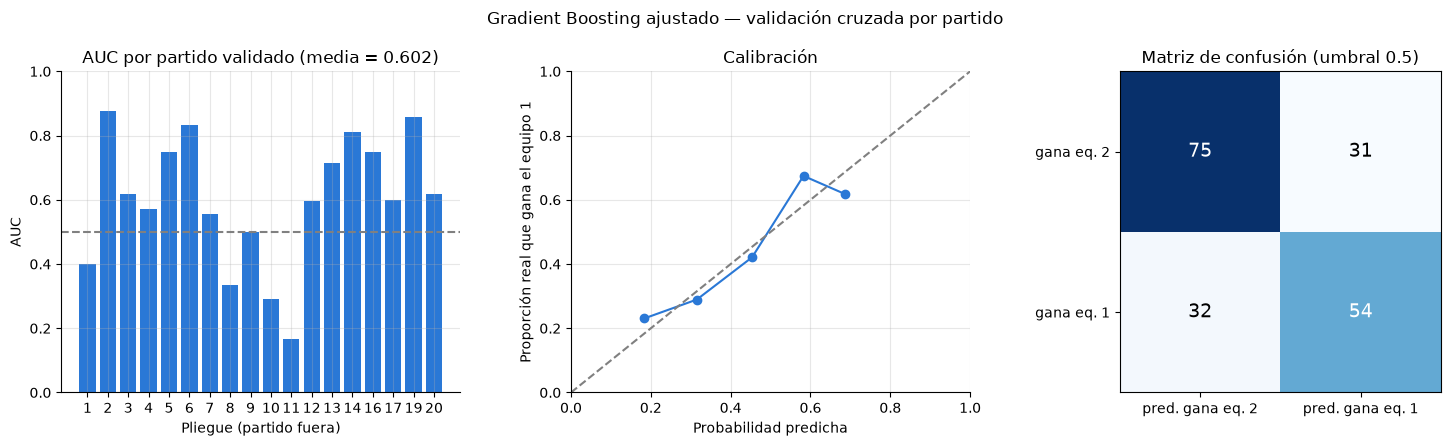

,importancia_GB,la_eligio_LASSO
dif_suma_nivel_padel,0.248,True
dif_razon_vel_p90,0.191,False
dif_suma_rafagas_por_min,0.117,False
dif_suma_prof_sd_m,0.103,True
dif_absdif_prof_media_m,0.102,True
dif_suma_pct_quieto,0.080,True
dif_suma_imc,0.077,True
dif_suma_area_m2,0.066,False
dif_absdif_atacante,0.009,False
dif_razon_area_m2,0.007,False


In [68]:
gboost = clone(gb_base).set_params(**mejores_gb)
p_gb = mod.predecir_cv(gboost, X_train, y_train, pliegues)
resultados_cv['gradient_boosting'] = mod.metricas(y_train, p_gb, pliegues)

print(classification_report(y_train, (p_gb >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_gb, 'Gradient Boosting ajustado — validación cruzada por partido', pliegues)

gb_final = mod.con_imputacion(gboost).fit(X_train, y_train)[-1]
imp_gb = pd.Series(gb_final.feature_importances_, index=var.VARIABLES_MODELO).sort_values(ascending=False)
tabla_imp_gb = imp_gb.head(10).round(3).to_frame('importancia_GB')
tabla_imp_gb['la_eligio_LASSO'] = tabla_imp_gb.index.isin(seleccion_lasso.index)
display(tabla_imp_gb)

In [69]:
# XGBoost (opcional, D44): se omite si no está instalado
if XGBClassifier is None:
    print('XGBoost no está instalado: se omite. Para incluirlo, ejecute `pip install xgboost` y vuelva a correr desde la primera celda de la 2.6.')
else:
    xgb_base = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, eval_metric='logloss',
                             random_state=datos.SEMILLA, n_jobs=-1, verbosity=0)
    p_xgb_base = mod.predecir_cv(xgb_base, X_train, y_train, pliegues)
    resultados_cv['xgboost_base'] = mod.metricas(y_train, p_xgb_base, pliegues)

    dist_xgb = {
        'n_estimators': [50, 100, 200, 300],
        'learning_rate': [0.01, 0.03, 0.05, 0.1],
        'max_depth': [1, 2, 3],
        'subsample': [0.5, 0.7, 1.0],
        'colsample_bytree': [0.5, 0.8, 1.0],
        'min_child_weight': [1, 3, 5],
        'reg_lambda': [1, 5, 10],
    }
    res_xgb = buscar(xgb_base, ParameterSampler(dist_xgb, n_iter=40, random_state=datos.SEMILLA), 'Random Search XGBoost')
    display(res_xgb.head(8).round(3))

    mejores_xgb = mejores_params(res_xgb)
    print('Mejores hiperparámetros de XGBoost:', mejores_xgb)
    xgboost_ = clone(xgb_base).set_params(**mejores_xgb)
    p_xgb = mod.predecir_cv(xgboost_, X_train, y_train, pliegues)
    resultados_cv['xgboost'] = mod.metricas(y_train, p_xgb, pliegues)
    print(classification_report(y_train, (p_xgb >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
    mod.graficar_evaluacion(y_train, p_xgb, 'XGBoost ajustado — validación cruzada por partido', pliegues)
pd.DataFrame(resultados_cv).T.round(3)

XGBoost no está instalado: se omite. Para incluirlo, ejecute `pip install xgboost` y vuelva a correr desde la primera celda de la 2.6.


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


### Red neuronal (opcional)
Una red pequeña como comparación con los modelos de árboles. Con 192 puntos y 19 variables, una red grande memoriza; por eso se limita a una o dos capas de pocas neuronas y se compara la penalización `alpha` (mayor `alpha`, pesos más pequeños y frontera más suave). Las variables se estandarizan dentro de cada pliegue.

Grid Search red neuronal: 16 combinaciones en 166 s


,mlpclassifier__alpha,mlpclassifier__hidden_layer_sizes,log_loss,Brier,AUC
0,10.0,"(16,)",0.656,0.231,0.570
1,10.0,"(8,)",0.660,0.234,0.535
2,10.0,"(8, 4)",0.663,0.236,0.609
3,10.0,"(4,)",0.672,0.238,0.607
4,1.0,"(8,)",0.746,0.238,0.620
5,1.0,"(4,)",0.876,0.303,0.438
6,1.0,"(16,)",0.935,0.276,0.543
7,1.0,"(8, 4)",1.007,0.294,0.512


Mejores hiperparámetros de la red neuronal: {'mlpclassifier__alpha': 10.0, 'mlpclassifier__hidden_layer_sizes': (16,)}


               precision    recall  f1-score   support

gana equipo 2       0.66      0.70      0.68       106
gana equipo 1       0.60      0.56      0.58        86

     accuracy                           0.64       192
    macro avg       0.63      0.63      0.63       192
 weighted avg       0.63      0.64      0.63       192



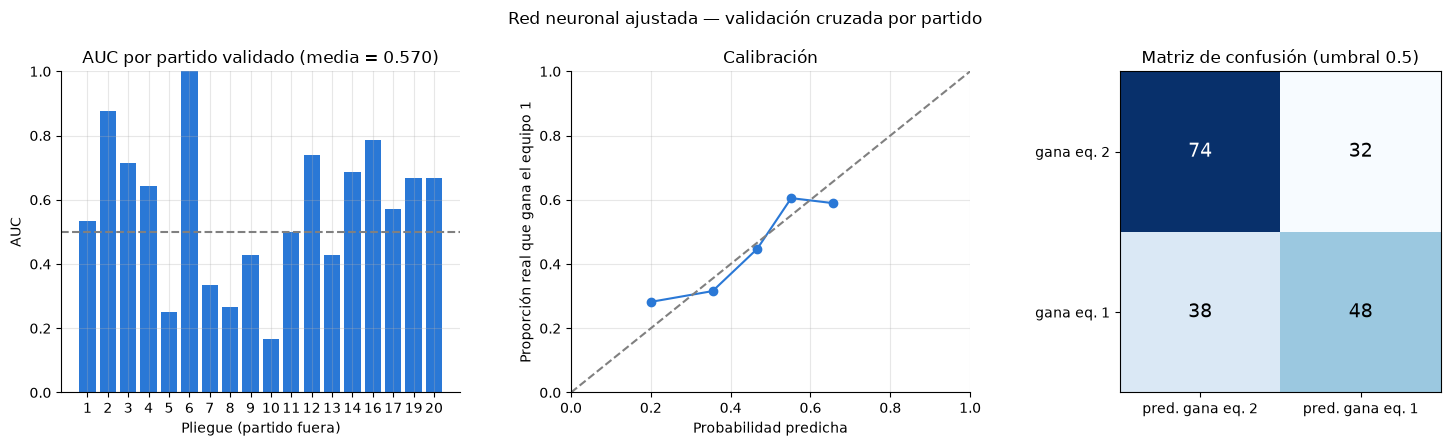

In [70]:
mlp_base = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(8,), alpha=1e-4, max_iter=2000,
                                                         random_state=datos.SEMILLA))
grid_mlp = ParameterGrid({
    'mlpclassifier__hidden_layer_sizes': [(4,), (8,), (16,), (8, 4)],
    'mlpclassifier__alpha': [0.01, 0.1, 1.0, 10.0],
})
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    p_mlp_base = mod.predecir_cv(mlp_base, X_train, y_train, pliegues)
    resultados_cv['mlp_base'] = mod.metricas(y_train, p_mlp_base, pliegues)
    res_mlp = buscar(mlp_base, grid_mlp, 'Grid Search red neuronal')
display(res_mlp.head(8).round(3))

mejores_mlp = mejores_params(res_mlp)
print('Mejores hiperparámetros de la red neuronal:', mejores_mlp)
mlp = clone(mlp_base).set_params(**mejores_mlp)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    p_mlp = mod.predecir_cv(mlp, X_train, y_train, pliegues)
resultados_cv['mlp'] = mod.metricas(y_train, p_mlp, pliegues)
print(classification_report(y_train, (p_mlp >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_train, p_mlp, 'Red neuronal ajustada — validación cruzada por partido', pliegues)

### Comparación de la 2.6 y bootstrap por partido
Los modelos nuevos se agregan a `p_cv` (para el ensamblaje de la 2.7) y a `ll_boot` con **los mismos remuestreos de partidos de la 2.5**, de modo que las diferencias son comparables con las de esa sección. Como allí, el intervalo es condicional a las predicciones de validación obtenidas y no corrige el optimismo de elegir hiperparámetros con los mismos pliegues.

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
logistica,0.485,0.245,18.0,0.715,0.249,0.589,0.527
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
ridge,0.569,0.221,18.0,0.655,0.231,0.620,0.578
arbol,0.481,0.079,18.0,0.707,0.255,0.526,0.584
rf_base,0.489,0.274,18.0,0.679,0.242,0.599,0.503
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
svm_base,0.481,0.194,18.0,0.654,0.231,0.609,0.534
svm,0.542,0.205,18.0,0.652,0.230,0.620,0.547
svm_lasso,0.586,0.211,18.0,0.652,0.229,0.604,0.537


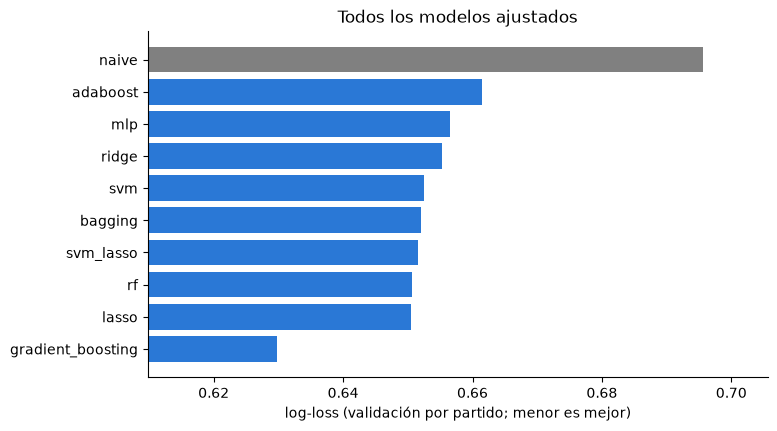

,media,IC95 inf,IC95 sup,% remuestreos a favor del primero
diferencia de log-loss,,,,
bagging − naive,-0.044,-0.099,0.009,94.55
bagging − lasso,0.002,-0.021,0.026,44.35
bagging − rf,0.001,-0.013,0.015,42.90
adaboost − naive,-0.035,-0.069,-0.002,98.00
adaboost − lasso,0.011,-0.015,0.037,18.60
adaboost − rf,0.011,-0.008,0.030,12.75
gradient_boosting − naive,-0.067,-0.128,-0.006,98.45
gradient_boosting − lasso,-0.021,-0.056,0.015,87.05
gradient_boosting − rf,-0.021,-0.051,0.008,91.35


In [71]:
p_nuevos = {'bagging': p_bagging, 'adaboost': p_ada, 'gradient_boosting': p_gb, 'mlp': p_mlp}
if XGBClassifier is not None:
    p_nuevos['xgboost'] = p_xgb
p_cv.update(p_nuevos)

comparacion = pd.DataFrame(resultados_cv).T
display(comparacion.round(3))

# Log-loss de cada modelo ajustado contra el naive y LASSO
orden = [m for m in ['naive', 'lasso', 'ridge', 'rf', 'svm', 'svm_lasso', *p_nuevos] if m in comparacion.index]
ll = comparacion.loc[orden, 'log_loss'].sort_values()
plt.figure(figsize=(8, 4.5))
plt.barh(ll.index, ll.values, color=['gray' if m == 'naive' else '#2a78d6' for m in ll.index])
plt.xlim(ll.min() - 0.02, ll.max() + 0.01)
plt.xlabel('log-loss (validación por partido; menor es mejor)'); plt.title('Todos los modelos ajustados')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

# Bootstrap por partido: se agregan los modelos nuevos a ll_boot con los mismos remuestreos (ids) de la 2.5
for k, p in p_nuevos.items():
    s = pd.Series(ll_filas(p)).groupby(g).sum()
    ll_boot[k] = s.values[ids].sum(axis=1) / n_pts.values[ids].sum(axis=1)

filas_26 = []
for a in p_nuevos:
    for b in ('naive', 'lasso', 'rf'):
        d = ll_boot[a] - ll_boot[b]
        filas_26.append({'diferencia de log-loss': f'{a} − {b}', 'media': d.mean(), 'IC95 inf': d.quantile(0.025),
                         'IC95 sup': d.quantile(0.975), '% remuestreos a favor del primero': (d < 0).mean() * 100})
pd.DataFrame(filas_26).set_index('diferencia de log-loss').round(3)

**Resultado**

**¿Superan a LASSO?** Solo el Gradient Boosting baja de LASSO (0,651): log-loss = 0,630, Brier = 0,219, AUC = 0,602 y accuracy = 0,672, los mejores valores de toda la fase 2 hasta aquí. El Bagging (0,652) queda empatado con LASSO y el Random Forest, y la red neuronal (0,656) y AdaBoost (0,662) quedan por encima. XGBoost no se evaluó porque no está instalado (D44).

En el bootstrap por partido (los mismos 2.000 remuestreos de la 2.5):
- **Gradient Boosting − LASSO** = −0,021 (IC95 % [−0,056; 0,015]; cerca del 87 % de los remuestreos lo favorecen) y **Gradient Boosting − RF** = −0,021 ([−0,051; 0,008]; cerca del 91 %). Los dos intervalos incluyen cero: la ventaja es consistente en la mayoría de los remuestreos, pero no alcanza a separarse del empate.
- **Frente al naive**, los IC95 % de Gradient Boosting (−0,067 [−0,128; −0,006]) y AdaBoost (−0,035 [−0,069; −0,002]) excluyen cero; los de Bagging (−0,044 [−0,099; 0,009]) y la red neuronal (−0,040 [−0,091; 0,010]) lo incluyen.
- Bagging, AdaBoost y la red neuronal no mejoran a LASSO ni al RF: sus diferencias medias son positivas o nulas (de 0,001 a 0,011).

Además, el Gradient Boosting es el ganador de 40 combinaciones al azar elegido con los mismos pliegues con los que se reporta (D39), así que su 0,630 es algo optimista; la prueba sin ese sesgo es el test de la 2.8.

**¿Los modelos «de fábrica» sobreajustan?** El Bagging y el Gradient Boosting, sí: casi aciertan el train y fallan en el partido que no vieron.

| Modelo de fábrica | log-loss train | log-loss validación por partido |
|---|---|---|
| Bagging (200 árboles completos) | 0,195 | 0,704 |
| Gradient Boosting (100 árboles de profundidad 3) | 0,156 | 0,821 |

En AdaBoost y en la red no se calculó el log-loss de train; en validación, la red de fábrica (`alpha` = 0,0001) da 1,314 contra 0,656 con la penalización más fuerte, y AdaBoost de fábrica (0,671) queda cerca del ajustado (0,662). El Bagging y el Gradient Boosting de fábrica quedan peor que el naive (0,696). La accuracy OOB del Bagging (0,599) quedó parecida a la de la validación por partido (0,604): en este caso el OOB no salió optimista. El ajuste lleva siempre a la versión más restringida: Gradient Boosting con árboles de un solo corte (`max_depth=1`, en 7 de sus 8 mejores combinaciones), hoja mínima de 20 y *learning rate* de 0,05; AdaBoost con *stumps*; Bagging con profundidad 4 y hoja mínima de 10; y la red con la penalización más fuerte (`alpha` = 10). Con `max_depth=1` el Gradient Boosting es una suma de efectos de una variable cada uno, sin interacciones. En dos casos el mejor valor queda en el borde de la grilla (`min_samples_leaf=20` del Gradient Boosting y `alpha=10` de la red), así que valores aún más restrictivos no se probaron. En AdaBoost, con *learning rate* 0,01 y pocos árboles, el log-loss queda por encima del naive (hasta 0,94).

**¿Coinciden las variables importantes?** `dif_suma_nivel_padel` es la primera en el Bagging (0,139), el Gradient Boosting (0,248), el Random Forest y LASSO. Las 10 primeras del Bagging son las mismas 10 primeras del Random Forest (en otro orden), y 6 de ellas las eligió LASSO. El Gradient Boosting concentra la importancia en 8 variables (de 0,248 a 0,066; la novena ya baja a 0,009): 5 de ellas las eligió LASSO (nivel, desviación de profundidad, diferencia de profundidad entre compañeros, % quieto e IMC), y aparecen arriba dos de movimiento que LASSO descartó, `dif_razon_vel_p90` (0,191) y `dif_suma_rafagas_por_min` (0,117). Las de estilo atacante/defensivo quedan casi en cero (`dif_absdif_atacante` = 0,009).

**Calibración.** La curva del Gradient Boosting sigue la diagonal en los grupos bajos y medios. En el grupo más alto predice cerca de 0,69 y el equipo 1 gana cerca del 0,62. Con cinco grupos y pocos partidos, es descriptiva.

**Candidatos para la 2.7.** Gradient Boosting (el menor log-loss), LASSO y Random Forest. Bagging y SVM-LASSO están empatados con estos dos últimos y aportan poca diversidad. AdaBoost y la red neuronal no mejoran a ninguno. La elección final se hace con el ensamblaje (2.7) y el test (2.8).


## 2.7 Ensamblaje de modelos

**Objetivo:** combinar los mejores modelos de la 2.3 a la 2.6 en uno solo y ver si el ensamblaje predice mejor que cada uno por separado, con la misma validación por partido y el mismo criterio (log-loss).

**Ejecución:** esta sección continúa la 2.6: usa `p_cv`, `resultados_cv`, `ll_boot` y los remuestreos `ids`. Después de reiniciar el kernel hay que ejecutar todo lo anterior en orden (**Run All**). La primera celda vuelve a leer `src/modelo.py` (por si el kernel tenía una versión anterior en memoria) y verifica los requisitos.

**Decisiones**
- **D46 (modelos y forma de combinarlos):**
  - **Modelos:** Gradient Boosting, LASSO y Random Forest, los candidatos de la 2.6. Son de tres familias distintas (boosting, lineal y bagging de árboles).
  - **Promedio simple** (*soft voting*): la probabilidad del ensamblaje es el promedio de las tres probabilidades.
  - **Voto ponderado** (parte 5 del 06): el peso de cada modelo es proporcional a $1 - \text{log-loss}$, el equivalente del $1 - \text{error}$ del profesor con la métrica de esta fase (D38). En cada pliegue los pesos se calculan solo con los otros 19 partidos, nunca con el que se valida.
  - **Voto mayoritario** (parte 4 del 06): gana la clase que predicen al menos 2 de los 3 modelos. Solo se reporta accuracy y F1, porque da 0 o 1 y no una probabilidad, y la fase 4 necesita probabilidades.
  - **Sin reentrenar:** la probabilidad de validación de cada modelo en un partido ya viene de ese modelo entrenado sin ese partido, así que promediarlas es exactamente la predicción del ensamblaje entrenado en el mismo pliegue (`mod.ensamblar_cv`).
  - Los ensamblajes se agregan a `resultados_cv`, `p_cv` y `ll_boot` (los mismos remuestreos de la 2.5). Como los tres modelos se eligieron con estos mismos pliegues, la métrica del ensamblaje hereda el optimismo de D39.
- **D47 (mejorar el ensamblaje):** como el promedio no superó al Gradient Boosting, se prueban otras formas de combinar. En todas, lo que se aprende (pesos o coeficientes) sale en cada pliegue solo de las predicciones de los otros 19 partidos:
  - **pesos óptimos:** los pesos (no negativos, que suman 1) que minimizan el log-loss, con los 3 modelos y con los 9 modelos ajustados de la 2.4 a la 2.6 (`mod.pesos_optimos`);
  - **selección codiciosa** (Caruana et al., 2004) sobre los 9: se agrega, con reemplazo, el modelo que más baja el log-loss;
  - **stacking:** una regresión logística sobre los logits de los 3 modelos;
  - **promedio de logits** de los 3, **promedio simple de los 9** y **recalibración** del promedio de los 3 con una logística.

  Se queda la variante con menor log-loss en validación. Limitación: las predicciones de los otros partidos vienen de modelos que sí vieron el partido validado, así que este segundo nivel puede ser algo optimista.
- El test (los 5 partidos) sigue sin tocarse hasta la 2.8.

### ¿Por qué un ensamblaje podría mejorar? (como en el 06)
Un ensamblaje funciona cuando sus modelos son **precisos** (mejores que el naive) e **independientes** (se equivocan en puntos distintos): al promediar, los errores de uno se compensan con los aciertos de los otros. Si los tres modelos predicen casi lo mismo, el promedio no gana nada. Por eso primero se mide qué tan distintas son sus predicciones.

In [72]:
# Verificación de requisitos de la 2.7 (vienen de la 2.5 y la 2.6)
from sklearn.metrics import accuracy_score, f1_score
import importlib
from src import modelo as mod
mod = importlib.reload(mod)  # vuelve a leer src/modelo.py por si el kernel lo cargó antes de que tuviera las funciones de la 2.7-2.8
faltan_mod = [f for f in ('ensamblar_cv', 'pesos_log_loss', 'pesos_optimos', 'Ensamblaje') if not hasattr(mod, f)]
if faltan_mod:
    raise RuntimeError(f'src/modelo.py no tiene {", ".join(faltan_mod)}: actualice el repositorio (git pull) y reinicie el kernel.')

requisitos_27 = ['p_cv', 'resultados_cv', 'll_boot', 'ids', 'll_filas', 'g', 'n_pts', 'p_naive', 'X_train', 'y_train', 'pliegues']
faltan = [n for n in requisitos_27 if n not in globals()]
if faltan:
    raise RuntimeError(f'Faltan objetos de la 2.5–2.6: {", ".join(faltan)}. Reinicie el kernel y ejecute el notebook en orden (Run All).')

MODELOS_ENSAMBLE = ['gradient_boosting', 'lasso', 'rf']  # D46
assert set(MODELOS_ENSAMBLE) <= set(p_cv), 'p_cv debe traer gradient_boosting, lasso y rf de la 2.4–2.6.'
P_ens = pd.DataFrame({k: p_cv[k] for k in MODELOS_ENSAMBLE})
print(f'Requisitos de la 2.7 completos: {len(P_ens)} puntos de validación x {P_ens.shape[1]} modelos.')

Requisitos de la 2.7 completos: 192 puntos de validación x 3 modelos.


### ¿Los tres modelos son distintos?
Dos medidas, ambas con las probabilidades de validación por partido:
- **Correlación de las probabilidades:** cerca de 1 quiere decir que los modelos ordenan los puntos casi igual.
- **Correlación de los errores** ($y - p$) y **acuerdo en la clase predicha** con umbral 0,5: si se equivocan en los mismos puntos, promediar no compensa nada.

In [73]:
errores_ens = P_ens.rsub(y_train, axis=0)   # y - p de cada modelo
clases_ens = (P_ens >= 0.5).astype(int)
acuerdo = pd.DataFrame({a: {b: (clases_ens[a] == clases_ens[b]).mean() for b in MODELOS_ENSAMBLE} for a in MODELOS_ENSAMBLE})

print('Correlación de las probabilidades:')
display(P_ens.corr().round(3))
print('Correlación de los errores (y − p):')
display(errores_ens.corr().round(3))
print('Proporción de puntos en que predicen la misma clase (umbral 0,5):')
display(acuerdo.round(3))
print(f'Puntos en que los tres predicen la misma clase: {(clases_ens.nunique(axis=1) == 1).mean():.1%}')

Correlación de las probabilidades:


,gradient_boosting,lasso,rf
gradient_boosting,1.000,0.718,0.885
lasso,0.718,1.000,0.804
rf,0.885,0.804,1.000


Correlación de los errores (y − p):


,gradient_boosting,lasso,rf
gradient_boosting,1.000,0.963,0.980
lasso,0.963,1.000,0.983
rf,0.980,0.983,1.000


Proporción de puntos en que predicen la misma clase (umbral 0,5):


,gradient_boosting,lasso,rf
gradient_boosting,1.000,0.766,0.849
lasso,0.766,1.000,0.802
rf,0.849,0.802,1.000


Puntos en que los tres predicen la misma clase: 70.8%


### Promedio simple (*soft voting*)
Como el ensamblaje manual de la parte 2 del 06, pero promediando probabilidades en lugar de predicciones de regresión:

$$\hat p_{\text{ens}} = \frac{1}{3}\left(\hat p_{\text{GB}} + \hat p_{\text{LASSO}} + \hat p_{\text{RF}}\right)$$

In [74]:
p_ens_prom, _ = mod.ensamblar_cv(P_ens, y_train, pliegues)
resultados_cv['ens_promedio'] = mod.metricas(y_train, p_ens_prom, pliegues)
pd.DataFrame(resultados_cv).T.loc[['naive', *MODELOS_ENSAMBLE, 'ens_promedio']].round(3)

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
gradient_boosting,0.602,0.204,18.0,0.630,0.219,0.672,0.632
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
ens_promedio,0.604,0.224,18.0,0.634,0.222,0.661,0.633


### Voto ponderado
Como en la parte 5 del 06, cada modelo pesa según su desempeño. El profesor usa $\alpha_j \propto 1 - \epsilon_j$ (error de clasificación *out-of-bag*); aquí, $\alpha_j \propto 1 - \text{log-loss}_j$, calculado en cada pliegue con las predicciones de validación de los **otros 19 partidos**:

$$\hat p_{\text{ens}} = \sum_j \alpha_j\, \hat p_j, \qquad \alpha_j = \frac{1 - \text{log-loss}_j}{\sum_{k} \left(1 - \text{log-loss}_k\right)}$$

In [75]:
p_ens_pond, pesos_pliegue = mod.ensamblar_cv(P_ens, y_train, pliegues, pesos='log_loss')
resultados_cv['ens_ponderado'] = mod.metricas(y_train, p_ens_pond, pliegues)

print('Pesos de cada modelo en los 20 pliegues:')
display(pesos_pliegue.describe().loc[['min', 'mean', 'max']].round(4))
print(f'Diferencia máxima entre la probabilidad ponderada y la del promedio simple: {(p_ens_pond - p_ens_prom).abs().max():.4f}')
pd.DataFrame(resultados_cv).T.loc[['naive', *MODELOS_ENSAMBLE, 'ens_promedio', 'ens_ponderado']].round(3)

Pesos de cada modelo en los 20 pliegues:

,gradient_boosting,lasso,rf
min,0.3427,0.3240,0.3241
mean,0.3463,0.3269,0.3268
max,0.3516,0.3295,0.3287


Diferencia máxima entre la probabilidad ponderada y la del promedio simple: 0.0051


,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
gradient_boosting,0.602,0.204,18.0,0.630,0.219,0.672,0.632
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
ens_promedio,0.604,0.224,18.0,0.634,0.222,0.661,0.633
ens_ponderado,0.601,0.223,18.0,0.634,0.222,0.667,0.636


### Voto mayoritario (como en la parte 4 del 06)
Cada modelo vota por una clase con umbral 0,5 y gana la que tiene al menos 2 de los 3 votos. Solo se compara en accuracy y F1: el resultado es 0 o 1, así que no tiene log-loss ni Brier útiles.

In [76]:
voto_mayoritario = (clases_ens.sum(axis=1) >= 2).astype(int)
clasif = pd.DataFrame({k: {'accuracy': accuracy_score(y_train, clases_ens[k]), 'F1': f1_score(y_train, clases_ens[k])} for k in MODELOS_ENSAMBLE}).T
clasif.loc['voto_mayoritario'] = [accuracy_score(y_train, voto_mayoritario), f1_score(y_train, voto_mayoritario)]
clasif.loc['ens_promedio'] = [accuracy_score(y_train, p_ens_prom >= 0.5), f1_score(y_train, p_ens_prom >= 0.5)]
display(clasif.round(3))
print(classification_report(y_train, voto_mayoritario, target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))

,accuracy,F1
gradient_boosting,0.672,0.632
lasso,0.604,0.582
rf,0.646,0.585
voto_mayoritario,0.661,0.629
ens_promedio,0.661,0.633


               precision    recall  f1-score   support

gana equipo 2       0.70      0.68      0.69       106
gana equipo 1       0.62      0.64      0.63        86

     accuracy                           0.66       192
    macro avg       0.66      0.66      0.66       192
 weighted avg       0.66      0.66      0.66       192



### ¿Se puede mejorar el ensamblaje? (D47)
El promedio no superó al Gradient Boosting. Hay dos explicaciones posibles: que los pesos iguales le den demasiado peso a los modelos más débiles, o que los modelos se equivoquen en los mismos puntos y no haya nada que compensar. Para distinguirlas se prueban formas de combinar que **aprenden** los pesos y se mira si los errores de **los 9 modelos** ajustados también se parecen.

In [77]:
from scipy.special import expit, logit

MODELOS_9 = ['lasso', 'ridge', 'rf', 'svm', 'svm_lasso', 'bagging', 'adaboost', 'gradient_boosting', 'mlp']
P_9 = pd.DataFrame({k: p_cv[k] for k in MODELOS_9})
EPS = 1e-6

print('Correlación de los errores (y − p) de los 9 modelos ajustados:')
corr_9 = P_9.rsub(y_train, axis=0).corr()
display(corr_9.round(2))
print(f'Rango fuera de la diagonal: {corr_9.values[~np.eye(9, dtype=bool)].min():.2f} a {corr_9.values[~np.eye(9, dtype=bool)].max():.2f}')


def segundo_nivel(ajustar, P):
    # Aplica en cada pliegue una combinación aprendida solo con los otros 19 partidos
    out = pd.Series(np.nan, index=P.index, name='p_equipo_1')
    for train, val in pliegues:
        out.iloc[val] = ajustar(P.iloc[train], y_train.iloc[train], P.iloc[val])
    return out


def caruana(Pt, yt, rondas=25):
    # Selección codiciosa con reemplazo: en cada ronda entra el modelo que más baja el log-loss del promedio
    elegidos, suma = [], np.zeros(len(Pt))
    for r in range(1, rondas + 1):
        mejor = min(Pt.columns, key=lambda c: log_loss(yt, np.clip((suma + Pt[c].values) / r, EPS, 1 - EPS)))
        elegidos.append(mejor)
        suma += Pt[mejor].values
    return pd.Series(elegidos).value_counts(normalize=True)


a_logit = lambda P: logit(P.clip(EPS, 1 - EPS))
variantes = {
    'gradient_boosting (solo)': p_cv['gradient_boosting'],
    'promedio 3 (ens_promedio)': p_ens_prom,
    'promedio de logits 3': pd.Series(expit(a_logit(P_ens).mean(axis=1)), index=P_ens.index),
    'promedio 9': P_9.mean(axis=1),
    'pesos óptimos 3': mod.ensamblar_cv(P_ens, y_train, pliegues, pesos='optimos')[0],
    'pesos óptimos 9': mod.ensamblar_cv(P_9, y_train, pliegues, pesos='optimos')[0],
    'selección codiciosa 9': segundo_nivel(lambda Pt, yt, Pv: Pv[(w := caruana(Pt, yt)).index].values @ w.values, P_9),
    'stacking 3 (logística)': segundo_nivel(lambda Pt, yt, Pv: LogisticRegression().fit(a_logit(Pt), yt).predict_proba(a_logit(Pv))[:, 1], P_ens),
    'promedio 3 + recalibración': segundo_nivel(lambda Pt, yt, Pv: LogisticRegression(C=1e6).fit(a_logit(Pt).mean(axis=1).to_frame(), yt)
                                                .predict_proba(a_logit(Pv).mean(axis=1).to_frame())[:, 1], P_ens),
}
tabla_mejora = pd.DataFrame({k: mod.metricas(y_train, p, pliegues) for k, p in variantes.items()}).T
tabla_mejora[['log_loss', 'Brier', 'AUC', 'accuracy']].sort_values('log_loss').round(4)

Correlación de los errores (y − p) de los 9 modelos ajustados:


,lasso,ridge,rf,svm,svm_lasso,bagging,adaboost,gradient_boosting,mlp
lasso,1.00,0.99,0.98,0.99,0.99,0.98,0.98,0.96,0.99
ridge,0.99,1.00,0.99,1.00,1.00,0.98,0.98,0.97,0.99
rf,0.98,0.99,1.00,0.99,0.98,1.00,0.99,0.98,0.98
svm,0.99,1.00,0.99,1.00,1.00,0.98,0.98,0.97,0.99
svm_lasso,0.99,1.00,0.98,1.00,1.00,0.98,0.98,0.97,0.99
bagging,0.98,0.98,1.00,0.98,0.98,1.00,0.98,0.99,0.98
adaboost,0.98,0.98,0.99,0.98,0.98,0.98,1.00,0.98,0.97
gradient_boosting,0.96,0.97,0.98,0.97,0.97,0.99,0.98,1.00,0.96
mlp,0.99,0.99,0.98,0.99,0.99,0.98,0.97,0.96,1.00


Rango fuera de la diagonal: 0.96 a 1.00


,log_loss,Brier,AUC,accuracy
gradient_boosting (solo),0.6298,0.2190,0.6025,0.6719
pesos óptimos 3,0.6310,0.2197,0.6165,0.6667
selección codiciosa 9,0.6311,0.2198,0.6165,0.6719
promedio 3 (ens_promedio),0.6337,0.2216,0.6038,0.6615
promedio de logits 3,0.6343,0.2219,0.6038,0.6615
pesos óptimos 9,0.6369,0.2217,0.5940,0.6667
promedio 9,0.6423,0.2254,0.5821,0.6615
stacking 3 (logística),0.6424,0.2242,0.5830,0.6719
promedio 3 + recalibración,0.6444,0.2261,0.6038,0.6719


In [78]:
# Las dos mejores formas de combinar, ajustadas con los 20 partidos de train: ¿qué pesos eligen?
print('Pesos óptimos (3 modelos):', mod.pesos_optimos(y_train, P_ens).round(3).to_dict())
print('Selección codiciosa (9 modelos):', caruana(P_9, y_train).round(3).to_dict())

# La variante elegida (D47) entra a la comparación como ens_optimo
p_ens_opt, pesos_opt_pliegue = mod.ensamblar_cv(P_ens, y_train, pliegues, pesos='optimos')
resultados_cv['ens_optimo'] = mod.metricas(y_train, p_ens_opt, pliegues)
print('\nPeso de cada modelo en los 20 pliegues (pesos óptimos):')
display(pesos_opt_pliegue.describe().loc[['min', 'mean', 'max']].round(3))

Pesos óptimos (3 modelos): {'gradient_boosting': 0.745, 'lasso': 0.255, 'rf': 0.0}


Selección codiciosa (9 modelos): {'gradient_boosting': 0.76, 'lasso': 0.24}



Peso de cada modelo en los 20 pliegues (pesos óptimos):


,gradient_boosting,lasso,rf
min,0.680,0.131,0.0
mean,0.746,0.254,0.0
max,0.869,0.320,0.0


### Comparación de la 2.7 y bootstrap por partido
Los ensamblajes se comparan con cada uno de sus modelos y con el naive, con **los mismos remuestreos de partidos de la 2.5**. Como antes, el intervalo es condicional a las predicciones de validación obtenidas y no corrige el optimismo de haber elegido los modelos y sus hiperparámetros con los mismos pliegues.

,AUC,AUC_sd,pliegues_con_AUC,log_loss,Brier,accuracy,F1
naive,0.500,0.000,18.0,0.696,0.251,0.552,0.000
gradient_boosting,0.602,0.204,18.0,0.630,0.219,0.672,0.632
lasso,0.579,0.225,18.0,0.651,0.229,0.604,0.582
rf,0.601,0.254,18.0,0.651,0.229,0.646,0.585
ens_promedio,0.604,0.224,18.0,0.634,0.222,0.661,0.633
ens_ponderado,0.601,0.223,18.0,0.634,0.222,0.667,0.636
ens_optimo,0.616,0.190,18.0,0.631,0.220,0.667,0.632


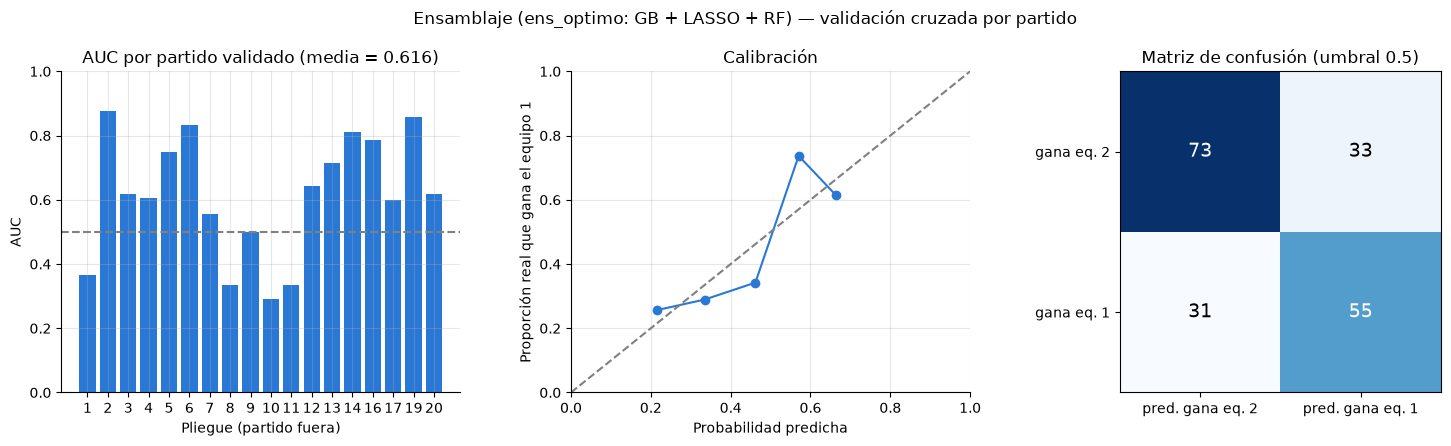

,media,IC95 inf,IC95 sup,% remuestreos a favor del primero
diferencia de log-loss,,,,
ens_promedio − naive,-0.063,-0.107,-0.019,99.80
ens_promedio − gradient_boosting,0.004,-0.019,0.027,35.60
ens_promedio − lasso,-0.017,-0.034,-0.001,98.10
ens_promedio − rf,-0.017,-0.028,-0.007,99.95
ens_ponderado − naive,-0.063,-0.108,-0.019,99.80
ens_ponderado − gradient_boosting,0.004,-0.019,0.027,36.00
ens_ponderado − lasso,-0.017,-0.034,-0.001,98.05
ens_ponderado − rf,-0.017,-0.028,-0.007,99.95
ens_optimo − naive,-0.066,-0.120,-0.011,99.15


In [79]:
p_ensambles = {'ens_promedio': p_ens_prom, 'ens_ponderado': p_ens_pond, 'ens_optimo': p_ens_opt}
p_cv.update(p_ensambles)

comparacion = pd.DataFrame(resultados_cv).T
orden = ['naive', *MODELOS_ENSAMBLE, *p_ensambles]
display(comparacion.loc[orden].round(3))

mejor_ens = min(p_ensambles, key=lambda k: resultados_cv[k]['log_loss'])
mod.graficar_evaluacion(y_train, p_ensambles[mejor_ens], f'Ensamblaje ({mejor_ens}: GB + LASSO + RF) — validación cruzada por partido', pliegues)

# Bootstrap por partido con los mismos remuestreos (ids) de la 2.5
for k, p in p_ensambles.items():
    s = pd.Series(ll_filas(p)).groupby(g).sum()
    ll_boot[k] = s.values[ids].sum(axis=1) / n_pts.values[ids].sum(axis=1)


def fila_boot(a, b):
    d = ll_boot[a] - ll_boot[b]
    return {'diferencia de log-loss': f'{a} − {b}', 'media': d.mean(), 'IC95 inf': d.quantile(0.025),
            'IC95 sup': d.quantile(0.975), '% remuestreos a favor del primero': (d < 0).mean() * 100}


pares_27 = [(a, b) for a in p_ensambles for b in ('naive', *MODELOS_ENSAMBLE)]
pares_27 += [('ens_ponderado', 'ens_promedio'), ('ens_optimo', 'ens_promedio')]
pd.DataFrame([fila_boot(a, b) for a, b in pares_27]).set_index('diferencia de log-loss').round(3)

In [80]:
# Para la 2.8: pesos óptimos con los 20 partidos de train (se aplican a los modelos reentrenados con todo el train, D47)
pesos_ensamble = mod.pesos_optimos(y_train, P_ens)
pesos_ensamble.round(4).to_frame('peso')

,peso
gradient_boosting,0.745
lasso,0.255
rf,0.000


**Resultado**

**Los tres modelos se equivocan en los mismos puntos.** Sus probabilidades se parecen sin ser iguales: correlación de 0,72 (Gradient Boosting con LASSO) a 0,89 (Gradient Boosting con RF), y predicen la misma clase en el 70,8 % de los puntos. Sus errores ($y - p$), en cambio, tienen correlación de 0,96 a 0,98. Lo mismo pasa con los 9 modelos ajustados: entre 0,96 y 1,00. Según el 06, en esa situación un ensamblaje casi no tiene errores que compensar.

**Promedio simple, voto ponderado y voto mayoritario.**
- Con pesos ∝ 1 − log-loss, cada modelo pesa casi un tercio (Gradient Boosting 0,346; LASSO y RF 0,327). El promedio y el ponderado quedan iguales: log-loss = 0,634 y Brier = 0,222.
- Los dos mejoran a LASSO y a RF (−0,017 en log-loss; IC95 % [−0,034; −0,001] y [−0,028; −0,007]), pero no al Gradient Boosting solo (+0,004 [−0,019; 0,027]).
- El voto mayoritario acierta el 66,1 % (F1 = 0,629), por debajo del Gradient Boosting solo (0,672).

**¿Se puede mejorar? (D47)** Se probaron siete formas más de combinar, todas aprendidas solo con los otros 19 partidos de cada pliegue:

| Variante | log-loss | Brier | AUC |
|---|---|---|---|
| Gradient Boosting solo (referencia) | 0,630 | 0,219 | 0,602 |
| **Pesos óptimos con 3 modelos (`ens_optimo`)** | **0,631** | **0,220** | **0,616** |
| Selección codiciosa con 9 modelos | 0,631 | 0,220 | 0,616 |
| Promedio simple de 3 (`ens_promedio`) | 0,634 | 0,222 | 0,604 |
| Promedio de logits de 3 | 0,634 | 0,222 | 0,604 |
| Pesos óptimos con 9 modelos | 0,637 | 0,222 | 0,594 |
| Promedio simple de 9 | 0,642 | 0,225 | 0,582 |
| Stacking con logística | 0,642 | 0,224 | 0,583 |
| Promedio de 3 + recalibración | 0,644 | 0,226 | 0,604 |

- **Aprender los pesos mejora el ensamblaje** de 0,634 a 0,631 y da el AUC más alto de la fase 2 (0,616).
- **Las dos mejores llegan a lo mismo por caminos distintos:** ~75 % Gradient Boosting y ~25 % LASSO, con RF en 0. Los pesos óptimos dan 0,745/0,255 con todo el train (entre 0,68 y 0,87 para el Gradient Boosting según el pliegue), y la selección codiciosa, 0,76/0,24. LASSO, el modelo menos parecido al Gradient Boosting, es el único que aporta.
- **Combinaciones más flexibles salen peor:** el stacking, los 9 modelos y la recalibración se ajustan con muy pocos puntos.
- **Contra los demás modelos (bootstrap):**
  - `ens_optimo` − naive = −0,066 (IC95 % [−0,120; −0,011]).
  - `ens_optimo` − LASSO = −0,020 [−0,046; 0,007] y `ens_optimo` − RF = −0,020 [−0,042; 0,003].
  - `ens_optimo` − Gradient Boosting = +0,001 [−0,009; 0,012]: un empate, con un intervalo más estrecho que el del promedio simple.

**Conclusión.** Ningún ensamblaje supera al Gradient Boosting solo en validación. Con errores tan correlacionados, la combinación no tiene de dónde mejorar. Lo que sí logra `ens_optimo` es empatar con el Gradient Boosting sin depender por completo de un solo modelo elegido en una búsqueda aleatoria, con AUC más alto. Por eso es el modelo final que se fija para la 2.8 (D48). Estos números siguen siendo de validación y heredan el optimismo de D39 y del segundo nivel (D47).


## 2.8 Comparación final en test, bootstrap y modelo para la fase 4

**Objetivo:** medir, una sola vez y con los 5 partidos que ningún modelo vio, qué tan bien predicen los candidatos; cuantificar la incertidumbre de esa medida y dejar entrenado el modelo que usará la fase 4.

**Ejecución:** esta sección continúa la 2.7: usa `pesos_ensamble`, los modelos ajustados (`lasso`, `rf`, `gboost`) y el test de la 2.1. Después de reiniciar el kernel hay que ejecutar todo en orden (**Run All**). La primera celda vuelve a leer `src/modelo.py` y verifica los requisitos.

**Decisiones**
- **D48 (regla fija antes del test):** el modelo final se eligió con la validación por partido y se escribe aquí antes de mirar el test: el **ensamblaje con pesos óptimos** (`ens_optimo`, 2.7). En validación empata con el Gradient Boosting y depende menos de una sola búsqueda aleatoria. El test se reporta para todos los candidatos (naive, LASSO, RF, Gradient Boosting, promedio simple y `ens_optimo`), pero **no se usa para elegir**. Con 52 puntos, elegir por el test lo convertiría en otra validación y dejaría al proyecto sin una medida independiente.
- **Cómo se entrena cada candidato:** con los 20 partidos de train completos (192 puntos), con los hiperparámetros de la 2.4 a la 2.6 y los pesos de la 2.7. La imputación usa la mediana del train (D33).
- **Métricas en test (D36):** log-loss, Brier, accuracy y F1 con los 52 puntos juntos. El AUC se reporta de dos formas: con todos los puntos juntos y como media dentro de cada partido.
- **Bootstrap en test:** se remuestrean los 5 partidos completos (2.000 veces, semilla 2026), igual que en la 2.5. Con solo 5 partidos hay pocas combinaciones distintas, así que los intervalos son una aproximación gruesa.
- **Simetría (pedida por la fase 4):** al intercambiar las parejas, todas las `dif_` cambian de signo. Se mide p(equipo 1 gana con `X`) + p(equipo 1 gana con `−X`), que debería dar ≈ 1.
- **D49 (modelo para la fase 4):** después de reportar el test, `ens_optimo` se reentrena con los 25 partidos (244 puntos), con los mismos hiperparámetros y pesos. La métrica que se reporta sigue siendo la del test.
- **Referencia:** `06_Bagging.ipynb` (bootstrap) y métricas del `03_Regresion_Logistica.ipynb`.

In [81]:
# Regla fija (D48): se escribe antes de mirar el test
import importlib
from src import modelo as mod
mod = importlib.reload(mod)  # vuelve a leer src/modelo.py por si el kernel lo cargó antes de que tuviera las funciones de la 2.7-2.8
faltan_mod = [f for f in ('ensamblar_cv', 'pesos_log_loss', 'pesos_optimos', 'Ensamblaje') if not hasattr(mod, f)]
if faltan_mod:
    raise RuntimeError(f'src/modelo.py no tiene {", ".join(faltan_mod)}: actualice el repositorio (git pull) y reinicie el kernel.')

MODELO_FINAL = 'ens_optimo'
requisitos_28 = ['pesos_ensamble', 'lasso', 'rf', 'gboost', 'naive', 'X_test', 'y_test', 'X', 'y', 'grupos', 'idx_test']
faltan = [n for n in requisitos_28 if n not in globals()]
if faltan:
    raise RuntimeError(f'Faltan objetos de la 2.1–2.7: {", ".join(faltan)}. Reinicie el kernel y ejecute el notebook en orden (Run All).')

grupos_test = grupos.iloc[idx_test]
print(f'Modelo final elegido en validación (D48): {MODELO_FINAL} | pesos: {pesos_ensamble.round(3).to_dict()}')
print(f'Test: {len(X_test)} puntos de {grupos_test.nunique()} partidos {sorted(grupos_test.unique().tolist())}; '
      f'el equipo 1 gana el {y_test.mean():.1%} (en train, el {y_train.mean():.1%})')

Modelo final elegido en validación (D48): ens_optimo | pesos: {'gradient_boosting': 0.745, 'lasso': 0.255, 'rf': 0.0}
Test: 52 puntos de 5 partidos [5, 10, 18, 26, 29]; el equipo 1 gana el 38.5% (en train, el 44.8%)


In [82]:
# Cada candidato se entrena con los 192 puntos de train y predice los 52 del test (una sola vez)
base_ens = {'gradient_boosting': gboost, 'lasso': lasso, 'rf': rf}
candidatos = {
    'naive': naive,
    'lasso': lasso,
    'rf': rf,
    'gradient_boosting': gboost,
    'ens_promedio': mod.Ensamblaje(base_ens, {k: 1 / 3 for k in base_ens}),
    'ens_optimo': mod.Ensamblaje(base_ens, pesos_ensamble),
}
ajustados_test = {k: (m.fit(X_train, y_train) if isinstance(m, mod.Ensamblaje) else mod.con_imputacion(m).fit(X_train, y_train))
                  for k, m in candidatos.items()}
p_test = {k: pd.Series(m.predict_proba(X_test)[:, 1], index=X_test.index) for k, m in ajustados_test.items()}

# AUC dentro de cada partido del test (como en la validación, D36)
pliegues_test = [(None, np.where(grupos_test.values == m)[0]) for m in sorted(grupos_test.unique())]
filas = []
for k, p in p_test.items():
    met = mod.metricas(y_test, p)
    aucs = mod.auc_por_pliegue(y_test, p, pliegues_test)
    filas.append({'modelo': k, 'AUC_juntos': met['AUC'], 'AUC_por_partido': aucs.mean(), 'partidos_con_AUC': len(aucs),
                  'log_loss': met['log_loss'], 'Brier': met['Brier'], 'accuracy': met['accuracy'], 'F1': met['F1'],
                  'log_loss_validacion': resultados_cv[k]['log_loss']})
resultados_test = pd.DataFrame(filas).set_index('modelo')
resultados_test.round(3)

,AUC_juntos,AUC_por_partido,partidos_con_AUC,log_loss,Brier,accuracy,F1,log_loss_validacion
modelo,,,,,,,,
naive,0.500,0.500,5,0.674,0.241,0.615,0.000,0.696
lasso,0.440,0.422,5,0.750,0.277,0.385,0.429,0.651
rf,0.432,0.384,5,0.742,0.273,0.423,0.375,0.651
gradient_boosting,0.446,0.382,5,0.786,0.292,0.442,0.408,0.630
ens_promedio,0.446,0.386,5,0.748,0.276,0.481,0.449,0.634
ens_optimo,0.449,0.377,5,0.766,0.284,0.442,0.408,0.631


               precision    recall  f1-score   support

gana equipo 2       0.57      0.41      0.47        32
gana equipo 1       0.34      0.50      0.41        20

     accuracy                           0.44        52
    macro avg       0.46      0.45      0.44        52
 weighted avg       0.48      0.44      0.45        52



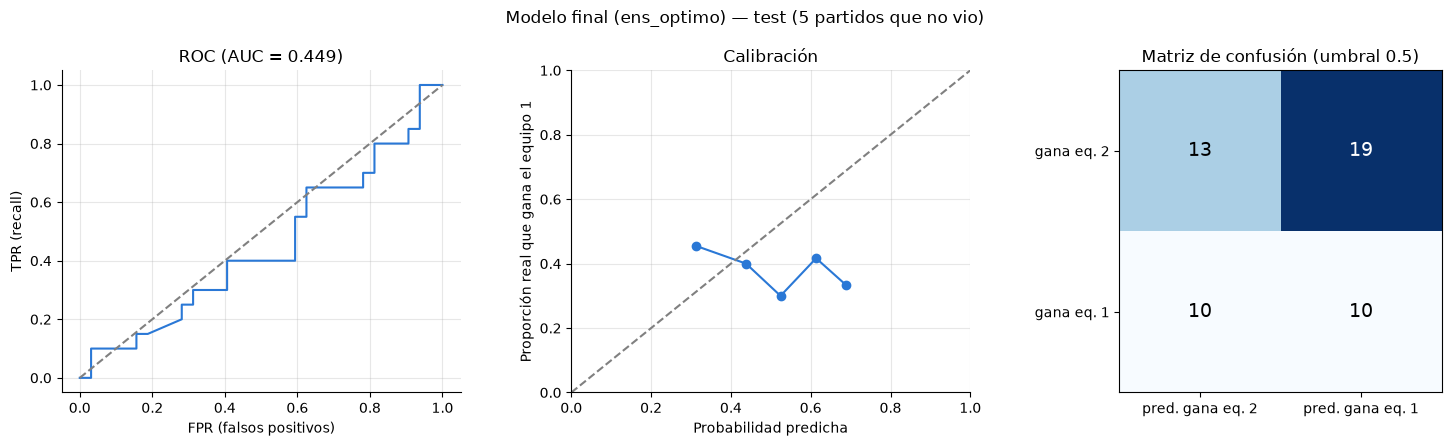

,puntos,gana_equipo_1_real,p_media_modelo_final,p_media_naive
partido,,,,
5,9,0.333,0.351,0.448
10,11,0.364,0.625,0.448
18,10,0.300,0.514,0.448
26,10,0.300,0.453,0.448
29,12,0.583,0.578,0.448


In [83]:
print(classification_report(y_test, (p_test[MODELO_FINAL] >= 0.5).astype(int), target_names=['gana equipo 2', 'gana equipo 1'], zero_division=0))
mod.graficar_evaluacion(y_test, p_test[MODELO_FINAL], f'Modelo final ({MODELO_FINAL}) — test (5 partidos que no vio)')

# Proporción real y predicción media por partido del test
pd.DataFrame({'puntos': y_test.groupby(grupos_test).size(), 'gana_equipo_1_real': y_test.groupby(grupos_test).mean(),
              'p_media_modelo_final': p_test[MODELO_FINAL].groupby(grupos_test).mean(),
              'p_media_naive': p_test['naive'].groupby(grupos_test).mean()}).round(3)

In [84]:
# Bootstrap por partido en el test: se remuestrean los 5 partidos con reemplazo (D48)
rng_test = np.random.default_rng(datos.SEMILLA)
yt, gt = y_test.values, grupos_test.values
partidos_test = np.sort(np.unique(gt))
ids_test = rng_test.integers(0, len(partidos_test), size=(2000, len(partidos_test)))
print(f'Remuestreos distintos (como conjunto de partidos): {len({tuple(sorted(r)) for r in ids_test.tolist()})} de 2.000')


def por_partido(valores):
    return pd.Series(valores).groupby(gt).sum().reindex(partidos_test).values


n_test = por_partido(np.ones(len(yt)))
boot_test = {}
for k, p in p_test.items():
    q = np.clip(p.values, 1e-15, 1 - 1e-15)
    ll = por_partido(-(yt * np.log(q) + (1 - yt) * np.log(1 - q)))
    br = por_partido((q - yt) ** 2)
    boot_test[k] = pd.DataFrame({'log_loss': ll[ids_test].sum(axis=1) / n_test[ids_test].sum(axis=1),
                                 'Brier': br[ids_test].sum(axis=1) / n_test[ids_test].sum(axis=1)})

ic_test = pd.DataFrame({k: {'log_loss': b['log_loss'].mean(), 'log_loss IC95 inf': b['log_loss'].quantile(0.025), 'log_loss IC95 sup': b['log_loss'].quantile(0.975),
                            'Brier': b['Brier'].mean(), 'Brier IC95 inf': b['Brier'].quantile(0.025), 'Brier IC95 sup': b['Brier'].quantile(0.975)}
                        for k, b in boot_test.items()}).T
display(ic_test.round(3))

filas = []
for b in ['naive', 'lasso', 'rf', 'gradient_boosting', 'ens_promedio']:
    d = boot_test[MODELO_FINAL]['log_loss'] - boot_test[b]['log_loss']
    filas.append({'diferencia de log-loss en test': f'{MODELO_FINAL} − {b}', 'observada': resultados_test.loc[MODELO_FINAL, 'log_loss'] - resultados_test.loc[b, 'log_loss'],
                  'IC95 inf': d.quantile(0.025), 'IC95 sup': d.quantile(0.975), '% remuestreos a favor del modelo final': (d < 0).mean() * 100})
pd.DataFrame(filas).set_index('diferencia de log-loss en test').round(3)

Remuestreos distintos (como conjunto de partidos): 121 de 2.000


,log_loss,log_loss IC95 inf,log_loss IC95 sup,Brier,Brier IC95 inf,Brier IC95 sup
naive,0.674,0.658,0.697,0.241,0.233,0.252
lasso,0.750,0.739,0.761,0.277,0.270,0.283
rf,0.741,0.679,0.795,0.273,0.244,0.299
gradient_boosting,0.785,0.714,0.861,0.291,0.257,0.324
ens_promedio,0.747,0.703,0.788,0.276,0.255,0.295
ens_optimo,0.766,0.710,0.819,0.284,0.257,0.307


,observada,IC95 inf,IC95 sup,% remuestreos a favor del modelo final
diferencia de log-loss en test,,,,
ens_optimo − naive,0.092,0.039,0.152,0.00
ens_optimo − lasso,0.017,-0.044,0.079,29.45
ens_optimo − rf,0.025,-0.001,0.048,3.80
ens_optimo − gradient_boosting,-0.020,-0.039,-0.000,98.60
ens_optimo − ens_promedio,0.018,0.001,0.034,1.40


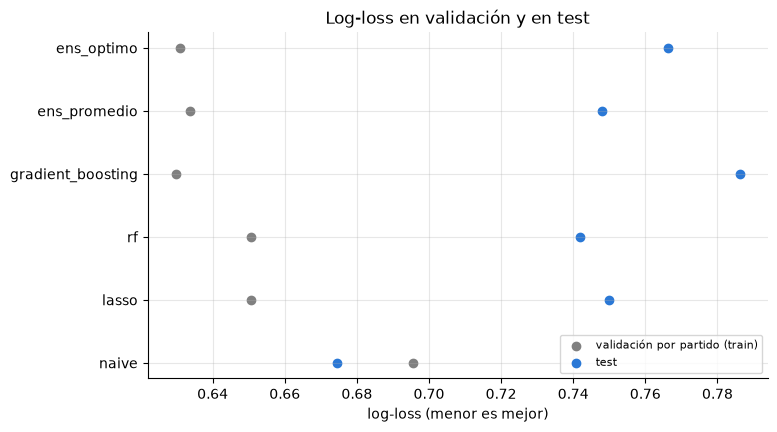

In [85]:
# Validación (20 partidos) contra test (5 partidos): ¿se sostiene el orden de los modelos?
orden_28 = ['naive', 'lasso', 'rf', 'gradient_boosting', 'ens_promedio', 'ens_optimo']
fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(orden_28))
ax.scatter(resultados_test.loc[orden_28, 'log_loss_validacion'], yy, color='gray', label='validación por partido (train)')
ax.scatter(resultados_test.loc[orden_28, 'log_loss'], yy, color='#2a78d6', label='test')
ax.set(yticks=yy, yticklabels=orden_28, xlabel='log-loss (menor es mejor)', title='Log-loss en validación y en test')
ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False); ax.legend(fontsize=8)
plt.show()

### Simetría: ¿da lo mismo quién es el «equipo 1»?
En la fase 4 la misma pareja A puede jugar como equipo 1 o como equipo 2. Como todas las variables son `dif_` (equipo 1 − equipo 2), intercambiar las parejas es cambiar `X` por `−X`. Si el modelo solo mirara las parejas, p(gana el equipo 1 | `X`) + p(gana el equipo 1 | `−X`) daría 1. Cualquier diferencia mide cuánto depende la predicción del lado de la cancha (el equipo 1 siempre está en BOTTOM, sección 1.4) o de la forma del modelo.

In [86]:
modelo_final_train = ajustados_test[MODELO_FINAL]
simetria = {}
for nombre, Xs in [('train', X_train), ('test', X_test)]:
    suma = modelo_final_train.predict_proba(Xs)[:, 1] + modelo_final_train.predict_proba(-Xs)[:, 1]
    simetria[nombre] = pd.Series(suma).describe()[['mean', 'std', 'min', '50%', 'max']]
display(pd.DataFrame(simetria).T.round(3))

# Una pareja contra sí misma (todas las dif_ = 0): debería dar 0,5 si el lado no importara
cero = pd.DataFrame(0.0, index=[0], columns=X_train.columns)
print('p(gana el equipo 1) con todas las dif_ en 0:', {k: round(float(m.predict_proba(cero)[0, 1]), 3) for k, m in ajustados_test.items()})

,mean,std,min,50%,max
train,0.931,0.157,0.619,0.910,1.305
test,0.903,0.154,0.631,0.892,1.207


p(gana el equipo 1) con todas las dif_ en 0: {'naive': 0.448, 'lasso': 0.488, 'rf': 0.547, 'gradient_boosting': 0.641, 'ens_promedio': 0.558, 'ens_optimo': 0.602}


### Modelo para la fase 4 (D49)
Ya reportado el test, el modelo final se reentrena con los 25 partidos (244 puntos), con los mismos hiperparámetros y pesos. Este es el objeto que usa la fase 4: `modelo_fase4.predict_proba(X)` recibe las 19 `dif_` en el orden de `var.VARIABLES_MODELO`.

In [87]:
modelo_fase4 = mod.Ensamblaje(base_ens, pesos_ensamble).fit(X, y)
p_todo = modelo_fase4.predict_proba(X)[:, 1]
print(f'Modelo para la fase 4: {MODELO_FINAL} entrenado con {len(X)} puntos de {grupos.nunique()} partidos; '
      f'modelos con peso > 0: {list(modelo_fase4.ajustados_)}')
print(f'Probabilidades dentro de muestra: de {p_todo.min():.3f} a {p_todo.max():.3f} (mediana {np.median(p_todo):.3f})')

Modelo para la fase 4: ens_optimo entrenado con 244 puntos de 25 partidos; modelos con peso > 0: ['gradient_boosting', 'lasso']
Probabilidades dentro de muestra: de 0.118 a 0.727 (mediana 0.454)


**Resultado**

**En el test, ningún modelo supera al naive.** Es el resultado central de la fase 2:

| Modelo | log-loss test | Brier test | AUC test (juntos / por partido) | log-loss validación |
|---|---|---|---|---|
| naive | **0,674** | **0,241** | 0,500 / 0,500 | 0,696 |
| LASSO | 0,750 | 0,277 | 0,440 / 0,422 | 0,651 |
| RF | 0,742 | 0,273 | 0,432 / 0,384 | 0,651 |
| Gradient Boosting | 0,786 | 0,292 | 0,446 / 0,382 | 0,630 |
| Promedio simple | 0,748 | 0,276 | 0,446 / 0,386 | 0,634 |
| **`ens_optimo` (modelo final, D48)** | 0,766 | 0,284 | 0,449 / 0,377 | 0,631 |

- **El modelo final queda peor que el naive:** `ens_optimo` − naive = +0,092 (IC95 % [0,039; 0,152]; ningún remuestreo favorece al modelo final). En validación era al revés (−0,066).
- **El orden de los modelos no se sostiene.** El de menor log-loss en validación (Gradient Boosting, 0,630) es el peor en test (0,786), y LASSO y RF quedan mejor que los dos que más le apuestan al Gradient Boosting. Dentro de los candidatos, `ens_optimo` mejora al Gradient Boosting solo (−0,020 [−0,039; −0,000]) y queda peor que el promedio simple (+0,018 [0,001; 0,034]).
- **El AUC queda por debajo de 0,5** en todos los modelos, con los puntos juntos y dentro de cada partido. En estos 5 partidos, los puntos a los que el modelo les da más probabilidad no son los que más gana el equipo 1. La curva de calibración es plana: lo que pasa en realidad queda entre 0,30 y 0,45 sin importar lo que prediga el modelo.
- **Por partido:** en los partidos 5 y 29 la probabilidad media del modelo coincide con lo real (0,351 contra 0,333; 0,578 contra 0,583). En el 10 y el 18 sobreestima al equipo 1 (0,625 contra 0,364; 0,514 contra 0,300).
- **Parte de la ventaja del naive es la proporción base.** En el test el equipo 1 gana el 38,5 % de los puntos (44,8 % en train), y el naive, con su 0,448 fijo, ya está cerca de esa proporción. El AUC menor que 0,5, en cambio, no depende de la proporción base: el orden que aprendieron los modelos no se repite en estos partidos.
- **Incertidumbre:** el test tiene 52 puntos de 5 partidos, y el bootstrap por partido solo produce 121 combinaciones distintas de partidos. Los intervalos son gruesos y el resultado depende mucho de qué 5 partidos cayeron en el test. Aun así, es la única medida en partidos que ningún modelo ni ninguna decisión tocó, y no favorece a los modelos.

**Simetría.** El modelo final no es simétrico. Al intercambiar las parejas (`X` → `−X`), p + p' da en promedio 0,931 en train y 0,903 en test, con valores entre 0,62 y 1,31. Con todas las `dif_` en 0 (dos parejas iguales), `ens_optimo` le da 0,602 al equipo 1. El Gradient Boosting solo le da 0,641, LASSO 0,488 y el naive 0,448 (la proporción del train). La predicción depende de quién se llame «equipo 1», y la fase 4 no puede usarla tal cual para comparar parejas.

**Modelo para la fase 4 (D49).** `modelo_fase4` es `ens_optimo` reentrenado con los 244 puntos de los 25 partidos (Gradient Boosting 0,745 + LASSO 0,255; RF no entra porque su peso es 0). Sus probabilidades dentro de muestra van de 0,118 a 0,727.

**Cierre de la fase 2.** El procedimiento quedó completo y sin fugas:
- partición por partido;
- selección de variables, hiperparámetros y ensamblaje con validación por partido;
- regla del modelo final fijada antes del test;
- un solo uso del test.

La evidencia, sin embargo, no respalda que el modelo prediga el ganador del punto mejor que la proporción base en partidos nuevos. La mejora que se veía en validación (−0,066 contra el naive) no se repitió en el test (+0,092). Lo que se puede afirmar con estos datos es que, en validación, el nivel de pádel sumado (`dif_suma_nivel_padel`) es la variable más importante en todos los modelos que reportan importancia o coeficientes. Que esa relación sirva para predecir partidos nuevos no quedó demostrado. Cómo seguir en la fase 4 con este resultado (y con la asimetría) se decide con el equipo; las opciones están en los pendientes del README. Cualquier cambio de modelo hecho ahora ya no puede volver a medirse con este test.


# Fase 3 — Distribuciones — *pendiente*

- Una distribución empírica por variable aleatoria y por jugador. Los valores fijos (estatura, peso, nivel) entran como atributos y no se modelan como distribución.
- Se compara el bootstrap empírico contra una distribución paramétrica ajustada, teniendo en cuenta las pocas observaciones por jugador.

### Nota para el equipo: qué hereda la fase 3 de la 1.11
- **Las 19 variables (D34) se arman desde cada jugador** con `var.combinar_pareja` (error 0 en los 244 puntos). La fase 3 tiene que entregar, por jugador, los valores con los que se arman: `atacante`, `prof_media_m`, `prof_sd_m`, `pct_en_su_lado`, `vel_p90`, `area_m2`, `pct_quieto`, `rafagas_por_min` y las fijas de `jugadores`.
- **Pregunta abierta:** ¿los valores de cada jugador se sortean por separado o por punto completo? En un punto real los dos compañeros y el rival juegan a la vez, así que sortearlos por separado podría romper esa relación. Se decide con el equipo antes de empezar.
- **`atacante` es 0 o 1 en cada punto:** la distribución de cada jugador es la proporción de sus puntos en que fue atacante.
- **Las fijas no se sortean:** estatura, IMC, nivel, tiempo jugando, otra raqueta, frecuencia de deporte y género son atributos del jugador.

# Fase 4 — Simulación — *pendiente*

- Se simulan combinaciones de parejas y partidos muestreando las distribuciones de la fase 3 y evaluándolas con el modelo de la fase 2.
- Resultado esperado: un ranking de parejas por probabilidad media de ganar contra el resto, con intervalos de incertidumbre.

### Nota para el equipo: qué hereda la fase 4 de la 1.11 y de la fase 2
- **Armar un partido simulado:** se sortean los valores de los 4 jugadores (fase 3), se arma cada pareja con `var.combinar_pareja`, se calcula la `dif_` (pareja 1 − pareja 2) y el modelo final de la fase 2 da p(gana el punto la pareja 1).
- **`pct_en_su_lado` depende del lado asignado:** la simulación tiene que decidir quién juega drive (RIGHT) y quién revés (LEFT) en cada pareja.
- **Simetría:** al intercambiar las parejas, todas las `dif_` cambian de signo. Hay que revisar que p(A gana a B) + p(B gana a A) ≈ 1 con el modelo elegido.
- **Del punto al partido:** los partidos son a 7 puntos; la probabilidad de ganar el partido se obtiene simulando puntos hasta que una pareja llegue a 7.

---
<a id="anexo-a"></a>
# Anexo A — Registro de decisiones

El registro completo (D1 en adelante) es una sola tabla, en la sección **Registro de decisiones** del [README](../README.md#registro-de-decisiones). Cada sección de este notebook cita sus decisiones con su código `D#`.

# Anexo B — Supuestos y pendientes

La lista vigente está en la sección **Supuestos y pendientes** del [README](../README.md#supuestos-y-pendientes).

# Anexo C — Tablas derivadas

Diccionario de columnas: la parte B de [`docs/diccionario.md`](../docs/diccionario.md).

In [88]:
def leer_interim(f):
    return pd.read_parquet(f) if f.suffix == '.parquet' else pd.read_csv(f, encoding='utf-8-sig', low_memory=False)

display(pd.DataFrame([
    {'archivo': f'{f.parent.name}/{f.name}', 'filas': len(t := leer_interim(f)), 'columnas': t.shape[1],
     'MB': round(f.stat().st_size / 1e6, 1)}
    for f in sorted([*datos.DATA_INTERIM.glob('*.csv'), *datos.DATA_INTERIM.glob('*.parquet'), *datos.DATA_PROCESSED.glob('*.csv')])
]))

,archivo,filas,columnas,MB
0,interim/equivalencias_nombres.csv,89,5,0.0
1,interim/filtros_variables.csv,83,3,0.0
2,interim/identidades_video.csv,1201,21,0.2
3,interim/jugadores.csv,32,23,0.0
4,interim/parejas_punto.csv,244,247,0.5
5,interim/participaciones.csv,1132,44,0.3
6,interim/puntos.csv,287,29,0.0
7,interim/video_limpio.parquet,705888,42,78.1
8,processed/tabla_modelo.csv,244,164,0.3
